# Main analysis: Bayesian cumulative-logit models of calling intensity

Reproduces the main results of *Non-linear microclimatic constraints on calling activity in two
terrestrial breeding frogs of the Yungas Andean forests* (Ash, Boullhesen, Bonnaffé & Akmentins).

| Paper item | Section of this notebook | Output |
|---|---|---|
| Fig. S5 (advertisement-call spectrograms) | 0.1 | `figures/FigS5_*` |
| Results 3.1 (data summary) | 2.1 | `tables/Results3.1_data_summary.csv` |
| Table 1 (model comparison, PSIS-LOO) | 4.1 | `tables/Table1_model_comparison.csv` |
| Table 2 (posterior summaries, `model_4_ord`) | 4.2 | `tables/Table2_posterior_summaries.csv` |
| Fig. S1 (coefficients across models) | 5.1 | `figures/FigS1_*` |
| Table S3 (prior sensitivity) | 5.5 | `tables/TableS3_prior_sensitivity.*` |
| Table S1 (convergence diagnostics) | 5.6 | `tables/TableS1_convergence_diagnostics.csv` |
| Fig. S2 (posterior predictive checks) | 6 | `figures/FigS2_posterior_predictive_checks.*` |
| Fig. 2 (response curves) | 7 | `figures/Fig2_top_*`, `figures/Fig2_bottom_*` |
| Fig. S3 (temperature × humidity surface) | 7 | `figures/FigS3_response_surface_temp_rh.*` |
| Fig. 1 (seasonal and diel calling) | 9 | `figures/Fig1_top_*`, `figures/Fig1_bottom_*` |
| Results 3.4 (temperature optima) | 9.2 | `tables/Results3.4_temperature_optima.csv` |
| Text statistics (residual autocorrelation, diel/seasonal PPC, in-season exceedance) | 10 | `tables/Text_*.csv` |

Table S2 (blocked cross-validation) is in `03_blocked_cross_validation.ipynb`; Table S4 and Fig. S4
(Fourier harmonics) are in `02_fourier_harmonics_sensitivity.ipynb`.

**Run time.** Every Bayesian model is fitted once and cached in `outputs/` (see `frogcall.py`). On a
first run this notebook samples 16 models (≈ 2–5 min each); afterwards it loads them from the cache.
`python fit_all_models.py --jobs 4` fills the cache in parallel beforehand.

1. Standardize T and RH.

2. Fit the pre-specified candidate models.

3. Compare models using PSIS-LOO or K-fold CV.

4. Use posterior contrasts to test each hypothesis directly.

5. Run OC_bin vs OC_ord as a sensitivity/encoding comparison.

6. Report model comparison and posterior effect evidence together.

## 0. Setup & configuration

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
import warnings


from patsy import dmatrix
from patsy.builtins import Q
from statsmodels.miscmodels.ordinal_model import OrderedModel

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

np.set_printoptions(linewidth=150)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 60)
pd.set_option('max_colwidth', 400)


# ══ FIGURE STYLE TOGGLES ═════════════════════════════════════════════════════
# Every figure in this notebook reads its font sizes and line widths from here.
# Scale everything at once with FONT_SCALE / LINE_SCALE, or edit one entry.
FONT_SCALE = 1.0    # global multiplier on all font sizes below
LINE_SCALE = 1.0    # global multiplier on all line widths below

FS_TITLE      = 20 * FONT_SCALE   # axes titles
FS_SUPTITLE   = 21 * FONT_SCALE   # figure-level titles
FS_LABEL      = 21 * FONT_SCALE   # x / y axis labels
FS_TICK       = 15 * FONT_SCALE   # tick labels
FS_LEGEND     = 16 * FONT_SCALE   # legend entries
FS_CBAR_LABEL = 18 * FONT_SCALE   # colourbar labels
FS_CBAR_TICK  = 15 * FONT_SCALE   # colourbar tick labels

LW_MAIN      = 2.8 * LINE_SCALE   # main curves (posterior means, species series)
LW_SECONDARY = 2.2 * LINE_SCALE   # secondary curves (temperature / humidity series)
LW_AUX       = 1.6 * LINE_SCALE   # reference, percentile and contour lines
LW_SPINE     = 1.2 * LINE_SCALE   # axes spines and tick marks
LW_GRID      = 1.0 * LINE_SCALE   # grid lines
CAPSIZE      = 5.0 * LINE_SCALE   # error-bar cap size
MS_RUG       = 7.0 * LINE_SCALE   # rug tick length
MEW_RUG      = 1.0 * LINE_SCALE   # rug tick thickness
MS_SCATTER   = 5.0 * LINE_SCALE   # scatter marker area (points²)
# ═════════════════════════════════════════════════════════════════════════════

# ── Plot style (adapted) ─────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": FS_TICK,
    "axes.titlesize": FS_TITLE,
    "axes.labelsize": FS_LABEL,
    "figure.titlesize": FS_SUPTITLE,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "legend.fontsize": FS_LEGEND,
    "figure.figsize": (14, 6),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": LW_GRID,
    "lines.linewidth": LW_MAIN,
    "axes.linewidth": LW_SPINE,
    "xtick.major.width": LW_SPINE,
    "ytick.major.width": LW_SPINE,
    "axes.spines.top": False,
    "axes.spines.right": True,
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "STIXGeneral", "DejaVu Serif", "Times New Roman"],
    "mathtext.fontset": "cm",
    # cmr10 has no U+2212 glyph; use the ASCII hyphen so negative
    # tick labels render as -0.10 rather than a missing-glyph box.
    "axes.unicode_minus": False,
})

COLORS = {
    "gastro": "#1f77b4",
    "oreo": "#ff7f0e",
    "both": "#2ca02c",
    "temp": "#d62728",
    "rh": "#9467bd",
}

SPECIES = ["Gastrotheca chrysosticta", "Oreobates berdemenos"]
SP_SHORT = {
    "Gastrotheca chrysosticta": "G. chrysosticta",
    "Oreobates berdemenos": "O. berdemenos",
}
SP_COLOR = {
    "Gastrotheca chrysosticta": COLORS["gastro"],
    "Oreobates berdemenos": COLORS["oreo"],
}


def mathit(s: str) -> str:
    """Render a Latin binomial (or any string) in maths italic.

    cmr10 - this notebook's serif face - ships no italic face, so a plain
    fontstyle="italic" is silently ignored; species names have to go through
    mathtext to actually come out italic in the Computer Modern family.
    """
    return r"$\mathit{" + s.replace(" ", r"\ ") + "}$"

import frogcall as fc

PLOT_DIR = fc.FIG_DIR

# Every figure is saved under its number in the paper.
PAPER_FIGURES = {
    "seasonal_calling_environment": "Fig1_top_seasonal_calling_environment",
    "diel_rose_calling":            "Fig1_bottom_diel_rose_calling",
    "response_curves_temperature":  "Fig2_top_response_curves_temperature",
    "response_curves_humidity":     "Fig2_bottom_response_curves_humidity",
    "ppc_composite_2x4_model4ord":  "FigS2_posterior_predictive_checks",
    "response_surface_temp_rh":     "FigS3_response_surface_temp_rh",
}


def savefig(fig, name):
    """Save a figure into figures/ as PDF."""
    fc.save_figure(fig, PAPER_FIGURES[name])

print("Setup complete. Plots will be saved to:", PLOT_DIR.resolve())

Setup complete. Plots will be saved to: /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/figures


## 0.1 Example call spectrograms

One isolated advertisement call per species, from the clips in `data/audio/` (44.1 kHz, mono, 16-bit).
Each file name gives the species, the recording (date and start time), the channel and the call's
position in the original recording:

| Species | File |
|---|---|
| *G. chrysosticta* | `gastrotheca_20191013_200000_ch1_49.49s.wav` |
| *O. berdemenos* | `oreobates_20181127_200000_ch0_41.30s.wav` |

STFT: Hann window of 512 samples (11.6 ms), 50 % overlap (256 samples) and a 512-point DFT
(86 Hz bins). The frequency axis is cut at `F_MAX_KHZ`; almost all call energy lies below 8 kHz.
The *O. berdemenos* clip is trimmed by 0.25 s at each end (`TRIM_S`) to about 2 s.

  saved figures/FigS5_call_spectrogram_gastrotheca.pdf
    (gastrotheca_20191013_200000_ch1_49.49s.wav: 44100 Hz, 1.98 s)


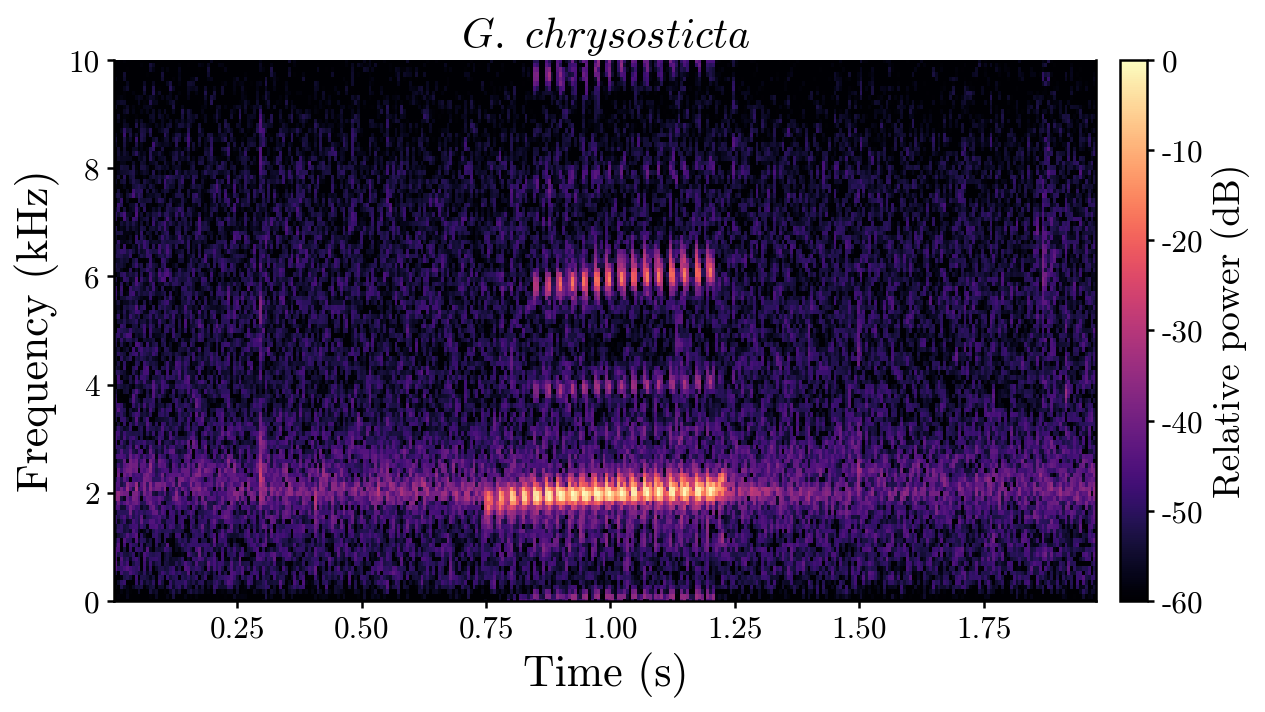

  saved figures/FigS5_call_spectrogram_oreobates.pdf
    (oreobates_20181127_200000_ch0_41.30s.wav: 44100 Hz, 2.01 s)


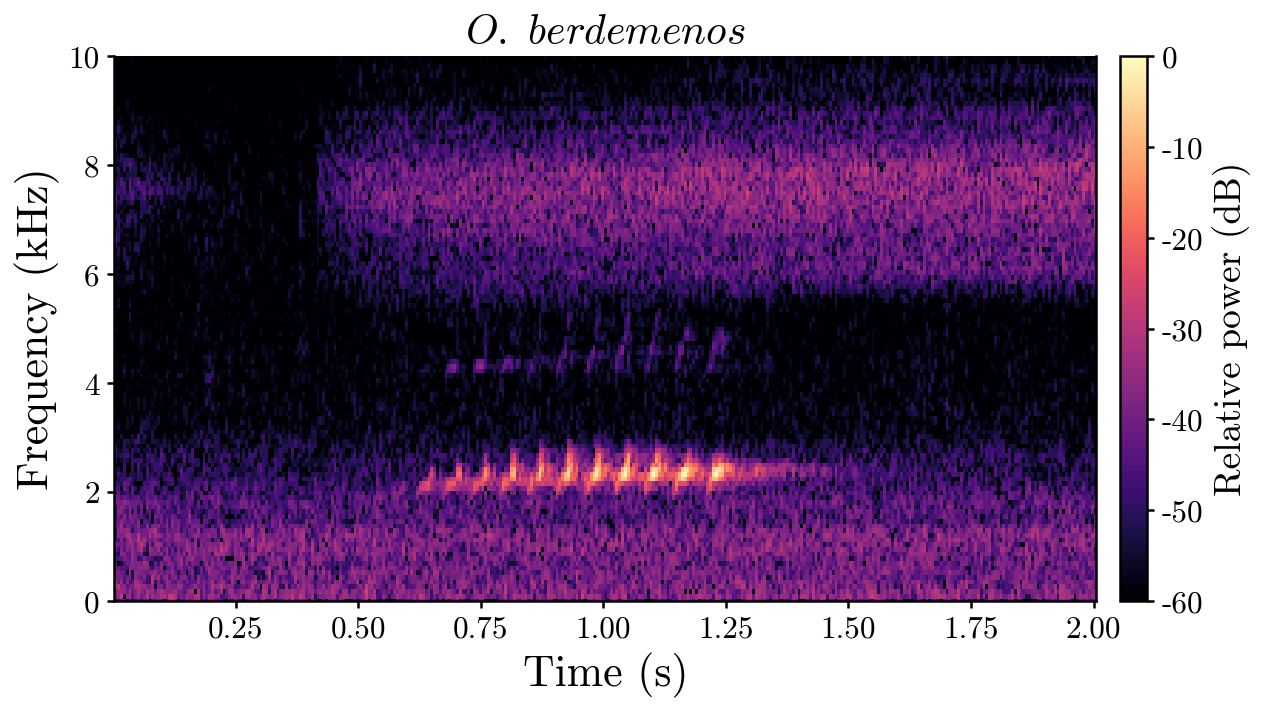

In [3]:
import scipy.io.wavfile as wavfile
from scipy.signal import spectrogram
from IPython.display import Audio, display

WAV_DIR = fc.AUDIO_DIR

# One clip per species; the file name starts with the genus.
CALL_CLIPS = {sp: next(WAV_DIR.glob(f"{sp.split()[0].lower()}_*.wav")) for sp in SPECIES}

N_WIN        = 512   # Hann window (samples); 11.6 ms at 44.1 kHz
N_OVERLAP    = 256   # 50 % overlap
N_FFT        = 512   # DFT length
DYN_RANGE_DB = 60    # colour scale: max down to max - 60 dB
F_MAX_KHZ    = 10    # upper limit of the frequency axis
TRIM_S       = {"Oreobates berdemenos": 0.25}   # seconds cut from each end of the clip


def call_spectrogram(path, trim_s=0.0, channel=0):
    sr, x = wavfile.read(path)
    if x.ndim > 1:
        x = x[:, channel]
    n_trim = int(round(trim_s * sr))
    x = x[n_trim:len(x) - n_trim]
    x = x.astype(float)
    x -= x.mean()
    f, t, Sxx = spectrogram(x, fs=sr, window="hann", nperseg=N_WIN,
                            noverlap=N_OVERLAP, nfft=N_FFT, scaling="density", mode="psd")
    S_db = 10 * np.log10(Sxx + 1e-12)
    return f, t, S_db - S_db.max(), sr, x


for sp, path in CALL_CLIPS.items():
    f, t, S_db, sr, clip = call_spectrogram(path, TRIM_S.get(sp, 0.0))
    fig, ax = plt.subplots(figsize=(9, 5))
    mesh = ax.pcolormesh(t, f / 1000, S_db, shading="auto", cmap="magma",
                         vmin=-DYN_RANGE_DB, vmax=0, rasterized=True)
    ax.set_ylim(0, min(F_MAX_KHZ, sr / 2 / 1000))
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Frequency (kHz)")
    ax.set_title(mathit(SP_SHORT[sp]))
    ax.grid(False)
    cbar = fig.colorbar(mesh, ax=ax, pad=0.02)
    cbar.set_label("Relative power (dB)", fontsize=FS_CBAR_LABEL)
    cbar.ax.tick_params(labelsize=FS_CBAR_TICK)
    fig.tight_layout()
    fc.save_figure(fig, f"FigS5_call_spectrogram_{sp.split()[0].lower()}")
    print(f"    ({path.name}: {sr} Hz, {len(clip) / sr:.2f} s)")
    plt.show()
    display(Audio(clip, rate=sr))   # player for the plotted clip

## 1. Load data

In [4]:
# Hourly calling indices (0-3) for both species with logger temperature and relative humidity
DATA_PATH = fc.DATA_PATH

df = pd.read_csv(DATA_PATH)
df["DateTime"] = pd.to_datetime(df["DateTime"], errors="coerce")
df = df.set_index("DateTime").sort_index()

print(f"Shape: {df.shape}")
print(f"Date range: {df.index.min()} → {df.index.max()}")
df.head()

Shape: (13257, 8)
Date range: 2018-09-02 00:00:00 → 2020-07-18 23:00:00


,Date,Month,Day,hour,Temp,RH%,Gastrotheca chrysosticta,Oreobates berdemenos
DateTime,,,,,,,,
2018-09-02 00:00:00,2018-09-02,9,245,0,4.553,100.0,0,0
2018-09-02 01:00:00,2018-09-02,9,245,1,4.051,100.0,0,0
2018-09-02 02:00:00,2018-09-02,9,245,2,4.553,100.0,0,0
2018-09-02 03:00:00,2018-09-02,9,245,3,3.550,100.0,0,0
2018-09-02 04:00:00,2018-09-02,9,245,4,3.048,100.0,0,0


## 2. Data prep & normalization
Normalize temperature and humidity time series (z-scores), and define the "other calling" variable in both binary and ordinal form.

In [5]:
import itertools
import statsmodels.api as sm
import statsmodels.formula.api as smf

TEMP_COL = "Temp"
RH_COL = "RH%"

# Change this if you'd like to fit only one species
RESPONSE_COLS = SPECIES


def zscore(series: pd.Series) -> pd.Series:
    return (series - series.mean()) / series.std(ddof=0)


def add_fourier_terms(df_in: pd.DataFrame) -> pd.DataFrame:
    d = df_in.copy()
    two_pi = 2 * np.pi
    d["sin_h1"] = np.sin(two_pi * d["hour"] / 24.0)
    d["cos_h1"] = np.cos(two_pi * d["hour"] / 24.0)
    d["sin_h2"] = np.sin(2 * two_pi * d["hour"] / 24.0)
    d["cos_h2"] = np.cos(2 * two_pi * d["hour"] / 24.0)
    d["sin_d1"] = np.sin(two_pi * d["doy"] / 366.0)
    d["cos_d1"] = np.cos(two_pi * d["doy"] / 366.0)
    d["sin_d2"] = np.sin(2 * two_pi * d["doy"] / 366.0)
    d["cos_d2"] = np.cos(2 * two_pi * d["doy"] / 366.0)
    return d


def prepare_species_df(df_in: pd.DataFrame, response_col: str) -> pd.DataFrame:
    df_local = df_in.copy()
    df_local["temp_z"] = zscore(pd.to_numeric(df_local[TEMP_COL], errors="coerce"))
    df_local["rh_z"] = zscore(pd.to_numeric(df_local[RH_COL], errors="coerce"))

    df_local["hour"] = df_local.index.hour
    df_local["doy"] = df_local.index.dayofyear
    df_local = add_fourier_terms(df_local)

    other_cols = [c for c in SPECIES if c != response_col]
    if not other_cols:
        raise ValueError("SPECIES must contain at least 2 species for other-calling variables.")
    other_col = other_cols[0]

    df_local["other_calling_ord"] = pd.to_numeric(df_local[other_col], errors="coerce")
    df_local["other_calling_bin"] = (df_local["other_calling_ord"] > 0).astype(int)
    # lag-1 of other calling (previous timepoint). keep as numeric so dropna will remove the first row.
    df_local["other_calling_lag1"] = df_local["other_calling_bin"].shift(1)

    df_local["response_raw"] = pd.to_numeric(df_local[response_col], errors="coerce")

    model_cols = [
        "response_raw",
        "temp_z",
        "rh_z",
        "other_calling_ord",
        "other_calling_bin",
        "other_calling_lag1",
        "hour",
        "doy",
        "sin_h1",
        "cos_h1",
        "sin_h2",
        "cos_h2",
        "sin_d1",
        "cos_d1",
        "sin_d2",
        "cos_d2",
    ]
    df_model = df_local[model_cols].dropna()

    # Ordered response for ordinal cumulative-link models
    response_cat = pd.Categorical(df_model["response_raw"], ordered=True)
    df_model["response_code"] = response_cat.codes
    df_model["response_cat"] = response_cat

    return df_model


species_data = {sp: prepare_species_df(df, sp) for sp in RESPONSE_COLS}
print({sp: d.shape for sp, d in species_data.items()})

{'Gastrotheca chrysosticta': (11302, 18), 'Oreobates berdemenos': (11302, 18)}


In [6]:
# ── Normalization params + prediction helpers ─────────────────────────────────
# Back-transform z-scores to original units for axis labels
_temp_raw = pd.to_numeric(df[TEMP_COL], errors="coerce")
_rh_raw   = pd.to_numeric(df[RH_COL],   errors="coerce")
SP_NORM = {sp: {
    "temp_mean": float(_temp_raw.mean()), "temp_std": float(_temp_raw.std(ddof=0)),
    "rh_mean":   float(_rh_raw.mean()),   "rh_std":   float(_rh_raw.std(ddof=0)),
} for sp in SPECIES}

# Fixed hour (midnight) and day-of-year per species for response-curve plots
SP_FIXED = {
    "Gastrotheca chrysosticta": {"hour": 0, "doy": 240},
    "Oreobates berdemenos":     {"hour": 0, "doy": 310},
}


def _fourier_row(hour: float, doy: float) -> dict:
    two_pi = 2 * np.pi
    return {
        "sin_h1": np.sin(two_pi * hour / 24),     "cos_h1": np.cos(two_pi * hour / 24),
        "sin_h2": np.sin(2 * two_pi * hour / 24), "cos_h2": np.cos(2 * two_pi * hour / 24),
        "sin_d1": np.sin(two_pi * doy / 366),     "cos_d1": np.cos(two_pi * doy / 366),
        "sin_d2": np.sin(2 * two_pi * doy / 366), "cos_d2": np.cos(2 * two_pi * doy / 366),
    }


def make_grid_df(sp: str, temp_z_vals, rh_z_vals, other_calling_ord: float = 0.0) -> pd.DataFrame:
    """Build a prediction DataFrame on a grid; bambi handles quadratic/interaction terms."""
    hour = SP_FIXED[sp]["hour"]
    doy  = SP_FIXED[sp]["doy"]
    n    = len(temp_z_vals)
    f    = _fourier_row(hour, doy)
    d = {
        "temp_z":            np.asarray(temp_z_vals, dtype=float),
        "rh_z":              np.asarray(rh_z_vals,   dtype=float),
        "other_calling_ord": np.full(n, other_calling_ord, dtype=float),
        **{k: np.full(n, v) for k, v in f.items()},
        "response_cat": pd.Categorical(
            np.zeros(n, dtype=int), categories=[0, 1, 2, 3], ordered=True
        ),
    }
    return pd.DataFrame(d)


def predict_ey_draws(bmb_model, idata, grid_df) -> np.ndarray:
    """
    Return (n_draws, n_grid) array of E[Y|x, beta_draw] — the conditional
    expectation under each posterior draw.  Percentiles across draws give
    credible intervals on the response curve (not posterior-predictive
    intervals for individual observations).

    Uses kind="response_params" so bambi computes P(Y=k | x, beta_draw) per draw
    and stores them in the posterior group (cumulative family specific).
    E[Y | x, beta_draw] = sum_k  k * P(Y=k | x, beta_draw).
    """
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        idata_pred = bmb_model.predict(
            idata, data=grid_df, kind="response_params", inplace=False
        )

    # response_params are added to the posterior group (not posterior_predictive)
    post_ds = idata_pred["posterior"].ds

    # Find the probability variable: shape (chain, draw, __obs__, response_levels_dim)
    # It is the only 4-D variable that has the "__obs__" observation dimension.
    p_var = next(
        v for v in post_ds.data_vars
        if post_ds[v].ndim == 4 and "__obs__" in post_ds[v].dims
    )
    arr = post_ds[p_var].values  # (chains, draws, n_obs, n_cats)
    n_c, n_d = arr.shape[0], arr.shape[1]
    probs = arr.reshape(n_c * n_d, arr.shape[2], arr.shape[3])  # (n_draws, n_obs, n_cats)

    # E[Y] = sum_k k * P(Y=k)
    cats = np.arange(probs.shape[-1], dtype=float)              # [0, 1, 2, 3]
    return (probs * cats[np.newaxis, np.newaxis, :]).sum(axis=-1)  # (n_draws, n_obs)


print("SP_NORM and prediction helpers defined.")
print({sp: {k: f"{v:.3f}" for k, v in norm.items()} for sp, norm in SP_NORM.items()})

SP_NORM and prediction helpers defined.
{'Gastrotheca chrysosticta': {'temp_mean': '15.521', 'temp_std': '5.033', 'rh_mean': '89.389', 'rh_std': '15.923'}, 'Oreobates berdemenos': {'temp_mean': '15.521', 'temp_std': '5.033', 'rh_mean': '89.389', 'rh_std': '15.923'}}


### 2.1 Data summary (Results, section 3.1)

In [7]:
# ── Numbers quoted in Results 3.1 ────────────────────────────────────────────
# Each statistic is given for the 11,302 analysed hours (rows with temperature AND humidity,
# used in every model) and for all 13,257 annotated hours (each variable where present).
_rows = []
_ana_idx = species_data[SPECIES[0]].index
assert all(species_data[sp].index.equals(_ana_idx) for sp in SPECIES)
_add = lambda k, ana, allh="": _rows.append({"quantity": k, "analysed hours": ana,
                                             "all annotated hours": allh})

_add("Hours", len(_ana_idx), len(df))
_add("First hour", str(_ana_idx.min()), str(df.index.min()))
_add("Last hour", str(_ana_idx.max()), str(df.index.max()))
_add("Last hour with relative humidity", "",
     str(pd.to_numeric(df[RH_COL], errors="coerce").dropna().index.max()))
for sp in SPECIES:
    y_a, y_all = species_data[sp]["response_raw"], pd.to_numeric(df[sp])
    _add(f"{SP_SHORT[sp]}: % hours with no calling (index 0)",
         round(100 * (y_a == 0).mean(), 1), round(100 * (y_all == 0).mean(), 1))
    _add(f"{SP_SHORT[sp]}: % hours with a full chorus (index 3)",
         round(100 * (y_a == 3).mean(), 1), round(100 * (y_all == 3).mean(), 1))
_both = (df[SPECIES[0]] > 0) & (df[SPECIES[1]] > 0)
_add("% hours with both species calling", round(100 * _both.loc[_ana_idx].mean(), 2),
     round(100 * _both.mean(), 2))
for col, lab in ((TEMP_COL, "Temperature (°C)"), (RH_COL, "Relative humidity (%)")):
    v_a, v_all = pd.to_numeric(df.loc[_ana_idx, col]), pd.to_numeric(df[col], errors="coerce").dropna()
    for stat, f in (("min", lambda v: v.min()), ("max", lambda v: v.max()),
                    ("mean", lambda v: v.mean()), ("SD", lambda v: v.std(ddof=0))):
        _add(f"{lab} {stat}", round(float(f(v_a)), 1), round(float(f(v_all)), 1))
_T, _RH = pd.to_numeric(df.loc[_ana_idx, TEMP_COL]), pd.to_numeric(df.loc[_ana_idx, RH_COL])
_add("Pearson r, temperature vs relative humidity", round(np.corrcoef(_T, _RH)[0, 1], 2))

data_summary = pd.DataFrame(_rows)
data_summary.to_csv(fc.TABLE_DIR / "Results3.1_data_summary.csv", index=False)
data_summary

,quantity,analysed hours,all annotated hours
0,Hours,11302,13257
1,First hour,2018-09-02 01:00:00,2018-09-02 00:00:00
2,Last hour,2019-12-16 23:00:00,2020-07-18 23:00:00
3,Last hour with relative humidity,,2019-12-16 23:00:00
4,G. chrysosticta: % hours with no calling (index 0),91.0,91.3
5,G. chrysosticta: % hours with a full chorus (index 3),2.2,2.0
6,O. berdemenos: % hours with no calling (index 0),93.2,94.1
7,O. berdemenos: % hours with a full chorus (index 3),0.8,0.7
8,% hours with both species calling,0.88,0.75
9,Temperature (°C) min,0.2,0.2


## 3. Candidate models

The pre-specified nested ladder (no term selection): `model_0` Fourier terms only; `model_1` + temperature
and humidity; `model_2` + their quadratics; `model_3` + their interaction; `model_4_bin` / `model_4_ord` /
`model_4_lag1` + heterospecific calling (binary, ordinal, or lagged by one hour). The cell below fits each
model once by maximum likelihood (`statsmodels`); this defines the formulas (`model_results`) used for the
Bayesian fits in Section 4.

In [8]:
from typing import Dict, List, Tuple

ORDINAL_DISTR = "logit"


def bic_from_result(res) -> float:
    k = len(res.params)
    return float(-2 * res.llf + k * np.log(res.nobs))


def build_design_formula(terms: List[str]) -> str:
    if not terms:
        return "0 + 1"
    return "0 + " + " + ".join(terms)


def parse_terms(formula: str) -> List[str]:
    rhs = formula.split("~", 1)[1]
    return [t.strip() for t in rhs.split("+") if t.strip() and t.strip() not in {"1", "0"}]


def all_subsets(terms: List[str]) -> List[Tuple[str, ...]]:
    subsets = []
    for r in range(len(terms) + 1):
        subsets.extend(list(itertools.combinations(terms, r)))
    return subsets


def fit_ordinal(formula: str, df_fit: pd.DataFrame):
    design_formula = build_design_formula(parse_terms(formula))
    X = dmatrix(design_formula, df_fit, return_type="dataframe")
    y = df_fit["response_code"].astype(int)
    model = OrderedModel(endog=y, exog=X, distr=ORDINAL_DISTR)
    res = model.fit(method="bfgs", disp=False)
    return res


def evaluate_best_bic(df_fit: pd.DataFrame, required_terms: List[str], optional_terms: List[str]) -> Tuple[str, object]:
    best = None
    best_res = None
    best_formula = None

    for subset in all_subsets(optional_terms):
        terms = required_terms + list(subset)
        formula = "response_code ~ " + " + ".join(terms)
        res = fit_ordinal(formula, df_fit)
        bic = bic_from_result(res)
        if best is None or bic < best:
            best = bic
            best_res = res
            best_formula = formula

    return best_formula, best_res


def pvalue_stars(p: float) -> str:
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    if p < 0.1:
        return "."
    return ""


def is_threshold(term: str) -> bool:
    return "/" in term


def effect_size_label() -> str:
    return "OR"


def summarize_ordinal(res, model_name: str, species: str) -> pd.DataFrame:
    conf = res.conf_int()
    table = pd.DataFrame(
        {
            "model": model_name,
            "species": species,
            "term": res.params.index,
            "estimate": res.params.values,
            "std_error": res.bse.values,
            "p_value": res.pvalues.values,
        }
    )
    table["stars"] = table["p_value"].apply(pvalue_stars)
    table["ci_lower"] = conf[0].values
    table["ci_upper"] = conf[1].values
    table["is_threshold"] = table["term"].apply(is_threshold)
    table[effect_size_label()] = np.where(
        table["is_threshold"],
        np.nan,
        np.exp(table["estimate"]),
    )
    return table


model_results: Dict[str, Dict[str, object]] = {}
summary_tables = []
selection_rows = []

fourier_terms = [
    "sin_h1",
    "cos_h1",
    "sin_h2",
    "cos_h2",
    "sin_d1",
    "cos_d1",
    "sin_d2",
    "cos_d2",
]


# M0 - FOURIER ONLY
# M1 - FOURIER + TEMP + RH
# M2 - FOURIER + TEMP + RH + T**2 + RH**2
# M3 - FOURIER + T +RH +T**2 + RH**2 + T:RH
# M4_BIN/ORD/LAG1 (TEST ALL 3 TO FIND BEST PREDICTOR) - FOURIER +T+RH+T**2+RH**2+T:RH +OC_BIN/ORD/LAG_1


for sp, df_sp in species_data.items():
    # Model 0:  Fourier terms 
    base_terms = fourier_terms
    m0_formula, m0_res = evaluate_best_bic(df_sp, base_terms, [])
    m0_bic = bic_from_result(m0_res)
    model_results.setdefault(sp, {})["model_0"] = (m0_formula, m0_res)
    selection_rows.append({"species": sp, "model": "model_0", "formula": m0_formula, "bic": bic_from_result(m0_res)})
    summary_tables.append(summarize_ordinal(m0_res, "model_0", sp))

    # M1 - FOURIER + TEMP + RH
    m1_formula, m1_res = evaluate_best_bic(df_sp, base_terms + ["temp_z", "rh_z"], [])
    m1_bic = bic_from_result(m1_res)
    model_results.setdefault(sp, {})["model_1"] = (m1_formula, m1_res)
    selection_rows.append({"species": sp, "model": "model_1", "formula": m1_formula, "bic": bic_from_result(m1_res)})
    summary_tables.append(summarize_ordinal(m1_res, "model_1", sp))

    # M2 - FOURIER + TEMP + RH + T**2 + RH**2
    quad_terms = ["I(temp_z ** 2)", "I(rh_z ** 2)"]
    m2_formula, m2_res = evaluate_best_bic(df_sp, base_terms + ["temp_z", "rh_z"] + quad_terms,[])
    m2_bic = bic_from_result(m2_res)
    model_results.setdefault(sp, {})["model_2"] = (m2_formula, m2_res)
    selection_rows.append({"species": sp, "model": "model_2", "formula": m2_formula, "bic": bic_from_result(m2_res)})
    summary_tables.append(summarize_ordinal(m2_res, "model_2", sp))

    # M3 - FOURIER + T +RH +T**2 + RH**2 + T:RH
    interaction_terms = ["temp_z:rh_z"]
    m3_formula, m3_res = evaluate_best_bic(df_sp, base_terms + ["temp_z", "rh_z"] + quad_terms + interaction_terms, [])
    m3_bic = bic_from_result(m3_res)
    model_results.setdefault(sp, {})["model_3"] = (m3_formula, m3_res)
    selection_rows.append({"species": sp, "model": "model_3", "formula": m3_formula, "bic": bic_from_result(m3_res)})
    summary_tables.append(summarize_ordinal(m3_res, "model_3", sp))

    # M4_BIN/ORD/LAG1 (TEST ALL 3 TO FIND BEST PREDICTOR) - FOURIER +T+RH+T**2+RH**2+T:RH +OC_BIN/ORD/LAG_1
    m4_bin_formula, m4_bin_res = evaluate_best_bic(df_sp, base_terms + ["temp_z", "rh_z"] + quad_terms + interaction_terms + ["other_calling_bin"], [])
    m4_bin_bic = bic_from_result(m4_bin_res)
    model_results.setdefault(sp, {})["model_4_bin"] = (m4_bin_formula, m4_bin_res)
    selection_rows.append({"species": sp, "model": "model_4_bin", "formula": m4_bin_formula, "bic": bic_from_result(m4_bin_res)})
    summary_tables.append(summarize_ordinal(m4_bin_res, "model_4_bin", sp))

    m4_ord_formula, m4_ord_res = evaluate_best_bic(df_sp, base_terms + ["temp_z", "rh_z"] + quad_terms + interaction_terms + ["other_calling_ord"], [])
    m4_ord_bic = bic_from_result(m4_ord_res)
    model_results.setdefault(sp, {})["model_4_ord"] = (m4_ord_formula, m4_ord_res)
    selection_rows.append({"species": sp, "model": "model_4_ord", "formula": m4_ord_formula, "bic": bic_from_result(m4_ord_res)})
    summary_tables.append(summarize_ordinal(m4_ord_res, "model_4_ord", sp))

    m4_lag1_formula, m4_lag1_res = evaluate_best_bic(df_sp, base_terms + ["temp_z", "rh_z"] + quad_terms + interaction_terms + ["other_calling_lag1"], [])
    m4_lag1_bic = bic_from_result(m4_lag1_res)
    model_results.setdefault(sp, {})["model_4_lag1"] = (m4_lag1_formula, m4_lag1_res)
    selection_rows.append({"species": sp, "model": "model_4_lag1", "formula": m4_lag1_formula, "bic": bic_from_result(m4_lag1_res)})
    summary_tables.append(summarize_ordinal(m4_lag1_res, "model_4_lag1", sp))


selection_table = pd.DataFrame(selection_rows).sort_values(["species", "model"]).reset_index(drop=True)
coef_table = pd.concat(summary_tables, ignore_index=True)

selection_table
coef_table

,model,species,term,estimate,std_error,p_value,stars,ci_lower,ci_upper,is_threshold,OR
0,model_0,Gastrotheca chrysosticta,sin_h1,0.239550,0.089595,7.501916e-03,**,0.063947,0.415152,False,1.270677
1,model_0,Gastrotheca chrysosticta,cos_h1,4.019451,0.245186,2.128541e-60,***,3.538896,4.500006,False,55.670529
2,model_0,Gastrotheca chrysosticta,sin_h2,-0.714440,0.086761,1.801366e-16,***,-0.884488,-0.544393,False,0.489466
3,model_0,Gastrotheca chrysosticta,cos_h2,-1.136858,0.124659,7.532658e-20,***,-1.381186,-0.892530,False,0.320826
4,model_0,Gastrotheca chrysosticta,sin_d1,-3.533343,0.322356,5.884654e-28,***,-4.165149,-2.901537,False,0.029207
...,...,...,...,...,...,...,...,...,...,...,...
207,model_4_lag1,Oreobates berdemenos,temp_z:rh_z,-1.521095,0.275711,3.448660e-08,***,-2.061479,-0.980711,False,0.218473
208,model_4_lag1,Oreobates berdemenos,other_calling_lag1,-0.085285,0.170508,6.169455e-01,,-0.419474,0.248904,False,0.918250
209,model_4_lag1,Oreobates berdemenos,0/1,73.894559,10.037470,1.813501e-13,***,54.221479,93.567638,True,NaN
210,model_4_lag1,Oreobates berdemenos,1/2,-0.249578,0.054445,4.560147e-06,***,-0.356287,-0.142868,True,NaN


## 4. Bayesian GLM
Bayesian GLMs for each selected model. We report posterior means/medians, 95% credible intervals, $P(\beta > 0)$, effect sizes, Bayesian $R^2$, LOO/WAIC, and MCMC diagnostics.

In [9]:
model_4_ord_only = False   # fit every model in the ladder (needed for Table 1 and Fig. S1)

In [10]:
import bambi as bmb
import arviz as az

# Sampler settings shared by every model (see frogcall.py): 4 chains × 1000 draws after
# 1000 tuning steps, target_accept = 0.9, random_seed = 42, Normal(0, 1) coefficient priors.
BAYES_DRAWS         = fc.BAYES_DRAWS
BAYES_TUNE          = fc.BAYES_TUNE
BAYES_CHAINS        = fc.BAYES_CHAINS
BAYES_TARGET_ACCEPT = fc.BAYES_TARGET_ACCEPT
BAYES_CORES         = fc.BAYES_CORES

BAYES_COMMON_PRIORS = {
    "common": bmb.Prior("Normal", mu=0, sigma=1),
}

bayes_bmb_models = {}   # (species, model) → bambi.Model (used for predictions on new data)
bayes_idata      = {}   # (species, model) → posterior (InferenceData)
bayes_elpd       = {}   # (species, model) → pointwise PSIS-LOO elpd
bayes_loo        = {}   # (species, model) → PSIS-LOO summary


def bayes_effect_label() -> str:
    return "OR"


def bayesian_r2(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    var_y = np.var(y_true)
    if var_y == 0:
        return np.nan
    return 1.0 - np.var(y_true - y_pred) / var_y


def hdi_95(samples: np.ndarray) -> np.ndarray:
    try:
        return az.hdi(samples, hdi_prob=0.95)
    except TypeError:
        return az.hdi(samples, prob=0.95)


def summarize_bayesian(idata, model_name: str, species: str) -> pd.DataFrame:
    summary     = az.summary(idata, round_to="none").apply(pd.to_numeric, errors="coerce")
    coef_names  = summary.index.tolist()

    rows = []
    for term in coef_names:
        if term not in idata.posterior:
            continue
        samples    = np.ravel(idata.posterior[term].values)
        mean_val   = samples.mean()
        median_val = np.median(samples)
        hdi        = hdi_95(samples)
        p_gt0      = (samples > 0).mean()
        rows.append({
            "model": model_name, "species": species, "term": term,
            "mean": mean_val, "median": median_val,
            "hdi_lower": hdi[0], "hdi_upper": hdi[1],
            "p_gt0": p_gt0,
            "r_hat":    summary.loc[term, "r_hat"],
            "ess_bulk": summary.loc[term, "ess_bulk"],
            "ess_tail": summary.loc[term, "ess_tail"],
        })

    table      = pd.DataFrame(rows)
    effect_col = bayes_effect_label()
    table[effect_col]                  = np.exp(table["mean"])
    table[f"{effect_col}_median"]      = np.exp(table["median"])
    table[f"{effect_col}_hdi_lower"]   = np.exp(table["hdi_lower"])
    table[f"{effect_col}_hdi_upper"]   = np.exp(table["hdi_upper"])
    return table


# ── Fitting loop (cached: each model is sampled once, then loaded) ───────────
bayes_tables  = []
bayes_metrics = []

for sp, df_sp in species_data.items():
    df_sp = df_sp.copy()
    df_sp["response_cat"] = pd.Categorical(df_sp["response_raw"], ordered=True)

    for model_name, (formula, _) in model_results[sp].items():
        if model_name not in {"model_4_ord"} and model_4_ord_only:
            continue
        bayes_formula = formula.replace("response_code", "response_cat")
        key           = (sp, model_name)

        # bambi model object, needed for predictions later
        bmb_model = bmb.Model(
            formula=bayes_formula, data=df_sp,
            family="cumulative", priors=BAYES_COMMON_PRIORS,
        )
        bayes_bmb_models[key] = bmb_model

        fit = fc.fit_cached(bayes_formula, df_sp, sp, f"{model_name}_K2")
        idata = fit["idata"]
        bayes_idata[key], bayes_elpd[key], bayes_loo[key] = idata, fit["elpd_i"], fit["loo"]

        # Posterior predictive + Bayesian R²
        idata_pp   = bmb_model.predict(idata, kind="pps", inplace=False)
        y_obs      = df_sp["response_cat"].cat.codes.values
        y_pp_mean  = idata_pp.posterior_predictive["response_cat"].mean(dim=("chain", "draw")).values
        bayes_r2   = float(bayesian_r2(y_obs, y_pp_mean))
        del idata_pp

        divergences = int(idata.sample_stats["diverging"].sum().values)

        bayes_tables.append(summarize_bayesian(idata, model_name, sp))
        bayes_metrics.append({
            "model": model_name, "species": sp, **fit["loo"],
            "bayes_r2": bayes_r2, "divergences": divergences,
        })

bayes_coef_table    = pd.concat(bayes_tables, ignore_index=True) if bayes_tables else pd.DataFrame()
bayes_metrics_table = pd.DataFrame(bayes_metrics)
bayes_metrics_table

G. chrysosticta   model_0_K2       N(0, 1)  loaded from cache (model_0_K2_sd1_Gastrotheca_chrysosticta_dccf9189)


G. chrysosticta   model_1_K2       N(0, 1)  loaded from cache (model_1_K2_sd1_Gastrotheca_chrysosticta_3c482c75)


G. chrysosticta   model_2_K2       N(0, 1)  loaded from cache (model_2_K2_sd1_Gastrotheca_chrysosticta_824e968f)


G. chrysosticta   model_3_K2       N(0, 1)  loaded from cache (model_3_K2_sd1_Gastrotheca_chrysosticta_a04808a9)


G. chrysosticta   model_4_bin_K2   N(0, 1)  loaded from cache (model_4_bin_K2_sd1_Gastrotheca_chrysosticta_7c3d1918)


G. chrysosticta   model_4_ord_K2   N(0, 1)  loaded from cache (model_4_ord_K2_sd1_Gastrotheca_chrysosticta_8dc8321c)


... (5 outputs left out)

O. berdemenos     model_4_bin_K2   N(0, 1)  loaded from cache (model_4_bin_K2_sd1_Oreobates_berdemenos_7c3d1918)


O. berdemenos     model_4_ord_K2   N(0, 1)  loaded from cache (model_4_ord_K2_sd1_Oreobates_berdemenos_8dc8321c)


O. berdemenos     model_4_lag1_K2  N(0, 1)  loaded from cache (model_4_lag1_K2_sd1_Oreobates_berdemenos_248875cd)


,model,species,elpd_loo,loo_se,p_loo,n_pareto_bad,bayes_r2,divergences
0,model_0,Gastrotheca chrysosticta,-3027.969087,71.751642,9.523640,0.0,0.327521,0
1,model_1,Gastrotheca chrysosticta,-2645.283935,67.985339,11.394651,0.0,0.526221,0
2,model_2,Gastrotheca chrysosticta,-2540.175996,68.071313,13.096463,0.0,0.576400,0
3,model_3,Gastrotheca chrysosticta,-2538.316873,68.363384,14.398132,0.0,0.579324,0
4,model_4_bin,Gastrotheca chrysosticta,-2539.169598,68.388014,15.164112,0.0,0.579367,0
5,model_4_ord,Gastrotheca chrysosticta,-2539.057390,68.387763,15.530862,0.0,0.579433,0
6,model_4_lag1,Gastrotheca chrysosticta,-2539.227335,68.362649,15.218067,0.0,0.578932,0
7,model_0,Oreobates berdemenos,-2319.247413,63.560667,8.299994,0.0,0.298247,0
8,model_1,Oreobates berdemenos,-2254.549786,61.712290,10.038663,0.0,0.328815,0
9,model_2,Oreobates berdemenos,-2242.735483,61.372935,11.580087,0.0,0.332079,0


### 4.1 Table 1 — model comparison by PSIS-LOO

ΔELPD is computed stepwise against the model each row extends (the three `model_4` variants against
`model_3`), with the paired standard error √n · sd(elpdᵢ(A) − elpdᵢ(B)).

In [11]:
TABLE1_MODELS = ["model_0", "model_1", "model_2", "model_3", "model_4_bin", "model_4_lag1", "model_4_ord"]
TABLE1_PARENT = {"model_1": "model_0", "model_2": "model_1", "model_3": "model_2",
                 "model_4_bin": "model_3", "model_4_lag1": "model_3", "model_4_ord": "model_3"}
TABLE1_PREDICTORS = {
    "model_0": "Fourier(ToD, 2) + Fourier(DoY, 2)",
    "model_1": "model_0 + temp_z + rh_z",
    "model_2": "model_1 + temp_z² + rh_z²",
    "model_3": "model_2 + temp_z × rh_z",
    "model_4_bin": "model_3 + other_calling_bin",
    "model_4_lag1": "model_3 + other_calling_lag1",
    "model_4_ord": "model_3 + other_calling_ord",
}

_rows = []
for sp in SPECIES:
    for m in TABLE1_MODELS:
        loo = bayes_loo[(sp, m)]
        row = {"Species": SP_SHORT[sp], "Model": m, "Predictors included": TABLE1_PREDICTORS[m],
               "elpd_loo": loo["elpd_loo"], "elpd_loo_se": loo["loo_se"], "p_loo": loo["p_loo"],
               "delta_elpd": np.nan, "delta_se": np.nan}
        if m in TABLE1_PARENT:
            row["delta_elpd"], row["delta_se"] = fc.paired_diff(bayes_elpd[(sp, m)],
                                                                bayes_elpd[(sp, TABLE1_PARENT[m])])
        row["ELPD_LOO (SE)"] = f"{row['elpd_loo']:.0f} ({row['elpd_loo_se']:.0f})"
        row["ΔELPD_LOO (SE)"] = ("–" if m == "model_0"
                                 else f"{row['delta_elpd']:.1f} ({row['delta_se']:.1f})")
        _rows.append(row)

table1 = pd.DataFrame(_rows)
table1.to_csv(fc.TABLE_DIR / "Table1_model_comparison.csv", index=False)
table1[["Species", "Model", "Predictors included", "ELPD_LOO (SE)", "ΔELPD_LOO (SE)"]]

,Species,Model,Predictors included,ELPD_LOO (SE),ΔELPD_LOO (SE)
0,G. chrysosticta,model_0,"Fourier(ToD, 2) + Fourier(DoY, 2)",-3028 (72),–
1,G. chrysosticta,model_1,model_0 + temp_z + rh_z,-2645 (68),382.7 (25.0)
2,G. chrysosticta,model_2,model_1 + temp_z² + rh_z²,-2540 (68),105.1 (13.5)
3,G. chrysosticta,model_3,model_2 + temp_z × rh_z,-2538 (68),1.9 (4.1)
4,G. chrysosticta,model_4_bin,model_3 + other_calling_bin,-2539 (68),-0.9 (0.2)
5,G. chrysosticta,model_4_lag1,model_3 + other_calling_lag1,-2539 (68),-0.9 (0.5)
6,G. chrysosticta,model_4_ord,model_3 + other_calling_ord,-2539 (68),-0.7 (0.8)
7,O. berdemenos,model_0,"Fourier(ToD, 2) + Fourier(DoY, 2)",-2319 (64),–
8,O. berdemenos,model_1,model_0 + temp_z + rh_z,-2255 (62),64.7 (10.3)
9,O. berdemenos,model_2,model_1 + temp_z² + rh_z²,-2243 (61),11.8 (4.8)


### 4.2 Table 2 — posterior summaries of `model_4_ord`

In [12]:
TABLE2_TERMS = {"temp_z": "temp_z", "rh_z": "rh_z", "I(temp_z ** 2)": "temp_z²",
                "I(rh_z ** 2)": "rh_z²", "temp_z:rh_z": "temp_z × rh_z",
                "other_calling_ord": "other_calling_ord"}
table2 = (bayes_coef_table.query("model == 'model_4_ord' and term in @TABLE2_TERMS")
          .assign(Species=lambda d: d["species"].map(SP_SHORT),
                  Parameter=lambda d: d["term"].map(TABLE2_TERMS),
                  _o=lambda d: d["term"].map(list(TABLE2_TERMS).index),
                  _s=lambda d: d["species"].map(SPECIES.index))
          .sort_values(["_s", "_o"])
          .rename(columns={"mean": "Mean", "hdi_lower": "HDI 2.5%", "hdi_upper": "HDI 97.5%",
                           "p_gt0": "P(β > 0)"})
          [["Species", "Parameter", "Mean", "HDI 2.5%", "HDI 97.5%", "P(β > 0)"]]
          .reset_index(drop=True))
table2.to_csv(fc.TABLE_DIR / "Table2_posterior_summaries.csv", index=False)
table2.round(3)

,Species,Parameter,Mean,HDI 2.5%,HDI 97.5%,P(β > 0)
0,G. chrysosticta,temp_z,0.865,0.678,1.043,1.000
1,G. chrysosticta,rh_z,2.000,1.786,2.234,1.000
2,G. chrysosticta,temp_z²,-0.781,-0.903,-0.637,0.000
3,G. chrysosticta,rh_z²,0.250,0.120,0.372,1.000
4,G. chrysosticta,temp_z × rh_z,-0.361,-0.534,-0.159,0.000
5,G. chrysosticta,other_calling_ord,-0.058,-0.211,0.114,0.241
6,O. berdemenos,temp_z,1.840,1.505,2.199,1.000
7,O. berdemenos,rh_z,1.724,1.395,2.068,1.000
8,O. berdemenos,temp_z²,-1.102,-1.381,-0.827,0.000
9,O. berdemenos,rh_z²,-0.373,-0.620,-0.129,0.001


## 5. Publication-style summary tables
Consolidated tables for frequentist and Bayesian models.

In [13]:
bayes_pub_table = bayes_coef_table.copy()
bayes_pub_table["mean_ci"] = bayes_pub_table.apply(
    lambda row: f"{row['mean']:.3f} [{row['hdi_lower']:.3f}, {row['hdi_upper']:.3f}]", axis=1
)

bayes_pub_table = bayes_pub_table[[
    "species",
    "model",
    "term",
    "mean_ci",
    "median",
    "p_gt0",
    "r_hat",
    "ess_bulk",
    "ess_tail",
    bayes_effect_label(),
    f"{bayes_effect_label()}_median",
    f"{bayes_effect_label()}_hdi_lower",
    f"{bayes_effect_label()}_hdi_upper",
]]

bayes_pub_table
bayes_metrics_table

,model,species,elpd_loo,loo_se,p_loo,n_pareto_bad,bayes_r2,divergences
0,model_0,Gastrotheca chrysosticta,-3027.969087,71.751642,9.523640,0.0,0.327521,0
1,model_1,Gastrotheca chrysosticta,-2645.283935,67.985339,11.394651,0.0,0.526221,0
2,model_2,Gastrotheca chrysosticta,-2540.175996,68.071313,13.096463,0.0,0.576400,0
3,model_3,Gastrotheca chrysosticta,-2538.316873,68.363384,14.398132,0.0,0.579324,0
4,model_4_bin,Gastrotheca chrysosticta,-2539.169598,68.388014,15.164112,0.0,0.579367,0
5,model_4_ord,Gastrotheca chrysosticta,-2539.057390,68.387763,15.530862,0.0,0.579433,0
6,model_4_lag1,Gastrotheca chrysosticta,-2539.227335,68.362649,15.218067,0.0,0.578932,0
7,model_0,Oreobates berdemenos,-2319.247413,63.560667,8.299994,0.0,0.298247,0
8,model_1,Oreobates berdemenos,-2254.549786,61.712290,10.038663,0.0,0.328815,0
9,model_2,Oreobates berdemenos,-2242.735483,61.372935,11.580087,0.0,0.332079,0


In [14]:
from pathlib import Path

output_dir = fc.TABLE_DIR / "supporting"
output_dir.mkdir(parents=True, exist_ok=True)

bayes_path = output_dir / "glm_bayes_summary.csv"
metrics_path = output_dir / "glm_bayes_metrics.csv"

if not model_4_ord_only:
    bayes_pub_table.to_csv(bayes_path, index=False)
    bayes_metrics_table.to_csv(metrics_path, index=False)

    print("Saved:")
    print(f"- {bayes_path.resolve()}")
    print(f"- {metrics_path.resolve()}")

Saved:
- /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/supporting/glm_freq_summary.csv
- /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/supporting/glm_bayes_summary.csv
- /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/supporting/glm_bayes_metrics.csv


### 5.1 Fig. S1 — posterior coefficients across model specifications

Every coefficient, in every model of the ladder that contains it (posterior mean and 95 % HDI).
Adapted from Part D of the original `blockcv_residual_diagnostics.ipynb`, drawn in that notebook's style.

  saved figures/FigS1_top_coefficients_across_models.pdf


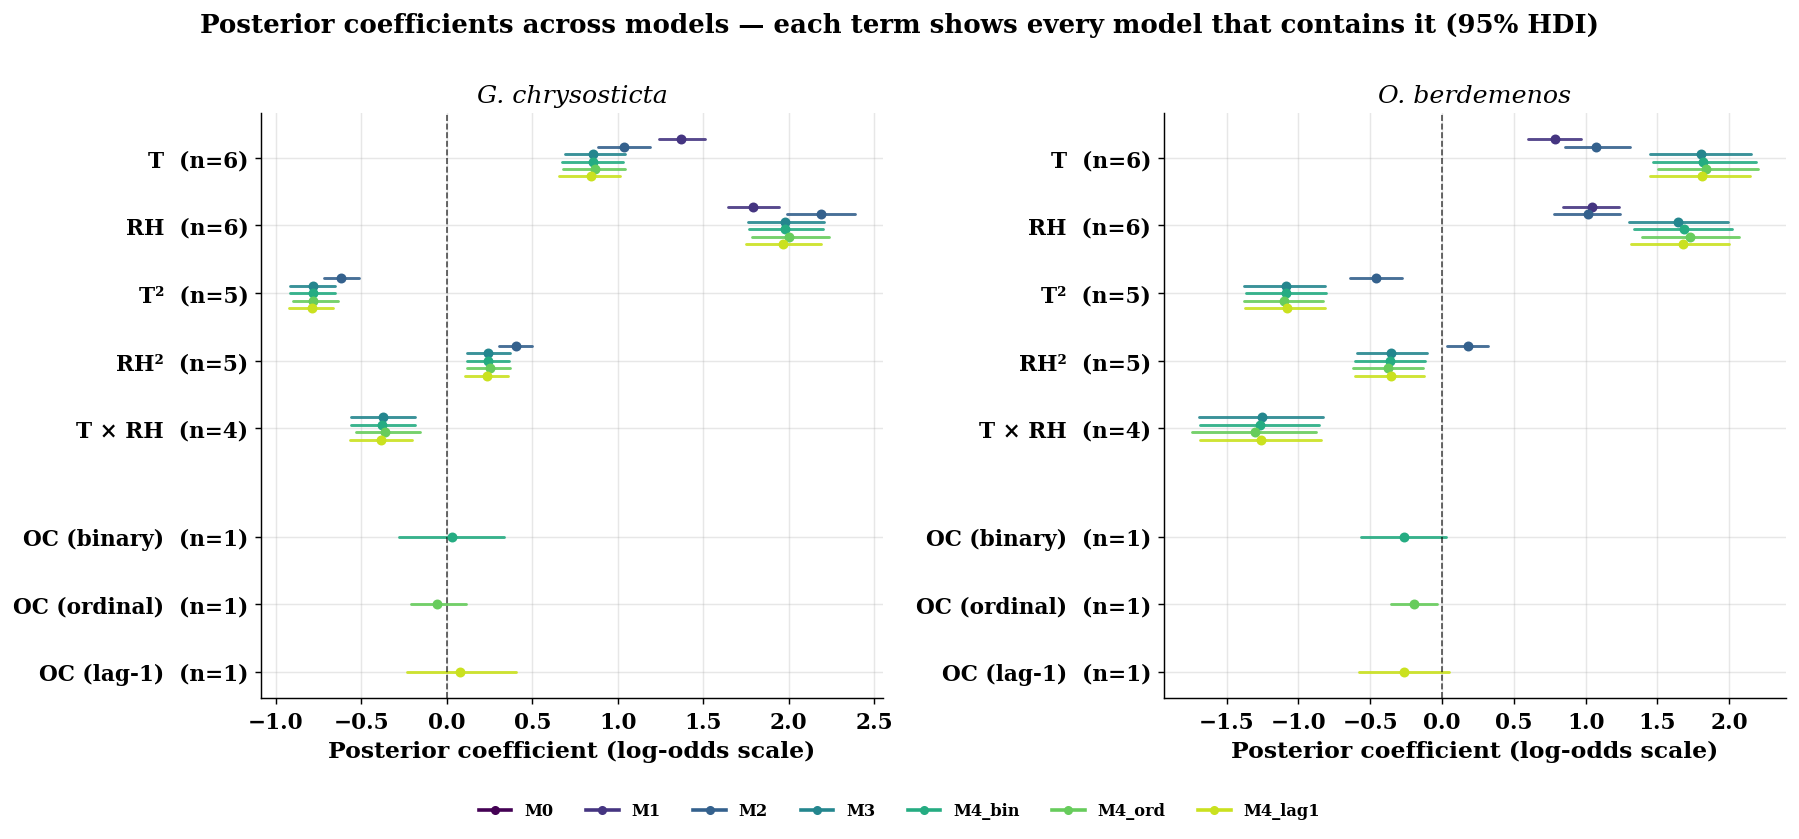

  saved figures/FigS1_bottom_fourier_coefficients_across_models.pdf


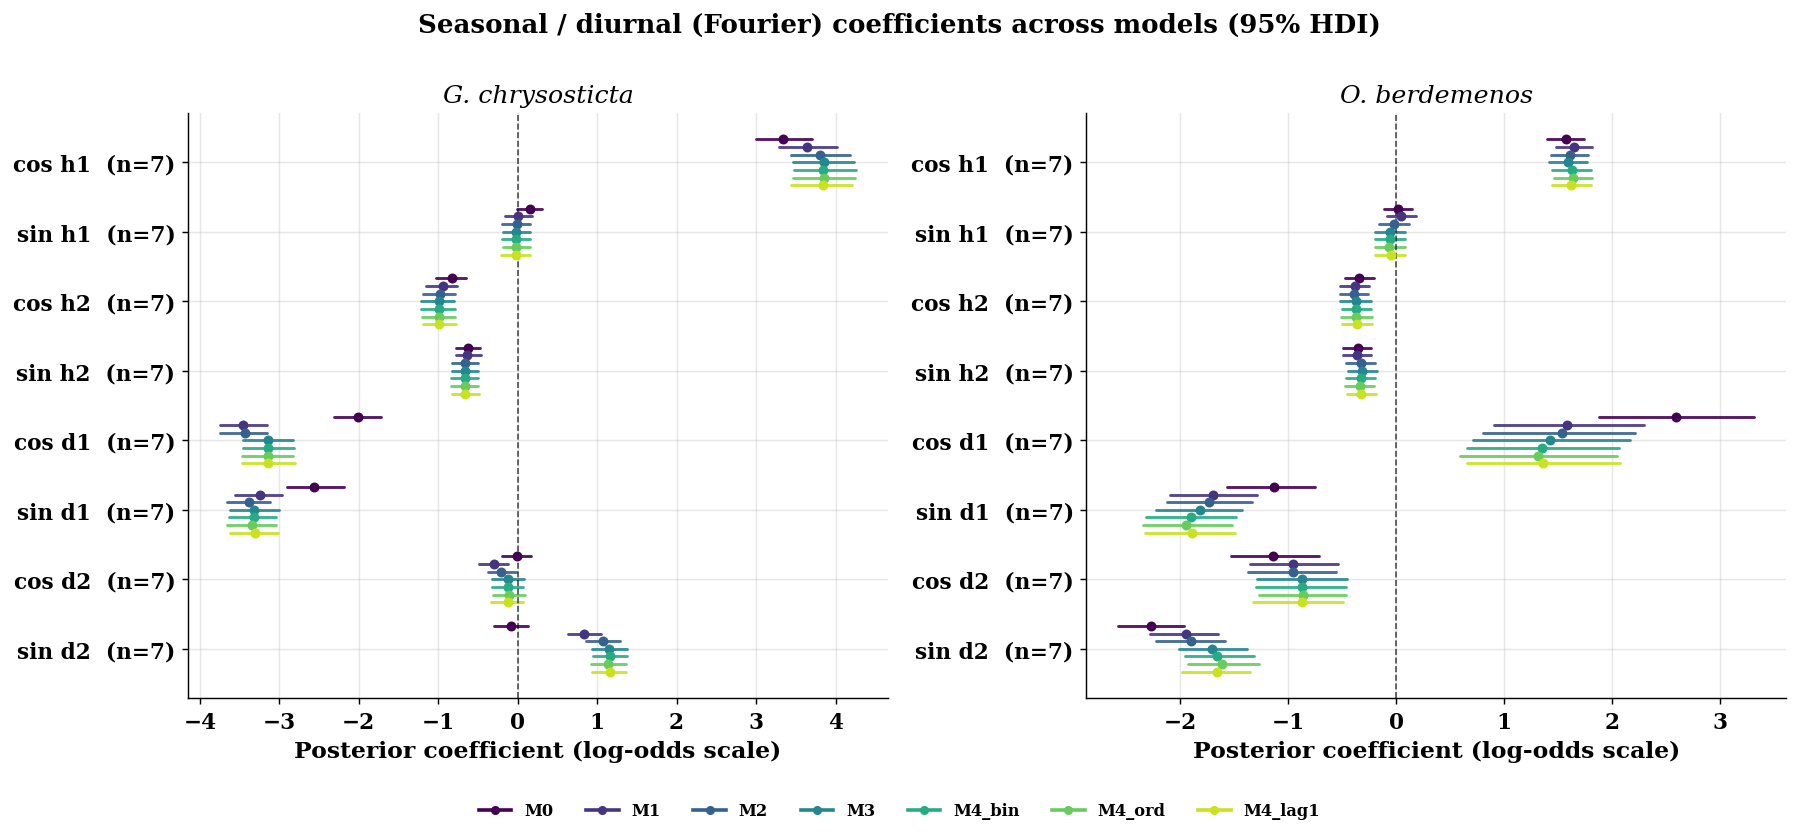

In [15]:
from matplotlib.lines import Line2D

PER = bayes_coef_table.rename(columns={"hdi_lower": "lo", "hdi_upper": "hi"})

ENV   = ["temp_z", "rh_z", "I(temp_z ** 2)", "I(rh_z ** 2)", "temp_z:rh_z"]
OC    = ["other_calling_bin", "other_calling_ord", "other_calling_lag1"]
FOUR  = ["cos_h1", "sin_h1", "cos_h2", "sin_h2", "cos_d1", "sin_d1", "cos_d2", "sin_d2"]
LABEL = {"temp_z": "T", "rh_z": "RH", "I(temp_z ** 2)": "T²", "I(rh_z ** 2)": "RH²",
         "temp_z:rh_z": "T × RH", "other_calling_bin": "OC (binary)",
         "other_calling_ord": "OC (ordinal)", "other_calling_lag1": "OC (lag-1)",
         "cos_h1": "cos h1", "sin_h1": "sin h1", "cos_h2": "cos h2", "sin_h2": "sin h2",
         "cos_d1": "cos d1", "sin_d1": "sin d1", "cos_d2": "cos d2", "sin_d2": "sin d2"}
MODEL_SEQ = ["model_0", "model_1", "model_2", "model_3", "model_4_bin", "model_4_ord", "model_4_lag1"]
MCOL = dict(zip(MODEL_SEQ, plt.cm.viridis(np.linspace(0, 0.92, len(MODEL_SEQ)))))


def _grp(t):
    return "env" if t in ENV else ("oc" if t in OC else "fourier")


def _forest(ax, sp, terms, group_gaps=True):
    sub = PER[PER.species == sp]
    yticks, ylabels, y = [], [], 0
    prev_grp = None
    for t in terms:
        if group_gaps and prev_grp is not None and _grp(t) != prev_grp:
            y += 0.6
        prev_grp = _grp(t)
        rows = sub[sub.term == t]
        present = [m for m in MODEL_SEQ if m in set(rows.model)]
        for k, m in enumerate(present):
            r = rows[rows.model == m].iloc[0]
            off = (k - (len(present) - 1) / 2) * 0.11
            ax.plot([r.lo, r.hi], [y + off] * 2, color=MCOL[m], lw=1.6, alpha=0.9, solid_capstyle="round")
            ax.plot(r["mean"], y + off, "o", color=MCOL[m], ms=4.5, zorder=3)
        yticks.append(y); ylabels.append(f"{LABEL[t]}  (n={len(present)})"); y += 1
    ax.axvline(0, color="k", lw=0.9, ls="--", alpha=0.7)
    ax.set_yticks(yticks); ax.set_yticklabels(ylabels); ax.invert_yaxis()
    ax.set_title(SP_SHORT[sp], fontstyle="italic")
    ax.set_xlabel("Posterior coefficient (log-odds scale)")


_FIGS1_RC = {"figure.dpi": 130, "savefig.dpi": 300, "font.size": 12, "axes.titlesize": 14,
             "axes.labelsize": 13, "axes.grid": True, "grid.alpha": 0.3,
             "axes.spines.top": False, "axes.spines.right": False, "font.family": "serif"}
_handles = [Line2D([0], [0], color=MCOL[m], lw=2, marker="o", ms=4, label=m.replace("model_", "M"))
            for m in MODEL_SEQ]

with plt.style.context("default"), plt.rc_context(_FIGS1_RC):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
    for ax, sp in zip(axes, SPECIES):
        _forest(ax, sp, ENV + OC)
    fig.legend(handles=_handles, ncol=7, loc="lower center", bbox_to_anchor=(0.5, -0.02), fontsize=9, frameon=False)
    fig.suptitle("Posterior coefficients across models — each term shows every model that contains it (95% HDI)", y=1.0)
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    fc.save_figure(fig, "FigS1_top_coefficients_across_models")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
    for ax, sp in zip(axes, SPECIES):
        _forest(ax, sp, FOUR, group_gaps=False)
    fig.legend(handles=_handles, ncol=7, loc="lower center", bbox_to_anchor=(0.5, -0.02), fontsize=9, frameon=False)
    fig.suptitle("Seasonal / diurnal (Fourier) coefficients across models (95% HDI)", y=1.0)
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    fc.save_figure(fig, "FigS1_bottom_fourier_coefficients_across_models")
    plt.show()

## 5.5 Prior sensitivity — $\mathcal{N}(0,\,1)$ vs $\mathcal{N}(0,\,0.5)$ coefficient priors

All results in Section 4 use weakly informative `Normal(0, 1)` priors on the population-level
(common) coefficients. Because every continuous predictor is z-scored and the heterospecific
term is on a 0–3 ordinal scale, a coefficient of 1 on the logit scale already corresponds to a
large effect (OR ≈ 2.7 per SD), so `Normal(0, 1)` is mildly regularising rather than flat.
To quantify how much of each estimate is prior-driven, the identical model (`model_4_ord`) is
refitted with a **twice-as-tight** `Normal(0, 0.5)` prior. Two questions are kept separate:
whether the *conclusions* (sign, and whether the 95 % HDI excludes zero) move, and whether the
*magnitudes* and the predictive fit move — a tighter prior can shrink large coefficients
appreciably without changing a single conclusion.

**Held fixed:** data, formula, cumulative-logit link, the threshold (cut-point) priors — Bambi's
default, which is deliberately *not* varied so that the comparison isolates the coefficient prior —
and the sampler settings (4 chains × 1000 draws after 1000 tuning steps, `target_accept = 0.9`,
`random_seed = 42`).
**Varied:** the SD of the zero-centred Normal prior on every common coefficient.

**Reported per coefficient**

| Quantity | Interpretation |
|---|---|
| posterior mean and 95 % HDI under each prior | the estimates a reader would report |
| $\Delta = \bar\beta_{\mathcal{N}(0,0.5)} - \bar\beta_{\mathcal{N}(0,1)}$ | raw shift in the point estimate |
| $\Delta/\mathrm{SD}_{\text{ref}}$ | shift expressed in reference posterior SDs; $\lvert\Delta\rvert/\mathrm{SD} < 0.1$ is negligible relative to posterior uncertainty |
| HDI width ratio | $<1$ means the tighter prior shrinks the interval; $\approx 1$ means the likelihood dominates |
| HDI overlap | intersection ÷ union of the two intervals (1 = identical, 0 = disjoint) |
| $P(\beta > 0)$ under each prior, and whether the 95 % HDI excludes 0 | whether any *inferential* conclusion changes |

**Reported per model:** divergent transitions, $\hat R$, bulk/tail ESS, and PSIS-LOO
(`elpd_loo`, plus the paired `elpd` difference with its standard error) under each prior.

In [16]:
# ── 5.5.1 Fit / load model_4_ord under each coefficient prior ────────────────
# Only the prior SD changes between runs; data, formula, link, threshold priors
# and sampler settings (including the seed) are identical.
import time
import arviz as az
import bambi as bmb

PS_MODEL     = "model_4_ord"   # the model carried forward for interpretation
PS_REF_SIGMA = 1.0             # prior SD used throughout the main analysis
PS_ALT_SIGMA = 0.5             # tighter prior for the sensitivity refit
PS_SIGMAS    = [PS_REF_SIGMA, PS_ALT_SIGMA]

PS_REFIT       = False   # True → resample even when cached draws exist
PS_SAVE_LOGLIK = False   # True → keep log_likelihood in the cache (~360 MB per model);
                         # False → cache posterior + sample_stats only (a few MB) and
                         # persist the LOO numbers to CSV instead.

PS_TABLE_DIR = fc.TABLE_DIR / "supporting"
PS_TABLE_DIR.mkdir(parents=True, exist_ok=True)
PS_METRICS_PATH = PS_TABLE_DIR / "prior_sensitivity_model_metrics.csv"


def ps_prior_label(sigma: float, latex: bool = False) -> str:
    return rf"$\mathcal{{N}}(0,\,{sigma:g})$" if latex else f"N(0, {sigma:g})"


def _ps_cache_path(sp: str, sigma: float) -> Path:
    tag = f"{sigma:g}".replace(".", "p")
    return MODEL_SAVE_DIR / f"{PS_MODEL}_priorsd{tag}_{sp.replace(' ', '_')}.nc"


def _ps_build_model(sp: str, sigma: float):
    """model_4_ord as a bambi model with Normal(0, sigma) on every common coefficient."""
    df_sp = species_data[sp].copy()
    df_sp["response_cat"] = pd.Categorical(df_sp["response_raw"], ordered=True)
    formula = model_results[sp][PS_MODEL][0].replace("response_code", "response_cat")
    return bmb.Model(
        formula=formula, data=df_sp, family="cumulative",
        priors={"common": bmb.Prior("Normal", mu=0, sigma=sigma)},
    )


def _ps_strip(idata):
    """Drop the multi-hundred-MB log_likelihood / posterior_predictive groups before caching."""
    slim = idata.copy()
    for grp in ("log_likelihood", "posterior_predictive"):
        if grp in slim.children:
            del slim[grp]
    return slim


ps_idata  = {}   # (species, sigma) → InferenceData
ps_models = {}   # (species, sigma) → bambi.Model
ps_elpd   = {}   # (species, sigma) → pointwise PSIS-LOO elpd
ps_loo    = {}   # (species, sigma) → PSIS-LOO summary

for sp in SPECIES:
    for sigma in PS_SIGMAS:
        key = (sp, sigma)
        ps_models[key] = _ps_build_model(sp, sigma)
        tag = f"{SP_SHORT[sp]:<17} {ps_prior_label(sigma):<11}"

        # Reference prior: reuse the posterior already fitted/loaded in Section 4.
        if sigma == PS_REF_SIGMA and (sp, PS_MODEL) in bayes_idata:
            ps_idata[key] = bayes_idata[(sp, PS_MODEL)]
            ps_elpd[key], ps_loo[key] = bayes_elpd[(sp, PS_MODEL)], bayes_loo[(sp, PS_MODEL)]
            print(f"{tag} reusing the Section-4 posterior")
            continue

        _df = species_data[sp].copy()
        _df["response_cat"] = pd.Categorical(_df["response_raw"], ordered=True)
        _formula = model_results[sp][PS_MODEL][0].replace("response_code", "response_cat")
        fit = fc.fit_cached(_formula, _df, sp, f"{PS_MODEL}_K2", prior_sigma=sigma)
        ps_idata[key], ps_elpd[key], ps_loo[key] = fit["idata"], fit["elpd_i"], fit["loo"]

print("\nPosteriors available for:", ", ".join(f"{SP_SHORT[s]} / {ps_prior_label(g)}"
                                               for s, g in ps_idata))

# Print the prior specification actually used, so the cut-points are on the record
# as unchanged and only the coefficient SD differs.
for sigma in PS_SIGMAS:
    print(f"\n{'-' * 78}\nPrior specification — {ps_prior_label(sigma)} "
          f"({SP_SHORT[SPECIES[0]]}, identical structure for the other species)\n{'-' * 78}")
    try:
        print(ps_models[(SPECIES[0], sigma)])
    except Exception as exc:
        print(f"  (could not render the bambi model: {exc})")

G. chrysosticta   N(0, 1)     reusing the Section-4 posterior


G. chrysosticta   model_4_ord_K2   N(0, 0.5)  loaded from cache (model_4_ord_K2_sd0p5_Gastrotheca_chrysosticta_93da3eb3)
O. berdemenos     N(0, 1)     reusing the Section-4 posterior
O. berdemenos     model_4_ord_K2   N(0, 0.5)  loaded from cache (model_4_ord_K2_sd0p5_Oreobates_berdemenos_93da3eb3)

Posteriors available for: G. chrysosticta / N(0, 1), G. chrysosticta / N(0, 0.5), O. berdemenos / N(0, 1), O. berdemenos / N(0, 0.5)

------------------------------------------------------------------------------
Prior specification — N(0, 1) (G. chrysosticta, identical structure for the other species)
------------------------------------------------------------------------------
       Formula: response_cat ~ sin_h1 + cos_h1 + sin_h2 + cos_h2 + sin_d1 + cos_d1 + sin_d2 + cos_d2 + temp_z + rh_z + I(temp_z ** 2) + I(rh_z ** 2) + temp_z:rh_z + other_calling_ord
        Family: cumulative
          Link: p = logit
  Observations: 11302
        Priors: 
    target = p
        Common-level effec

In [17]:
# ── 5.5.2 Posterior summaries and the prior-to-prior comparison ──────────────
PS_HDI_PROB = 0.95


def _ps_hdi(x, prob: float = PS_HDI_PROB):
    """Highest-density interval of a 1-D sample (independent of the ArviZ version)."""
    x = np.sort(np.asarray(x, dtype=float).ravel())
    n = x.size
    k = max(int(np.floor(prob * n)), 1)
    if k >= n:
        return float(x[0]), float(x[-1])
    widths = x[k:] - x[: n - k]
    i = int(np.argmin(widths))
    return float(x[i]), float(x[i + k])


def _ps_flat_draws(idata) -> Dict[str, np.ndarray]:
    """{term: 1-D draws} for every posterior variable; vector-valued ones expand to term[i]."""
    out = {}
    for v in idata.posterior.data_vars:
        da = idata.posterior[v]
        extra = [d for d in da.dims if d not in ("chain", "draw")]
        if not extra:
            out[str(v)] = np.asarray(da.values).ravel()
        else:
            for i in range(da.sizes[extra[0]]):
                out[f"{v}[{i}]"] = np.asarray(da.isel({extra[0]: i}).values).ravel()
    return out


def _ps_diagnostics(idata) -> pd.DataFrame:
    try:
        diag = az.summary(idata, kind="diagnostics", round_to="none")
    except Exception:
        diag = az.summary(idata)
    return diag.apply(pd.to_numeric, errors="coerce")


def ps_summarize(idata, species: str, sigma: float) -> pd.DataFrame:
    """Per-coefficient posterior summary for one species × prior."""
    diag = _ps_diagnostics(idata)
    rows = []
    for term, draws in _ps_flat_draws(idata).items():
        lo, hi = _ps_hdi(draws)
        rows.append({
            "species": species, "prior_sigma": sigma, "term": term,
            "mean":   float(draws.mean()),
            "sd":     float(draws.std(ddof=1)),
            "median": float(np.median(draws)),
            "hdi_lower": lo, "hdi_upper": hi, "hdi_width": hi - lo,
            "OR":          float(np.exp(draws.mean())),
            "OR_hdi_lower": float(np.exp(lo)),
            "OR_hdi_upper": float(np.exp(hi)),
            "p_gt0": float((draws > 0).mean()),
            "excludes_zero": bool(lo > 0 or hi < 0),
            "r_hat":    float(diag["r_hat"].get(term, np.nan))    if "r_hat"    in diag else np.nan,
            "ess_bulk": float(diag["ess_bulk"].get(term, np.nan)) if "ess_bulk" in diag else np.nan,
            "ess_tail": float(diag["ess_tail"].get(term, np.nan)) if "ess_tail" in diag else np.nan,
        })
    return pd.DataFrame(rows)


prior_sens_summaries = pd.concat(
    [ps_summarize(ps_idata[(sp, s)], sp, s) for sp in SPECIES for s in PS_SIGMAS],
    ignore_index=True,
)

# ── Term labels, grouping and display order ──────────────────────────────────
PS_GROUP_ORDER = ["Environmental", "Heterospecific calling", "Diel harmonics",
                  "Seasonal harmonics", "Cut-points"]

# Labels come in three flavours: plain Unicode for tables and CSVs, LaTeX for the
# .tex export, and mathtext for figures (the notebook's cmr10 font has no glyph for
# ², ×, τ or |, which would otherwise render as tofu boxes).
PS_TERM_META = {
    # term                (group,          display,                  LaTeX,                           matplotlib)
    "temp_z":         ("Environmental", "Temperature (z)", r"Temperature ($z$)",            r"Temperature ($z$)"),
    "I(temp_z ** 2)": ("Environmental", "Temperature²",    r"Temperature$^{2}$",            r"Temperature$^{2}$"),
    "rh_z":           ("Environmental", "Humidity (z)",    r"Humidity ($z$)",               r"Humidity ($z$)"),
    "I(rh_z ** 2)":   ("Environmental", "Humidity²",       r"Humidity$^{2}$",               r"Humidity$^{2}$"),
    "temp_z:rh_z":    ("Environmental", "Temperature × Humidity",
                       r"Temperature $\times$ Humidity", r"Temperature $\times$ Humidity"),
    "other_calling_ord": ("Heterospecific calling", "Heterospecific calling (ordinal)",
                          r"Heterospecific calling (ordinal)", "Heterospecific calling (ord.)"),
    "sin_h1": ("Diel harmonics",     "Diel sin(1)",     r"Diel $\sin(1)$",     r"Diel $\sin(1)$"),
    "cos_h1": ("Diel harmonics",     "Diel cos(1)",     r"Diel $\cos(1)$",     r"Diel $\cos(1)$"),
    "sin_h2": ("Diel harmonics",     "Diel sin(2)",     r"Diel $\sin(2)$",     r"Diel $\sin(2)$"),
    "cos_h2": ("Diel harmonics",     "Diel cos(2)",     r"Diel $\cos(2)$",     r"Diel $\cos(2)$"),
    "sin_d1": ("Seasonal harmonics", "Seasonal sin(1)", r"Seasonal $\sin(1)$", r"Seasonal $\sin(1)$"),
    "cos_d1": ("Seasonal harmonics", "Seasonal cos(1)", r"Seasonal $\cos(1)$", r"Seasonal $\cos(1)$"),
    "sin_d2": ("Seasonal harmonics", "Seasonal sin(2)", r"Seasonal $\sin(2)$", r"Seasonal $\sin(2)$"),
    "cos_d2": ("Seasonal harmonics", "Seasonal cos(2)", r"Seasonal $\cos(2)$", r"Seasonal $\cos(2)$"),
}


def _ps_threshold_meta(sp: str) -> Dict[str, tuple]:
    """Cut-point labels named after the category boundary each one separates."""
    cats = list(pd.Categorical(species_data[sp]["response_raw"], ordered=True).categories)
    meta = {}
    for i in range(len(cats) - 1):
        a, b = cats[i], cats[i + 1]
        a = int(a) if float(a).is_integer() else a
        b = int(b) if float(b).is_integer() else b
        meta[f"threshold[{i}]"] = (
            "Cut-points",
            f"τ{i + 1} ({a} | {b})",
            rf"$\tau_{{{i + 1}}}$ ({a}\,$\vert$\,{b})",
            rf"$\tau_{{{i + 1}}}$ ({a}/{b})",
        )
    return meta


def ps_term_meta(sp: str, term: str) -> tuple:
    """(group, display label, LaTeX label, matplotlib label) for one term."""
    meta = {**PS_TERM_META, **_ps_threshold_meta(sp)}
    return meta.get(term, ("Other", term, term.replace("_", r"\_"), term.replace("_", " ")))


# ── Wide comparison: reference prior vs tighter prior ────────────────────────
_ref = prior_sens_summaries.query("prior_sigma == @PS_REF_SIGMA").set_index(["species", "term"])
_alt = prior_sens_summaries.query("prior_sigma == @PS_ALT_SIGMA").set_index(["species", "term"])
cmp = _ref.drop(columns="prior_sigma").join(
    _alt.drop(columns="prior_sigma"), lsuffix="_ref", rsuffix="_alt", how="inner"
).reset_index()

cmp["delta_mean"]      = cmp["mean_alt"] - cmp["mean_ref"]
cmp["abs_delta_mean"]  = cmp["delta_mean"].abs()
cmp["delta_over_sd"]   = cmp["delta_mean"] / cmp["sd_ref"]
cmp["hdi_width_ratio"] = cmp["hdi_width_alt"] / cmp["hdi_width_ref"]

_inter = np.maximum(0.0, np.minimum(cmp["hdi_upper_ref"], cmp["hdi_upper_alt"])
                         - np.maximum(cmp["hdi_lower_ref"], cmp["hdi_lower_alt"]))
_union = (np.maximum(cmp["hdi_upper_ref"], cmp["hdi_upper_alt"])
          - np.minimum(cmp["hdi_lower_ref"], cmp["hdi_lower_alt"]))
cmp["hdi_overlap"] = _inter / _union

cmp["sign_stable"]       = np.sign(cmp["mean_ref"]) == np.sign(cmp["mean_alt"])
cmp["hdi_zero_stable"]   = cmp["excludes_zero_ref"] == cmp["excludes_zero_alt"]
cmp["inference_stable"]  = cmp["sign_stable"] & cmp["hdi_zero_stable"]

_meta = cmp.apply(lambda r: ps_term_meta(r["species"], r["term"]), axis=1, result_type="expand")
cmp[["group", "label", "label_tex", "label_mpl"]] = _meta
cmp["_g"] = cmp["group"].apply(lambda g: PS_GROUP_ORDER.index(g) if g in PS_GROUP_ORDER else 99)
_order = list(PS_TERM_META) + [f"threshold[{i}]" for i in range(9)]
cmp["_t"] = cmp["term"].apply(lambda t: _order.index(t) if t in _order else 99)
cmp["_s"] = cmp["species"].apply(SPECIES.index)

prior_sens_table_full = (
    cmp.sort_values(["_s", "_g", "_t", "term"])
       .drop(columns=["_s", "_g", "_t"])
       .reset_index(drop=True)
)

print(f"{len(prior_sens_table_full)} coefficients compared "
      f"({prior_sens_table_full['species'].nunique()} species x "
      f"{prior_sens_table_full['term'].nunique()} terms)")
prior_sens_table_full.head(12)

34 coefficients compared (2 species x 17 terms)


,species,term,mean_ref,sd_ref,median_ref,hdi_lower_ref,hdi_upper_ref,hdi_width_ref,OR_ref,OR_hdi_lower_ref,OR_hdi_upper_ref,p_gt0_ref,excludes_zero_ref,r_hat_ref,ess_bulk_ref,ess_tail_ref,mean_alt,sd_alt,median_alt,hdi_lower_alt,hdi_upper_alt,hdi_width_alt,OR_alt,OR_hdi_lower_alt,OR_hdi_upper_alt,p_gt0_alt,excludes_zero_alt,r_hat_alt,ess_bulk_alt,ess_tail_alt,delta_mean,abs_delta_mean,delta_over_sd,hdi_width_ratio,hdi_overlap,sign_stable,hdi_zero_stable,inference_stable,group,label,label_tex,label_mpl
0,Gastrotheca chrysosticta,temp_z,0.864552,0.092780,0.864744,0.677625,1.043085,0.365461,2.373943,1.969195,2.837959,1.00000,True,1.001485,2814.823436,2967.228851,0.720600,0.086120,0.721191,0.550186,0.889259,0.339074,2.055666,1.733575,2.433327,1.000,True,1.001392,3023.010341,2917.102818,-0.143952,0.143952,-1.551547,0.927799,0.429366,True,True,True,Environmental,Temperature (z),Temperature ($z$),Temperature ($z$)
1,Gastrotheca chrysosticta,I(temp_z ** 2),-0.780933,0.067250,-0.781105,-0.903205,-0.637215,0.265991,0.457978,0.405269,0.528763,0.00000,True,1.000852,3477.918342,3223.017794,-0.794386,0.063887,-0.795353,-0.921061,-0.674154,0.246907,0.451859,0.398096,0.509587,0.000,True,1.000919,3131.708400,2942.827105,-0.013453,0.013453,-0.200039,0.928254,0.806954,True,True,True,Environmental,Temperature²,Temperature$^{2}$,Temperature$^{2}$
2,Gastrotheca chrysosticta,rh_z,1.999519,0.114905,2.000628,1.785838,2.233633,0.447795,7.385503,5.964576,9.333716,1.00000,True,1.000378,2575.644630,2718.701591,1.766484,0.107234,1.768478,1.556319,1.966726,0.410407,5.850247,4.741337,7.147237,1.000,True,1.002252,2488.473962,2574.106019,-0.233035,0.233035,-2.028066,0.916505,0.267066,True,True,True,Environmental,Humidity (z),Humidity ($z$),Humidity ($z$)
3,Gastrotheca chrysosticta,I(rh_z ** 2),0.249669,0.064639,0.249121,0.120073,0.371630,0.251556,1.283601,1.127580,1.450096,1.00000,True,1.000982,2665.784438,2776.317499,0.162481,0.062769,0.162409,0.040813,0.287723,0.246911,1.176426,1.041657,1.333388,0.994,True,1.003903,2622.614995,2634.752056,-0.087188,0.087188,-1.348840,0.981534,0.506776,True,True,True,Environmental,Humidity²,Humidity$^{2}$,Humidity$^{2}$
4,Gastrotheca chrysosticta,temp_z:rh_z,-0.360880,0.096250,-0.360228,-0.533823,-0.158949,0.374874,0.697062,0.586359,0.853040,0.00000,True,1.000956,2666.415813,2831.381559,-0.436558,0.091905,-0.434618,-0.613694,-0.256809,0.356885,0.646257,0.541347,0.773516,0.000,True,1.002820,2641.119851,2635.514615,-0.075677,0.075677,-0.786257,0.952013,0.609162,True,True,True,Environmental,Temperature × Humidity,Temperature $\times$ Humidity,Temperature $\times$ Humidity
5,Gastrotheca chrysosticta,other_calling_ord,-0.057581,0.081935,-0.058094,-0.210530,0.113790,0.324320,0.944046,0.810155,1.120517,0.24125,False,1.003781,4688.117664,2780.733268,-0.016675,0.078297,-0.017889,-0.167905,0.132133,0.300039,0.983463,0.845434,1.141261,0.416,False,1.000431,4301.326495,2971.405158,0.040905,0.040905,0.499236,0.925132,0.822078,True,True,True,Heterospecific calling,Heterospecific calling (ordinal),Heterospecific calling (ordinal),Heterospecific calling (ord.)
6,Gastrotheca chrysosticta,sin_h1,-0.020475,0.090071,-0.021958,-0.190806,0.157354,0.348160,0.979733,0.826293,1.170409,0.40575,False,1.000097,4193.991233,2852.352395,-0.074673,0.083900,-0.074006,-0.240941,0.085007,0.325948,0.928047,0.785888,1.088725,0.185,False,0.999793,3527.396934,3089.255556,-0.054198,0.054198,-0.601728,0.936202,0.692485,True,True,True,Diel harmonics,Diel sin(1),Diel $\sin(1)$,Diel $\sin(1)$
7,Gastrotheca chrysosticta,cos_h1,3.853145,0.198187,3.850839,3.467884,4.241096,0.773212,47.141087,32.068809,69.483962,1.00000,True,1.001580,3154.875543,2881.556538,3.415486,0.161634,3.411792,3.079921,3.709747,0.629826,30.431722,21.756684,40.843459,1.000,True,0.999702,2933.827320,2639.738359,-0.437659,0.437659,-2.208320,0.814558,0.208291,True,True,True,Diel harmonics,Diel cos(1),Diel $\cos(1)$,Diel $\cos(1)$
8,Gastrotheca chrysosticta,sin_h2,-0.667572,0.084813,-0.669026,-0.835049,-0

In [18]:
# ── 5.5.3 Model-level diagnostics and predictive fit under each prior ────────
# LOO can only be recomputed while the log_likelihood group is in memory, so the
# numbers are persisted to CSV and re-read when a slim cache is loaded instead.

def _ps_loo(idata):
    """(pointwise elpd or None, {elpd_loo, loo_se, p_loo})."""
    try:
        res = az.loo(idata, pointwise=True)
    except Exception:
        return None, {"elpd_loo": np.nan, "loo_se": np.nan, "p_loo": np.nan}
    elpd_i = np.asarray(getattr(res, "elpd_i", np.array([])), dtype=float).ravel()
    stats = {
        "elpd_loo": float(getattr(res, "elpd", np.nan)),
        "loo_se":   float(getattr(res, "se",   np.nan)),
        "p_loo":    float(getattr(res, "p",    np.nan)),
    }
    return (elpd_i if elpd_i.size else None), stats


PS_LOO_DIFF_PATH = PS_TABLE_DIR / "prior_sensitivity_loo_diff.csv"
_ps_cached_metrics = (
    pd.read_csv(PS_METRICS_PATH) if PS_METRICS_PATH.exists() else pd.DataFrame()
)
_ps_cached_diff = (
    pd.read_csv(PS_LOO_DIFF_PATH) if PS_LOO_DIFF_PATH.exists() else pd.DataFrame()
)

_metric_rows, _elpd_pointwise = [], {}

for sp in SPECIES:
    for sigma in PS_SIGMAS:
        idata = ps_idata[(sp, sigma)]
        elpd_i = ps_elpd[(sp, sigma)]   # cached pointwise PSIS-LOO (see frogcall.fit_cached)
        loo_stats = {k: ps_loo[(sp, sigma)][k] for k in ("elpd_loo", "loo_se", "p_loo")}
        if elpd_i is not None:
            _elpd_pointwise[(sp, sigma)] = elpd_i

        # Fall back to the persisted numbers when the cache carries no log_likelihood.
        if np.isnan(loo_stats["elpd_loo"]) and not _ps_cached_metrics.empty:
            hit = _ps_cached_metrics.query(
                "species == @sp and abs(prior_sigma - @sigma) < 1e-9"
            )
            if not hit.empty:
                loo_stats = {k: float(hit.iloc[0][k]) for k in loo_stats}
                print(f"  {SP_SHORT[sp]} / {ps_prior_label(sigma)}: LOO read from "
                      f"{PS_METRICS_PATH.name} (slim cache holds no log-likelihood)")

        summ = prior_sens_summaries.query("species == @sp and prior_sigma == @sigma")
        div = (int(idata.sample_stats["diverging"].sum())
               if "sample_stats" in idata.children and "diverging" in idata.sample_stats
               else np.nan)

        _metric_rows.append({
            "species": sp, "species_short": SP_SHORT[sp], "model": PS_MODEL,
            "prior": ps_prior_label(sigma), "prior_sigma": sigma,
            "n_obs": int(species_data[sp].shape[0]),
            "divergences": div,
            "max_r_hat":    float(summ["r_hat"].max()),
            "min_ess_bulk": float(summ["ess_bulk"].min()),
            "min_ess_tail": float(summ["ess_tail"].min()),
            **loo_stats,
        })

prior_sens_metrics = pd.DataFrame(_metric_rows)

# ── Paired elpd difference (tighter prior − reference prior) ─────────────────
_diff_rows = []
for sp in SPECIES:
    k_ref, k_alt = (sp, PS_REF_SIGMA), (sp, PS_ALT_SIGMA)
    row = {"species": sp, "species_short": SP_SHORT[sp],
           "comparison": f"{ps_prior_label(PS_ALT_SIGMA)} - {ps_prior_label(PS_REF_SIGMA)}"}
    _hit = (_ps_cached_diff.query("species == @sp")
            if not _ps_cached_diff.empty else pd.DataFrame())
    if k_ref in _elpd_pointwise and k_alt in _elpd_pointwise:
        d = _elpd_pointwise[k_alt] - _elpd_pointwise[k_ref]
        row["elpd_diff"] = float(d.sum())
        row["se_diff"]   = float(np.sqrt(d.size) * d.std(ddof=1))
    elif not _hit.empty:                       # paired SE persisted from an earlier full run
        row["elpd_diff"] = float(_hit.iloc[0]["elpd_diff"])
        row["se_diff"]   = float(_hit.iloc[0]["se_diff"])
    else:  # last resort: difference of the totals, no paired SE
        m = prior_sens_metrics.query("species == @sp").set_index("prior_sigma")
        row["elpd_diff"] = float(m.loc[PS_ALT_SIGMA, "elpd_loo"] - m.loc[PS_REF_SIGMA, "elpd_loo"])
        row["se_diff"]   = np.nan
    row["elpd_diff_over_se"] = (row["elpd_diff"] / row["se_diff"]
                                if row.get("se_diff") and np.isfinite(row["se_diff"]) else np.nan)
    _diff_rows.append(row)

prior_sens_loo_diff = pd.DataFrame(_diff_rows)

prior_sens_metrics.to_csv(PS_METRICS_PATH, index=False)
prior_sens_loo_diff.to_csv(PS_LOO_DIFF_PATH, index=False)
print(f"Saved → {PS_METRICS_PATH.name}, {PS_LOO_DIFF_PATH.name}")

display(prior_sens_metrics[[
    "species_short", "prior", "n_obs", "divergences", "max_r_hat",
    "min_ess_bulk", "min_ess_tail", "elpd_loo", "loo_se", "p_loo",
]].round(2))
display(prior_sens_loo_diff.round(2))

Saved → prior_sensitivity_model_metrics.csv, prior_sensitivity_loo_diff.csv


,species_short,prior,n_obs,divergences,max_r_hat,min_ess_bulk,min_ess_tail,elpd_loo,loo_se,p_loo
0,G. chrysosticta,"N(0, 1)",11302,0,1.0,2483.87,2509.22,-2539.06,68.39,15.53
1,G. chrysosticta,"N(0, 0.5)",11302,0,1.0,2437.62,2449.81,-2557.75,67.16,14.21
2,O. berdemenos,"N(0, 1)",11302,0,1.0,1494.21,1815.88,-2224.28,61.07,13.72
3,O. berdemenos,"N(0, 0.5)",11302,0,1.0,2039.22,2176.90,-2232.98,60.88,12.50


,species,species_short,comparison,elpd_diff,se_diff,elpd_diff_over_se
0,Gastrotheca chrysosticta,G. chrysosticta,"N(0, 0.5) - N(0, 1)",-18.69,3.46,-5.40
1,Oreobates berdemenos,O. berdemenos,"N(0, 0.5) - N(0, 1)",-8.70,2.20,-3.96


In [19]:
# ── 5.5.4 Publication-ready prior sensitivity table ──────────────────────────
PS_DP = 3   # decimal places for coefficients on the logit scale


def _f(x, dp=PS_DP):
    return "—" if pd.isna(x) else f"{x:.{dp}f}"


def _fmt_est(mean, lo, hi, dp=PS_DP):
    return f"{_f(mean, dp)} [{_f(lo, dp)}, {_f(hi, dp)}]"


def _fmt_p(p):
    if pd.isna(p):
        return "—"
    if p > 0.9995:
        return "> 0.999"
    if p < 0.0005:
        return "< 0.001"
    return f"{p:.3f}"


_REF_L, _ALT_L = ps_prior_label(PS_REF_SIGMA), ps_prior_label(PS_ALT_SIGMA)
PS_COLS = ["Species", "Group", "Term",
           f"Mean [95% HDI] {_REF_L}", f"P(β>0) {_REF_L}",
           f"Mean [95% HDI] {_ALT_L}", f"P(β>0) {_ALT_L}",
           "Δ mean", "Δ/SD", "HDI width ratio", "HDI overlap", "Inference"]

_rows = []
for _, r in prior_sens_table_full.iterrows():
    _rows.append({
        "Species": SP_SHORT[r["species"]],
        "Group":   r["group"],
        "Term":    r["label"],
        f"Mean [95% HDI] {_REF_L}": _fmt_est(r["mean_ref"], r["hdi_lower_ref"], r["hdi_upper_ref"]),
        f"P(β>0) {_REF_L}":         _fmt_p(r["p_gt0_ref"]),
        f"Mean [95% HDI] {_ALT_L}": _fmt_est(r["mean_alt"], r["hdi_lower_alt"], r["hdi_upper_alt"]),
        f"P(β>0) {_ALT_L}":         _fmt_p(r["p_gt0_alt"]),
        "Δ mean":          _f(r["delta_mean"]),
        "Δ/SD":            _f(r["delta_over_sd"], 2),
        "HDI width ratio": _f(r["hdi_width_ratio"], 2),
        "HDI overlap":     _f(r["hdi_overlap"], 2),
        "Inference":       "unchanged" if r["inference_stable"] else "CHANGED",
    })

prior_sens_table_pub = pd.DataFrame(_rows, columns=PS_COLS)

PS_TABLE_NOTE = (
    f"Cumulative-logit ordinal model ({PS_MODEL}) refitted with the coefficient prior changed from "
    f"{_REF_L} to {_ALT_L}; data, formula, cut-point priors and sampler settings identical "
    f"({BAYES_CHAINS} chains × {BAYES_DRAWS} draws after {BAYES_TUNE} tuning steps, seed 42). "
    "Coefficients are on the logit scale; the continuous predictors are z-scored, so each is the "
    "change in log-odds of a higher calling category per 1 SD. HDI = highest-density interval. "
    "Δ = posterior mean under the tighter prior minus that under the reference prior; Δ/SD "
    "expresses that shift in reference posterior SDs (below 0.1 in absolute value = negligible "
    "relative to posterior uncertainty). An HDI width ratio below 1 means the tighter prior "
    "narrows the interval; HDI overlap is the intersection divided by the union of the two "
    "intervals. Inference counts as unchanged when the sign of the posterior mean and the "
    "exclusion or inclusion of zero by the 95% HDI both agree across priors."
)

PS_TABLE_NOTE_TEX = (
    rf"\textit{{Note.}} Cumulative-logit ordinal model (\texttt{{{PS_MODEL.replace('_', r'\_')}}}) "
    rf"refitted with the coefficient prior changed from {ps_prior_label(PS_REF_SIGMA, latex=True)} "
    rf"to {ps_prior_label(PS_ALT_SIGMA, latex=True)}; data, formula, cut-point priors and sampler "
    rf"settings identical ({BAYES_CHAINS} chains $\times$ {BAYES_DRAWS} draws after {BAYES_TUNE} "
    r"tuning steps, seed 42). Coefficients are on the logit scale; the continuous predictors are "
    r"$z$-scored, so each is the change in log-odds of a higher calling category per 1\,SD. "
    r"HDI = highest-density interval. $\Delta$ = posterior mean under the tighter prior minus that "
    r"under the reference prior; $\Delta/\mathrm{SD}$ expresses that shift in reference posterior "
    r"SDs ($\lvert\Delta/\mathrm{SD}\rvert<0.1$ = negligible relative to posterior uncertainty). "
    r"An HDI width ratio $<1$ means the tighter prior narrows the interval. Inference counts as "
    r"unchanged when the sign of the posterior mean and the exclusion or inclusion of zero by the "
    r"95\% HDI both agree across priors."
)

# ── Exports ──────────────────────────────────────────────────────────────────
_pub_csv  = fc.TABLE_DIR / "TableS3_prior_sensitivity.csv"
_full_csv = PS_TABLE_DIR / "prior_sensitivity_full.csv"
prior_sens_table_pub.to_csv(_pub_csv, index=False)
prior_sens_table_full.to_csv(_full_csv, index=False)


def _tex_escape_pct(s: str) -> str:
    return s.replace("%", r"\%")


def _tex_num(s: str) -> str:
    """Typeset numeric cells: real minus signs, math-mode inequalities."""
    return s.replace("-", "$-$").replace("<", "$<$").replace(">", "$>$")


def prior_sens_latex(caption: str | None = None,
                     label: str = "tab:prior-sensitivity") -> str:
    """Booktabs table, one panel per species, grouped by term family."""
    caption = caption or "Prior sensitivity of the ordinal calling model."
    ref_t, alt_t = ps_prior_label(PS_REF_SIGMA, latex=True), ps_prior_label(PS_ALT_SIGMA, latex=True)
    out = [
        r"\begin{table}[htbp]", r"\centering", rf"\caption{{{_tex_escape_pct(caption)}}}",
        rf"\label{{{label}}}", r"\footnotesize", r"\setlength{\tabcolsep}{4pt}",
        r"\begin{tabular}{@{}l cc cc rrr c@{}}", r"\toprule",
        rf" & \multicolumn{{2}}{{c}}{{{ref_t} prior}} & \multicolumn{{2}}{{c}}{{{alt_t} prior}}"
        r" & \multicolumn{3}{c}{Prior-to-prior change} & \\",
        r"\cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-8}",
        r"Term & Mean [95\% HDI] & $P(\beta>0)$ & Mean [95\% HDI] & $P(\beta>0)$"
        r" & $\Delta$ & $\Delta/\mathrm{SD}$ & HDI ratio & Inference \\",
        r"\midrule",
    ]
    for si, sp in enumerate(SPECIES):
        sub = prior_sens_table_full.query("species == @sp")
        if si:
            out.append(r"\addlinespace[3pt]")
        out.append(rf"\multicolumn{{9}}{{@{{}}l}}{{\textit{{{sp}}}}}\\")
        for grp in [g for g in PS_GROUP_ORDER if g in set(sub["group"])]:
            out.append(rf"\multicolumn{{9}}{{@{{}}l}}{{\hspace{{0.5em}}\textsc{{{grp.lower()}}}}}\\")
            for _, r in sub.query("group == @grp").iterrows():
                cells = [
                    rf"\hspace{{1em}}{r['label_tex']}",
                    _tex_num(_fmt_est(r["mean_ref"], r["hdi_lower_ref"], r["hdi_upper_ref"])),
                    _tex_num(_fmt_p(r["p_gt0_ref"])),
                    _tex_num(_fmt_est(r["mean_alt"], r["hdi_lower_alt"], r["hdi_upper_alt"])),
                    _tex_num(_fmt_p(r["p_gt0_alt"])),
                    _tex_num(_f(r["delta_mean"])),
                    _tex_num(_f(r["delta_over_sd"], 2)),
                    _tex_num(_f(r["hdi_width_ratio"], 2)),
                    "unchanged" if r["inference_stable"] else r"\textbf{changed}",
                ]
                out.append(" & ".join(cells) + r" \\")
    out += [
        r"\bottomrule", r"\end{tabular}",
        r"\par\vspace{3pt}",
        r"\begin{minipage}{\linewidth}\footnotesize\raggedright",
        PS_TABLE_NOTE_TEX,
        r"\end{minipage}", r"\end{table}",
    ]
    return "\n".join(out)


_tex_path = fc.TABLE_DIR / "TableS3_prior_sensitivity.tex"
_tex_path.write_text(prior_sens_latex(
    caption=(f"Prior sensitivity of the cumulative-logit ordinal model of calling intensity: "
             f"posterior means and 95% highest-density intervals under "
             f"{ps_prior_label(PS_REF_SIGMA, latex=True)} versus "
             f"{ps_prior_label(PS_ALT_SIGMA, latex=True)} coefficient priors.")
), encoding="utf-8")

def _md_table(df: pd.DataFrame) -> str:
    """Pipe table without the optional `tabulate` dependency."""
    head = "| " + " | ".join(df.columns) + " |"
    rule = "| " + " | ".join("---" for _ in df.columns) + " |"
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([head, rule, *body])


_md_path = fc.TABLE_DIR / "TableS3_prior_sensitivity.md"
_md_path.write_text(
    _md_table(prior_sens_table_pub) + "\n\n*Note.* " + PS_TABLE_NOTE + "\n",
    encoding="utf-8",
)

_html_path = fc.TABLE_DIR / "TableS3_prior_sensitivity.html"
_html_path.write_text(
    "<style>table{border-collapse:collapse;font-family:Georgia,serif;font-size:12px}"
    "th,td{padding:3px 8px;text-align:right}th:nth-child(-n+3),td:nth-child(-n+3){text-align:left}"
    "thead th{border-top:1.4px solid #000;border-bottom:0.8px solid #000}"
    "tbody tr:last-child td{border-bottom:1.4px solid #000}</style>\n"
    f"<table>{prior_sens_table_pub.to_html(index=False, border=0)}</table>"
    f"<p style='font-family:Georgia,serif;font-size:11px;max-width:900px'><i>Note.</i> {PS_TABLE_NOTE}</p>",
    encoding="utf-8",
)

print("Saved:")
for _p in (_pub_csv, _full_csv, _tex_path, _md_path, _html_path):
    print(f"  - {_p.resolve()}")

try:
    _styled = (prior_sens_table_pub.style
               .hide(axis="index")
               .set_caption("Table S1. " + PS_TABLE_NOTE)
               .set_table_styles([
                   {"selector": "caption",
                    "props": [("caption-side", "bottom"), ("text-align", "left"),
                              ("font-size", "10pt"), ("padding-top", "8px")]},
                   {"selector": "th", "props": [("text-align", "center")]},
                   {"selector": "thead th", "props": [("border-bottom", "1px solid black")]},
               ]))
    display(_styled)
except Exception:
    display(prior_sens_table_pub)

Saved:
  - /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/TableS3_prior_sensitivity.csv
  - /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/supporting/prior_sensitivity_full.csv
  - /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/TableS3_prior_sensitivity.tex
  - /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/TableS3_prior_sensitivity.md
  - /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/TableS3_prior_sensitivity.html


Species,Group,Term,"Mean [95% HDI] N(0, 1)","P(β>0) N(0, 1)","Mean [95% HDI] N(0, 0.5)","P(β>0) N(0, 0.5)",Δ mean,Δ/SD,HDI width ratio,HDI overlap,Inference
G. chrysosticta,Environmental,Temperature (z),"0.865 [0.678, 1.043]",> 0.999,"0.721 [0.550, 0.889]",> 0.999,-0.144,-1.55,0.93,0.43,unchanged
G. chrysosticta,Environmental,Temperature²,"-0.781 [-0.903, -0.637]",< 0.001,"-0.794 [-0.921, -0.674]",< 0.001,-0.013,-0.20,0.93,0.81,unchanged
G. chrysosticta,Environmental,Humidity (z),"2.000 [1.786, 2.234]",> 0.999,"1.766 [1.556, 1.967]",> 0.999,-0.233,-2.03,0.92,0.27,unchanged
G. chrysosticta,Environmental,Humidity²,"0.250 [0.120, 0.372]",> 0.999,"0.162 [0.041, 0.288]",0.994,-0.087,-1.35,0.98,0.51,unchanged
G. chrysosticta,Environmental,Temperature × Humidity,"-0.361 [-0.534, -0.159]",< 0.001,"-0.437 [-0.614, -0.257]",< 0.001,-0.076,-0.79,0.95,0.61,unchanged
G. chrysosticta,Heterospecific calling,Heterospecific calling (ordinal),"-0.058 [-0.211, 0.114]",0.241,"-0.017 [-0.168, 0.132]",0.416,0.041,0.50,0.93,0.82,unchanged
G. chrysosticta,Diel harmonics,Diel sin(1),"-0.020 [-0.191, 0.157]",0.406,"-0.075 [-0.241, 0.085]",0.185,-0.054,-0.60,0.94,0.69,unchanged
G. chrysosticta,Diel harmonics,Diel cos(1),"3.853 [3.468, 4.241]",> 0.999,"3.415 [3.080, 3.710]",> 0.999,-0.438,-2.21,0.81,0.21,unchanged
G. chrysosticta,Diel harmonics,Diel sin(2),"-0.668 [-0.835, -0.505]",< 0.001,"-0.601 [-0.747, -0.445]",< 0.001,0.067,0.79,0.91,0.62,unchanged
G. chrysosticta,Diel harmonics,Diel cos(2),"-0.994 [-1.199, -0.792]",< 0.001,"-0.809 [-0.989, -0.627]",< 0.001,0.185,1.73,0.89,0.34,unchanged


In [21]:
# ── 5.5.6 Verdict and ready-to-paste reporting sentence ──────────────────────
# Every number below is computed from the tables above, so the wording stays
# correct if the model, the priors or the data change.
PS_NEGLIGIBLE = 0.10   # |Δ| / reference posterior SD below which a shift is negligible
PS_FOCAL_TERMS = ["temp_z", "I(temp_z ** 2)", "rh_z", "I(rh_z ** 2)",
                  "temp_z:rh_z", "other_calling_ord"]   # hypothesis-bearing terms


def _ps_shrinkage_slope(sub: pd.DataFrame) -> float:
    """Regression through the origin of tighter-prior means on reference means.

    Cut-points are excluded: they are intercept-like, keep their own (unchanged)
    prior, and would dominate the fit. A slope of 1 = no shrinkage.
    """
    s = sub.query("group != 'Cut-points'")
    return float((s["mean_ref"] * s["mean_alt"]).sum() / (s["mean_ref"] ** 2).sum())


_verdict_rows = []
for sp in SPECIES:
    sub   = prior_sens_table_full.query("species == @sp")
    focal = sub.query("term in @PS_FOCAL_TERMS")
    met   = prior_sens_metrics.query("species == @sp").set_index("prior_sigma")
    dif   = prior_sens_loo_diff.query("species == @sp").iloc[0]
    _verdict_rows.append({
        "species": SP_SHORT[sp],
        "n_terms": len(sub),
        "shrinkage slope (alt~ref)":  _ps_shrinkage_slope(sub),
        "max |Δ/SD| (all terms)":     sub["delta_over_sd"].abs().max(),
        "max |Δ/SD| (focal terms)":   focal["delta_over_sd"].abs().max(),
        "max |Δ| (logit)":            sub["abs_delta_mean"].max(),
        f"n terms |Δ/SD| < {PS_NEGLIGIBLE:g}": int((sub["delta_over_sd"].abs() < PS_NEGLIGIBLE).sum()),
        "median HDI width ratio":     sub["hdi_width_ratio"].median(),
        "min HDI overlap":            sub["hdi_overlap"].min(),
        "n sign flips":               int((~sub["sign_stable"]).sum()),
        "n zero-exclusion changes":   int((~sub["hdi_zero_stable"]).sum()),
        "n inference changes":        int((~sub["inference_stable"]).sum()),
        "elpd_diff (tight − ref)":    dif["elpd_diff"],
        "se_diff":                    dif["se_diff"],
        "max R̂ (both priors)":        met["max_r_hat"].max(),
        "min ESS (both priors)":      met["min_ess_bulk"].min(),
        "total divergences":          met["divergences"].sum(),
    })

prior_sens_verdict = pd.DataFrame(_verdict_rows).set_index("species").T
display(prior_sens_verdict.round(3))
prior_sens_verdict.to_csv(PS_TABLE_DIR / "prior_sensitivity_verdict.csv")

# ── Qualitative verdict ─────────────────────────────────────────────────────
_changed = prior_sens_table_full.query("not inference_stable")
print("\n" + "=" * 100)
if _changed.empty:
    print("VERDICT: no coefficient changed sign, and no 95 % HDI changed whether it excludes zero.\n"
          "         Every effect reported in Section 4 is unchanged in direction and in "
          "credible-interval support.")
else:
    print(f"VERDICT: {len(_changed)} coefficient(s) changed inferential status under the tighter prior:")
    for _, r in _changed.iterrows():
        print(f"  - {SP_SHORT[r['species']]}: {r['label']} "
              f"({_REF_L}: {_fmt_est(r['mean_ref'], r['hdi_lower_ref'], r['hdi_upper_ref'])} → "
              f"{_ALT_L}: {_fmt_est(r['mean_alt'], r['hdi_lower_alt'], r['hdi_upper_alt'])})")
print("=" * 100)

# ── Ready-to-paste paragraph ────────────────────────────────────────────────
_max_row  = prior_sens_table_full.loc[prior_sens_table_full["abs_delta_mean"].idxmax()]
_slopes   = {sp: _ps_shrinkage_slope(prior_sens_table_full.query("species == @sp")) for sp in SPECIES}
_shrink   = [100 * (1 - s) for s in _slopes.values()]
_wr_lo, _wr_hi = (prior_sens_table_full["hdi_width_ratio"].min(),
                  prior_sens_table_full["hdi_width_ratio"].max())
_n_negl   = int((prior_sens_table_full["delta_over_sd"].abs() < PS_NEGLIGIBLE).sum())
_n_all    = len(prior_sens_table_full)


def _loo_verdict(r):
    d, se = r["elpd_diff"], r["se_diff"]
    if not np.isfinite(se):
        return "unresolved", f"{r['species_short']}: Δelpd = {d:+.1f} (paired SE unavailable)"
    if d < -2 * se:
        v = "reference"
    elif d > 2 * se:
        v = "tighter"
    else:
        v = "tie"
    return v, f"{r['species_short']}: Δelpd = {d:+.1f} ± {se:.1f}"


_loo = [_loo_verdict(r) for _, r in prior_sens_loo_diff.iterrows()]
_loo_txt = "; ".join(t for _, t in _loo)
_n_ref_better = sum(v == "reference" for v, _ in _loo)
_n_alt_better = sum(v == "tighter"   for v, _ in _loo)

if _n_ref_better == len(_loo):
    _loo_sentence = (
        f"Out-of-sample predictive accuracy was, however, lower under the tighter prior for "
        f"{'both species' if len(_loo) == 2 else f'all {len(_loo)} species'} "
        f"({_loo_txt}; differences of more than two standard errors), indicating that "
        f"{_ALT_L} over-regularises relative to what the data support. The {_REF_L} prior is "
        f"therefore retained for the main analysis."
    )
elif _n_alt_better == len(_loo):
    _loo_sentence = (f"Out-of-sample predictive accuracy was higher under the tighter prior "
                     f"({_loo_txt}), so the additional regularisation is supported by the data.")
else:
    _loo_sentence = (f"Out-of-sample predictive accuracy was statistically indistinguishable "
                     f"between the two priors ({_loo_txt}).")

_stability_sentence = (
    "No coefficient changed sign, and every 95 % HDI that excluded zero under the reference "
    "prior still excluded it under the tighter prior (and conversely), so all reported effects "
    "are unchanged in direction and in credible-interval support."
    if _changed.empty else
    f"{len(_changed)} of {_n_all} coefficients changed sign or 95 % HDI zero-exclusion status "
    f"({', '.join(f'{SP_SHORT[r.species]}: {r.label}' for r in _changed.itertuples())}); these "
    "effects should be described as prior-sensitive."
)

print(
    "\nSuggested wording\n" + "-" * 17 + "\n"
    f"Halving the prior SD on every regression coefficient from {_REF_L} to {_ALT_L} shrank the "
    f"posterior means toward zero by {min(_shrink):.0f}–{max(_shrink):.0f} % "
    f"(slope of a through-origin regression of the tighter-prior posterior means on the reference "
    f"posterior means: {min(_slopes.values()):.2f}–{max(_slopes.values()):.2f}, cut-points excluded) "
    f"and narrowed the 95 % HDIs by a factor of {_wr_lo:.2f}–{_wr_hi:.2f}. The largest absolute "
    f"change in any of the {_n_all} coefficients was {_max_row['delta_mean']:+.3f} on the logit "
    f"scale ({_max_row['label']}, {SP_SHORT[_max_row['species']]}; "
    f"{abs(_max_row['delta_over_sd']):.1f} reference posterior SDs), and {_n_negl} of {_n_all} "
    f"coefficients moved by less than {PS_NEGLIGIBLE:g} posterior SD. "
    f"{_stability_sentence} {_loo_sentence} "
    "Sampling diagnostics were clean under both priors (max R-hat = "
    f"{prior_sens_metrics['max_r_hat'].max():.3f}, min bulk ESS = "
    f"{prior_sens_metrics['min_ess_bulk'].min():.0f}, "
    f"{int(np.nansum(prior_sens_metrics['divergences']))} divergent transitions in total). "
    "Per-coefficient results are given in Table S1."
)

species,G. chrysosticta,O. berdemenos
n_terms,17.000,17.000
shrinkage slope (alt~ref),0.899,0.883
max |Δ/SD| (all terms),2.905,1.856
max |Δ/SD| (focal terms),2.028,1.856
max |Δ| (logit),0.576,0.394
n terms |Δ/SD| < 0.1,2.000,1.000
median HDI width ratio,0.913,0.880
min HDI overlap,0.104,0.298
n sign flips,0.000,0.000
n zero-exclusion changes,0.000,0.000



VERDICT: no coefficient changed sign, and no 95 % HDI changed whether it excludes zero.
         Every effect reported in Section 4 is unchanged in direction and in credible-interval support.

Suggested wording
-----------------
Halving the prior SD on every regression coefficient from N(0, 1) to N(0, 0.5) shrank the posterior means toward zero by 10–12 % (slope of a through-origin regression of the tighter-prior posterior means on the reference posterior means: 0.88–0.90, cut-points excluded) and narrowed the 95 % HDIs by a factor of 0.74–1.01. The largest absolute change in any of the 34 coefficients was -0.576 on the logit scale (τ3 (2 | 3), G. chrysosticta; 2.9 reference posterior SDs), and 3 of 34 coefficients moved by less than 0.1 posterior SD. No coefficient changed sign, and every 95 % HDI that excluded zero under the reference prior still excluded it under the tighter prior (and conversely), so all reported effects are unchanged in direction and in credible-interval support.

### 5.6 Table S1 — convergence diagnostics of `model_4_ord`

In [22]:
_s1 = prior_sens_table_full[["species", "group", "label", "r_hat_ref", "ess_bulk_ref", "ess_tail_ref"]].copy()
_s1["divergences"] = _s1["species"].map(
    {sp: int(bayes_idata[(sp, "model_4_ord")].sample_stats["diverging"].sum()) for sp in SPECIES})
tableS1 = _s1.rename(columns={"species": "Species", "group": "Group", "label": "Parameter",
                              "r_hat_ref": "R_hat", "ess_bulk_ref": "Bulk ESS", "ess_tail_ref": "Tail ESS",
                              "divergences": "Divergent transitions (model)"})
tableS1.to_csv(fc.TABLE_DIR / "TableS1_convergence_diagnostics.csv", index=False)
print(f"model_4_ord, both species: max R-hat = {tableS1['R_hat'].max():.3f}, "
      f"min bulk ESS = {tableS1['Bulk ESS'].min():.0f}, min tail ESS = {tableS1['Tail ESS'].min():.0f}, "
      f"divergences = {tableS1.groupby('Species')['Divergent transitions (model)'].first().to_dict()}")
_all = bayes_coef_table
print(f"All {_all[['species', 'model']].drop_duplicates().shape[0]} ladder fits (coefficients): "
      f"max R-hat = {_all['r_hat'].max():.3f}, min bulk ESS = {_all['ess_bulk'].min():.0f}, "
      f"min tail ESS = {_all['ess_tail'].min():.0f}")
tableS1

model_4_ord, both species: max R-hat = 1.004, min bulk ESS = 1494, min tail ESS = 1816, divergences = {'Gastrotheca chrysosticta': 0, 'Oreobates berdemenos': 0}
All 14 ladder fits (coefficients): max R-hat = 1.004, min bulk ESS = 1337, min tail ESS = 1641


,Species,Group,Parameter,R_hat,Bulk ESS,Tail ESS,Divergent transitions (model)
0,Gastrotheca chrysosticta,Environmental,Temperature (z),1.001485,2814.823436,2967.228851,0
1,Gastrotheca chrysosticta,Environmental,Temperature²,1.000852,3477.918342,3223.017794,0
2,Gastrotheca chrysosticta,Environmental,Humidity (z),1.000378,2575.644630,2718.701591,0
3,Gastrotheca chrysosticta,Environmental,Humidity²,1.000982,2665.784438,2776.317499,0
4,Gastrotheca chrysosticta,Environmental,Temperature × Humidity,1.000956,2666.415813,2831.381559,0
5,Gastrotheca chrysosticta,Heterospecific calling,Heterospecific calling (ordinal),1.003781,4688.117664,2780.733268,0
6,Gastrotheca chrysosticta,Diel harmonics,Diel sin(1),1.000097,4193.991233,2852.352395,0
7,Gastrotheca chrysosticta,Diel harmonics,Diel cos(1),1.001580,3154.875543,2881.556538,0
8,Gastrotheca chrysosticta,Diel harmonics,Diel sin(2),0.999723,3969.490602,3194.318631,0
9,Gastrotheca chrysosticta,Diel harmonics,Diel cos(2),1.000259,3179.419626,2818.813915,0


## 6. Posterior predictive tests

In [23]:
# ── Posterior predictive checks — model_4_ord ────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

EPS = 1e-12

# cmr10 (the notebook serif face) has no U+00B0 or U+2013 glyph, so a literal
# "°" or "–" in figure text renders as a missing-glyph box. Use mathtext for the
# degree sign and an ASCII hyphen for ranges, as elsewhere in this notebook.
# The \! is a negative thin space, closing the kern mathtext otherwise leaves
# between the degree sign and the C.
DEG_C = r"$^\circ\!$C"

# cmr10 ships no italic (or bold) face either, so fontstyle="italic" is
# silently ignored — species names have to go through mathtext to actually
# come out italic in the Computer Modern family.
def mathit(s: str) -> str:
    return r"$\mathit{" + s.replace(" ", r"\ ") + "}$"

def _flatten_pp(arr):
    arr = np.asarray(arr)
    if arr.ndim == 3:
        return arr.reshape(-1, arr.shape[-1])
    if arr.ndim == 2:
        return arr
    raise ValueError(f"Unexpected pp array shape: {arr.shape}")


def _per_draw_freqs(sim_arr, n_cats):
    n_draws, n_obs = sim_arr.shape
    freqs = np.zeros((n_draws, n_cats), dtype=float)
    for i in range(n_draws):
        c = np.bincount(sim_arr[i].astype(int), minlength=n_cats)
        freqs[i] = c / c.sum()
    return freqs


def kl_divergence(p, q):
    p = np.asarray(p, dtype=float) + EPS
    q = np.asarray(q, dtype=float) + EPS
    return float(np.sum(p * np.log(p / q)))


ppc_rows = []
PPC_PANELS = {}   # (species, scope_id) → everything the composite figures need


def _record_ppc(sp, scope_id, scope_label, scope_short, categories, obs_freq,
                pred_mean, pred_lo, pred_hi, n_obs):
    """Store one PPC stratum for the composite figure."""
    kl = kl_divergence(obs_freq, pred_mean)
    PPC_PANELS[(sp, scope_id)] = {
        "label": scope_label,
        "short": scope_short,
        "categories": [int(c) for c in categories],
        "obs":  np.asarray(obs_freq,  dtype=float),
        "mean": np.asarray(pred_mean, dtype=float),
        "lo":   np.asarray(pred_lo,   dtype=float),
        "hi":   np.asarray(pred_hi,   dtype=float),
        "kl": kl,
        "n": int(n_obs),
    }
    ppc_rows.append({"species": sp, "scope": scope_id,
                    "n_obs": int(n_obs), "kl_divergence": kl})
    return kl


def _stratum_freqs(pp_arr, obs_codes, mask, n_cats):
    """Observed and posterior-predicted category proportions within a subset."""
    obs_sub = obs_codes[mask]
    pp_sub  = pp_arr[:, np.where(mask)[0]]
    f_sub   = _per_draw_freqs(pp_sub, n_cats)
    lo, hi  = np.percentile(f_sub, [2.5, 97.5], axis=0)
    obs_f   = np.bincount(obs_sub, minlength=n_cats) / obs_sub.size
    return obs_f, f_sub.mean(axis=0), lo, hi


for sp, df_sp in species_data.items():
    key = (sp, "model_4_ord")
    if key not in bayes_idata:
        print(f"Skipping {key}: no idata — run the Bayesian fitting cell first.")
        continue
    if key not in bayes_bmb_models:
        print(f"Rebuilding bambi model for {key} (not in bayes_bmb_models)...")
        _df = df_sp.copy()
        _df["response_cat"] = pd.Categorical(_df["response_raw"], ordered=True)
        _formula = model_results[sp]["model_4_ord"][0].replace("response_code", "response_cat")
        bayes_bmb_models[key] = bmb.Model(
            formula=_formula, data=_df, family="cumulative", priors=BAYES_COMMON_PRIORS
        )

    idata = bayes_idata[key]
    idata_pp = bayes_bmb_models[key].predict(idata, kind="pps", inplace=False)

    pp_var = None
    for _v in ("response_cat", "response_code", "response_raw"):
        if _v in idata_pp.posterior_predictive:
            pp_var = _v
            break
    if pp_var is None:
        _vars = list(idata_pp.posterior_predictive.data_vars)
        pp_var = _vars[0] if _vars else None
    if pp_var is None:
        print(f"No posterior_predictive variable found for {key}; skipping.")
        continue

    pp_arr   = _flatten_pp(idata_pp.posterior_predictive[pp_var].values)
    obs_cat  = df_sp["response_cat"].cat
    cats     = list(obs_cat.categories)
    n_cats   = len(cats)
    obs_codes = df_sp["response_cat"].cat.codes.values

    if pp_arr.shape[1] != len(obs_codes):
        _mn = min(pp_arr.shape[1], len(obs_codes))
        print(f"Warning: length mismatch for {key}; truncating to {_mn}.")
        pp_arr    = pp_arr[:, :_mn]
        obs_codes = obs_codes[:_mn]

    # ── Marginal ──────────────────────────────────────────────────────────
    _all = np.ones(len(obs_codes), dtype=bool)
    of, pm, pl, ph = _stratum_freqs(pp_arr, obs_codes, _all, n_cats)
    _record_ppc(sp, "marginal", "Marginal", "Marginal\n(all data)",
                cats, of, pm, pl, ph, _all.sum())

    # ── Conditional: other_calling_bin ───────────────────────────────────
    if "other_calling_bin" in df_sp.columns:
        _oc = df_sp["other_calling_bin"].values.astype(int)
        for oc_val, oc_label, oc_short in [
                (0, "other species silent",  "Heterospecific\nsilent"),
                (1, "other species calling", "Heterospecific\ncalling")]:
            mask = _oc == oc_val
            if mask.sum() == 0:
                continue
            of, pm, pl, ph = _stratum_freqs(pp_arr, obs_codes, mask, n_cats)
            _record_ppc(sp, f"other_calling_bin={oc_val}", oc_label, oc_short,
                        cats, of, pm, pl, ph, mask.sum())

    # ── Conditional: temperature tertile ─────────────────────────────────
    if "temp_z" in df_sp.columns:
        _tz = df_sp["temp_z"].values
        tertile_edges = np.nanpercentile(_tz, [0, 33.33, 66.67, 100])
        tertile_labels = ["Low temperature (1st tertile)",
                        "Medium temperature (2nd tertile)",
                        "High temperature (3rd tertile)"]
        tertile_short = ["Coldest tertile", "Middle tertile", "Warmest tertile"]
        for ti in range(3):
            lo_t, hi_t = tertile_edges[ti], tertile_edges[ti + 1]
            mask = (_tz >= lo_t) & (_tz <= hi_t)
            if mask.sum() == 0:
                continue
            of, pm, pl, ph = _stratum_freqs(pp_arr, obs_codes, mask, n_cats)
            _norm = SP_NORM[sp]
            lo_c  = _norm["temp_mean"] + lo_t * _norm["temp_std"]
            hi_c  = _norm["temp_mean"] + hi_t * _norm["temp_std"]
            _rng = f"{lo_c:.1f}-{hi_c:.1f}{DEG_C}"
            _record_ppc(sp, f"temp_tertile_{ti+1}",
                        f"{tertile_labels[ti]} ({_rng})",
                        f"{tertile_short[ti]}\n({_rng})",
                        cats, of, pm, pl, ph, mask.sum())

# ── KL divergence summary ──────────────────────────────────────────────────
kl_df = (pd.DataFrame(ppc_rows)
        .sort_values(["species", "scope"])
        .reset_index(drop=True))
display(kl_df)

_ppc_dir = fc.TABLE_DIR / "supporting"
_ppc_dir.mkdir(parents=True, exist_ok=True)
_kl_path = _ppc_dir / "model_4_ord_ppc_kl_divergences.csv"
kl_df.to_csv(_kl_path, index=False)
print("Saved KL divergences →", _kl_path.resolve())

,species,scope,n_obs,kl_divergence
0,Gastrotheca chrysosticta,marginal,11302,0.000133
1,Gastrotheca chrysosticta,other_calling_bin=0,10533,0.000272
2,Gastrotheca chrysosticta,other_calling_bin=1,769,0.006110
3,Gastrotheca chrysosticta,temp_tertile_1,3819,0.000266
4,Gastrotheca chrysosticta,temp_tertile_2,3801,0.001396
5,Gastrotheca chrysosticta,temp_tertile_3,3819,0.000149
6,Oreobates berdemenos,marginal,11302,0.000051
7,Oreobates berdemenos,other_calling_bin=0,10287,0.000133
8,Oreobates berdemenos,other_calling_bin=1,1015,0.001938
9,Oreobates berdemenos,temp_tertile_1,3819,0.000724


Saved KL divergences → /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/supporting/model_4_ord_ppc_kl_divergences.csv


2 × 4 composite (marginal | heterospecific calling | coldest | warmest tertile)


  saved figures/FigS2_posterior_predictive_checks.pdf


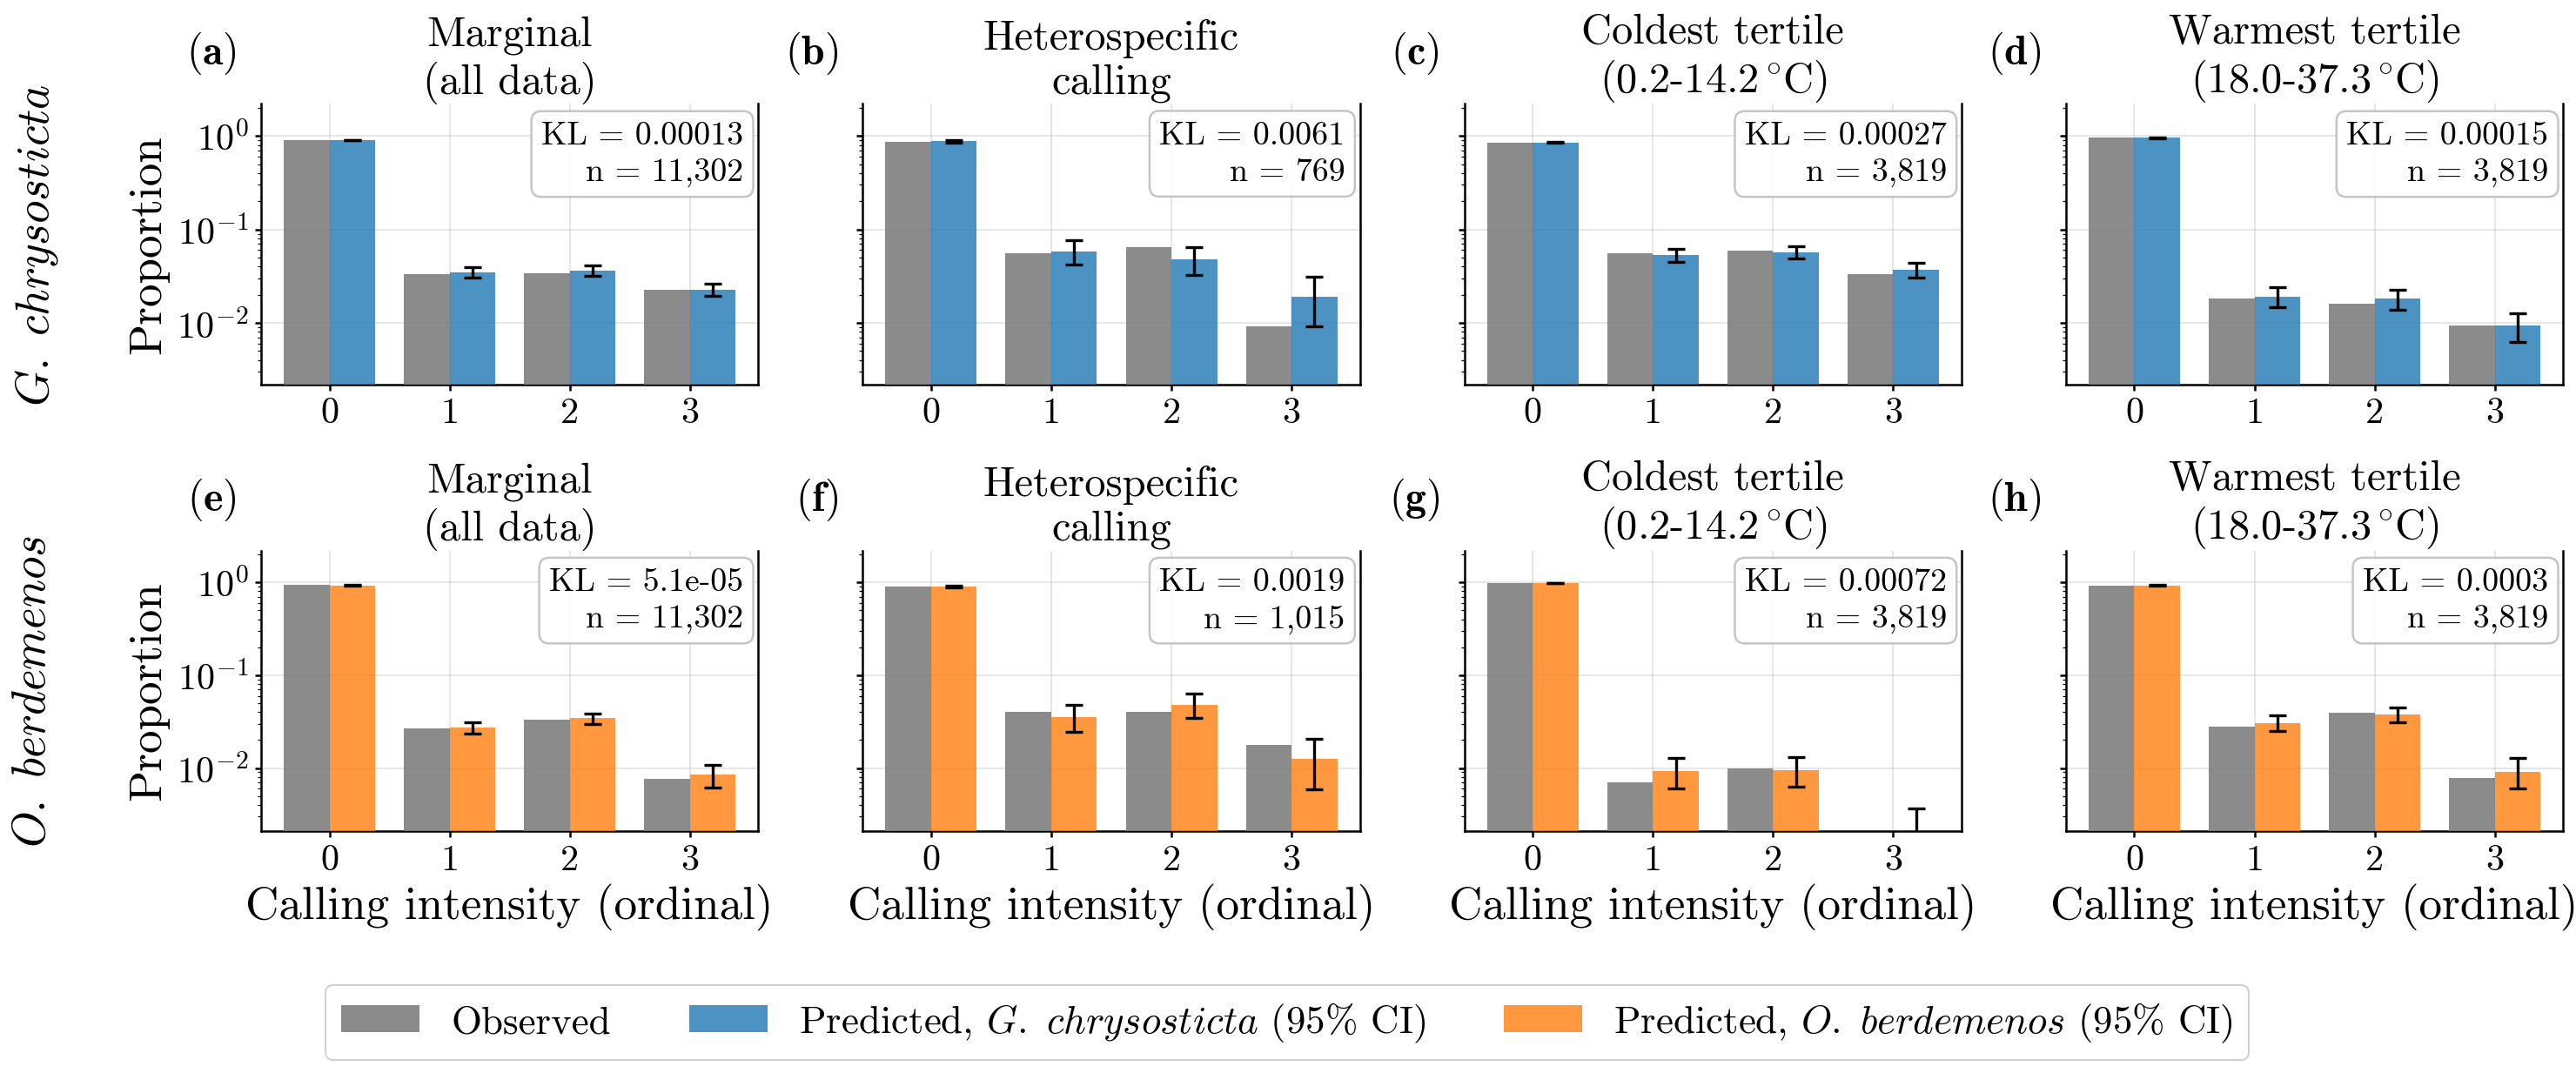

In [24]:
# ── Composite PPC figures for the supplement — model_4_ord ───────────────────
# Rows = species, columns = strata. The marginal panel is close to guaranteed to
# fit (a cumulative model with free thresholds reproduces the overall category
# frequencies by construction), so the columns that carry the evidence are the
# conditional ones: the rare heterospecific-calling stratum and the temperature
# extremes, none of which the likelihood was told to match.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

if "PPC_PANELS" not in globals() or not PPC_PANELS:
    raise RuntimeError("PPC_PANELS is empty — run the posterior predictive cell above first.")

PPC_ROWS      = [sp for sp in SPECIES if (sp, "marginal") in PPC_PANELS]
PPC_COLS_2x4  = ["marginal", "other_calling_bin=1", "temp_tertile_1", "temp_tertile_3"]

PANEL_W, PANEL_H = 5.0, 4.2
BAR_W            = 0.38
PPC_YSCALE       = "log"   # "linear" | "log" — log makes categories 1–3 legible

# One knob for all text in these composites: every size below is a notebook-wide
# FS_* value times PPC_FONT_SCALE, so raising this number enlarges panel titles,
# tick labels, axis labels, panel letters, the KL/n boxes and the legend alike.
PPC_FONT_SCALE = 1.35
FS_PPC_TITLE   = FS_TICK   * 1.15 * PPC_FONT_SCALE   # panel titles
FS_PPC_LABEL   = FS_LABEL  * 0.90 * PPC_FONT_SCALE   # x / y axis labels
FS_PPC_TICK    = FS_TICK   * 1.00 * PPC_FONT_SCALE   # tick labels
FS_PPC_NOTE    = FS_TICK   * 0.90 * PPC_FONT_SCALE   # KL / n annotation
FS_PPC_LETTER  = FS_TITLE  * 0.85 * PPC_FONT_SCALE   # panel letters
FS_PPC_ROW     = FS_TITLE  * 0.95 * PPC_FONT_SCALE   # species row labels
FS_PPC_LEG     = FS_LEGEND * 1.00 * PPC_FONT_SCALE   # shared legend


def _kl_fmt(kl):
    return f"{kl:.2g}"


def ppc_composite(col_scopes, fname, panel_w=PANEL_W, panel_h=PANEL_H):
    """Grid of PPC bar panels: one row per species, one column per stratum."""
    rows = PPC_ROWS
    cols = [c for c in col_scopes
            if all((sp, c) in PPC_PANELS for sp in rows)]
    missing = [c for c in col_scopes if c not in cols]
    if missing:
        print(f"  (skipping columns absent for one or more species: {missing})")
    if not rows or not cols:
        print("  Nothing to plot."); return None

    n_r, n_c = len(rows), len(cols)
    fig, axes = plt.subplots(n_r, n_c,
                            figsize=(panel_w * n_c, panel_h * n_r),
                            sharey="row", squeeze=False)

    letters = "abcdefghijklmnop"

    for r, sp in enumerate(rows):
        for c, scope in enumerate(cols):
            p  = PPC_PANELS[(sp, scope)]
            ax = axes[r][c]
            x  = np.arange(len(p["categories"]))

            ax.bar(x - BAR_W / 2, p["obs"], BAR_W, label="Observed",
                color="tab:gray", alpha=0.9, zorder=3)  # label unused (custom legend below)
            ax.bar(x + BAR_W / 2, p["mean"], BAR_W,
                yerr=[p["mean"] - p["lo"], p["hi"] - p["mean"]],
                label="_nolegend_",
                color=SP_COLOR[sp], alpha=0.8, capsize=CAPSIZE, zorder=3,
                error_kw={"elinewidth": LW_AUX, "capthick": LW_AUX})

            ax.set_xticks(x)
            ax.set_xticklabels([str(cc) for cc in p["categories"]], fontsize=FS_PPC_TICK)
            ax.set_title(p["short"], fontsize=FS_PPC_TITLE)
            ax.grid(alpha=0.3, lw=LW_GRID, zorder=0)
            ax.tick_params(labelsize=FS_PPC_TICK, width=LW_SPINE)
            if PPC_YSCALE == "log":
                ax.set_yscale("log")
                _pos = np.concatenate([p["obs"], p["mean"], p["lo"], p["hi"]])
                _pos = _pos[_pos > 0]
                ax.set_ylim(max(_pos.min() * 0.35, 1e-5), 2.2)
            else:
                ax.set_ylim(0, min(1.0, max(p["obs"].max(), p["hi"].max()) * 1.28))

            # KL + n, inside the panel
            ax.text(0.97, 0.94,
                    f"KL = {_kl_fmt(p['kl'])}\nn = {p['n']:,}",
                    transform=ax.transAxes, ha="right", va="top",
                    fontsize=FS_PPC_NOTE, linespacing=1.35, zorder=5,
                    bbox=dict(boxstyle="round,pad=0.3", fc="white",
                            ec="0.75", lw=LW_SPINE, alpha=0.9))

            # Panel letter. cmr10 has no bold face, so fontweight="bold" is a
            # silent no-op — mathtext (\bf via the cm fontset) is what actually
            # renders bold with this notebook's serif family.
            ax.text(-0.05, 1.10, r"$\mathbf{(%s)}$" % letters[r * n_c + c],
                    transform=ax.transAxes, ha="right", va="bottom",
                    fontsize=FS_PPC_LETTER)

            if c == 0:
                ax.set_ylabel("Proportion", fontsize=FS_PPC_LABEL)
            if r == n_r - 1:
                ax.set_xlabel("Calling intensity (ordinal)", fontsize=FS_PPC_LABEL)

    # Reserve room at the bottom for however many rows the shared legend needs.
    _n_leg     = 1 + len(rows)
    _leg_ncol  = _n_leg if n_c >= 3 else 2
    _leg_rows  = int(np.ceil(_n_leg / _leg_ncol))
    _bottom    = (0.35 + 0.42 * PPC_FONT_SCALE * _leg_rows) / (panel_h * n_r)
    fig.tight_layout(rect=[0.045, _bottom, 1, 1])

    # italic species label down the left of each row
    for r, sp in enumerate(rows):
        pos = axes[r][0].get_position()
        fig.text(0.012, (pos.y0 + pos.y1) / 2, mathit(SP_SHORT[sp]),
                rotation=90, va="center", ha="left",
                fontsize=FS_PPC_ROW)

    # Custom legend: the predicted bars are species-coloured, so give each row
    # its own swatch rather than letting the first row stand for both.
    handles = [Patch(facecolor="tab:gray", alpha=0.9, label="Observed")]
    handles += [Patch(facecolor=SP_COLOR[sp], alpha=0.8,
                    label=f"Predicted, {mathit(SP_SHORT[sp])} (95% CI)") for sp in rows]
    fig.legend(handles=handles, loc="lower center", ncol=_leg_ncol,
            bbox_to_anchor=(0.5, 0.0), frameon=True, framealpha=0.9,
            fontsize=FS_PPC_LEG)

    savefig(fig, fname)
    plt.show()
    return fig


print("2 × 4 composite (marginal | heterospecific calling | coldest | warmest tertile)")
_ = ppc_composite(PPC_COLS_2x4, "ppc_composite_2x4_model4ord")

## 7. Environmental response curves — model_4_ord

Temperature and humidity response curves with 95\u202f% posterior credible interval ribbons, held at midnight (hour\u202f=\u202f0) and species-specific representative day.

Gastrotheca chrysosticta: temperature range (2.5 - 97.5%) = 5.96 - 26.10 °C


Oreobates berdemenos: temperature range (2.5 - 97.5%) = 5.96 - 26.10 °C


  saved figures/Fig2_top_response_curves_temperature.pdf


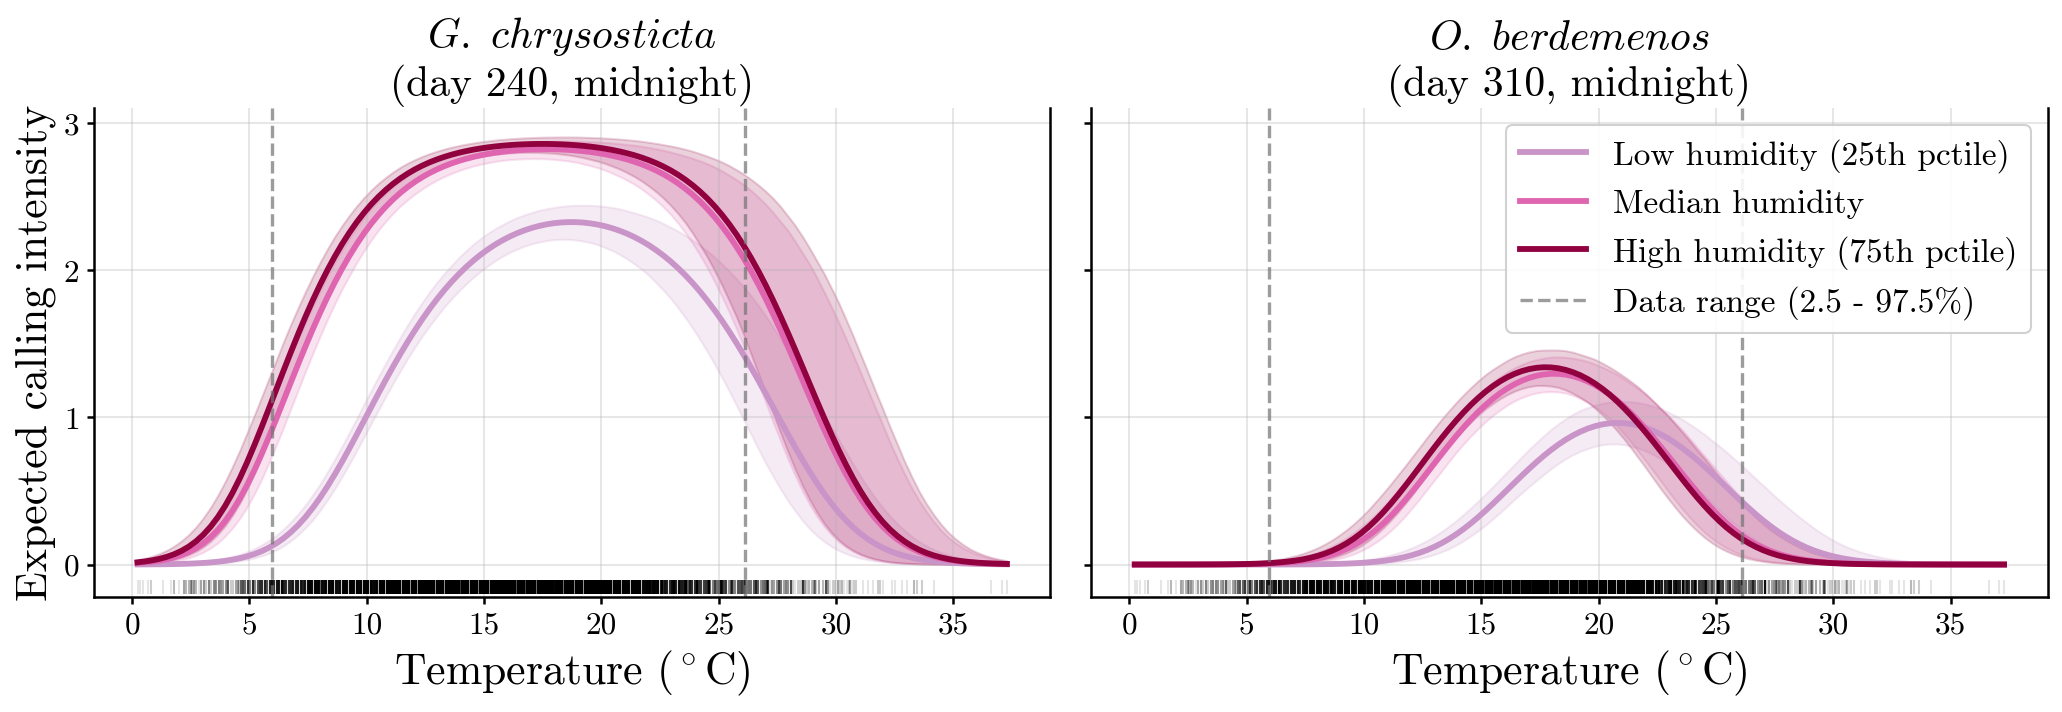

In [25]:
# ── Temperature response curves ───────────────────────────────────────────────
# Three humidity levels (25th / 50th / 75th percentile of observed rh_z),
# held at midnight and species-specific day-of-year.
# Toggles (also used by the humidity curves and the response surface below)
SHOW_ALE_DATA      = True   # True → overlay observations; False → clean curves
DATA_OVERLAY_STYLE = "rug"  # "rug" → tick marks | "density" → KDE strip
SHOW_PERCENTILE_LINES = True  # True → vertical lines at 2.5/97.5 pctile of observed variable

_RH_PALETTE  = ["#c994c7", "#df65b0", "#91003f"]   # light → dark purple
_RH_LABELS   = ["Low humidity (25th pctile)", "Median humidity", "High humidity (75th pctile)"]
_N_GRID      = 120

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, sp in zip(axes, SPECIES):
    norm   = SP_NORM[sp]
    df_sp  = species_data[sp]
    key    = (sp, "model_4_ord")

    if key not in bayes_idata or key not in bayes_bmb_models:
        ax.set_title(f"{mathit(SP_SHORT[sp])}: data not available")
        continue

    temp_z_grid = np.linspace(df_sp["temp_z"].min(), df_sp["temp_z"].max(), _N_GRID)
    rh_pcts     = np.percentile(df_sp["rh_z"], [25, 50, 75])

    for rh_z_fixed, color, label in zip(rh_pcts, _RH_PALETTE, _RH_LABELS):
        grid_df = make_grid_df(sp, temp_z_grid, np.full(_N_GRID, rh_z_fixed))
        ey      = predict_ey_draws(bayes_bmb_models[key], bayes_idata[key], grid_df)
        temp_c  = norm["temp_mean"] + temp_z_grid * norm["temp_std"]
        ey_mean = ey.mean(axis=0)
        ey_lo, ey_hi = np.percentile(ey, [2.5, 97.5], axis=0)
        ax.plot(temp_c, ey_mean, color=color, lw=LW_MAIN, label=label)
        ax.fill_between(temp_c, ey_lo, ey_hi, color=color, alpha=0.18)

    if SHOW_ALE_DATA:
        raw_t = norm["temp_mean"] + df_sp["temp_z"] * norm["temp_std"]
        if DATA_OVERLAY_STYLE == "rug":
            ax.plot(raw_t, np.full(len(raw_t), -0.15), "|",
                    color="k", alpha=0.1, ms=MS_RUG, mew=MEW_RUG)
        else:  # density
            from scipy.stats import gaussian_kde
            _kde = gaussian_kde(raw_t)
            _xf  = np.linspace(raw_t.min(), raw_t.max(), 300)
            _ys  = -0.25 + (_kde(_xf) / _kde(_xf).max()) * 0.24
            ax.fill_between(_xf, -0.25, _ys, color="k", alpha=0.15, label="Marginal density")
            ax.plot(_xf, _ys, color="k", lw=LW_AUX, alpha=0.4)

    if SHOW_PERCENTILE_LINES:
        _raw_t = norm["temp_mean"] + df_sp["temp_z"] * norm["temp_std"]
        _p025, _p975 = np.percentile(_raw_t, [2.5, 97.5])
        print(f"{sp}: temperature range (2.5 - 97.5%) = {_p025:.2f} - {_p975:.2f} °C")
        ax.axvline(_p025, color="0.45", lw=LW_AUX, ls="--", alpha=0.7,
                   label="Data range (2.5 - 97.5%)")
        ax.axvline(_p975, color="0.45", lw=LW_AUX, ls="--", alpha=0.7)

    ax.set_title(
        f"{mathit(SP_SHORT[sp])}\n(day {SP_FIXED[sp]['doy']}, midnight)",
        fontsize=FS_TITLE)
    ax.set_xlabel(r"Temperature ($^\circ$C)", fontsize=FS_LABEL)
    ax.set_ylim(-0.22, 3.1)
    ax.set_yticks([0, 1, 2, 3])
    if ax is axes[1]:
        ax.legend(framealpha=0.9, fontsize=FS_LEGEND)
    ax.grid(alpha=0.3, lw=LW_GRID)
    ax.tick_params(labelsize=FS_TICK, width=LW_SPINE)

axes[0].set_ylabel("Expected calling intensity", fontsize=FS_LABEL)
fig.tight_layout()
savefig(fig, "response_curves_temperature")
plt.show()

  saved figures/Fig2_bottom_response_curves_humidity.pdf


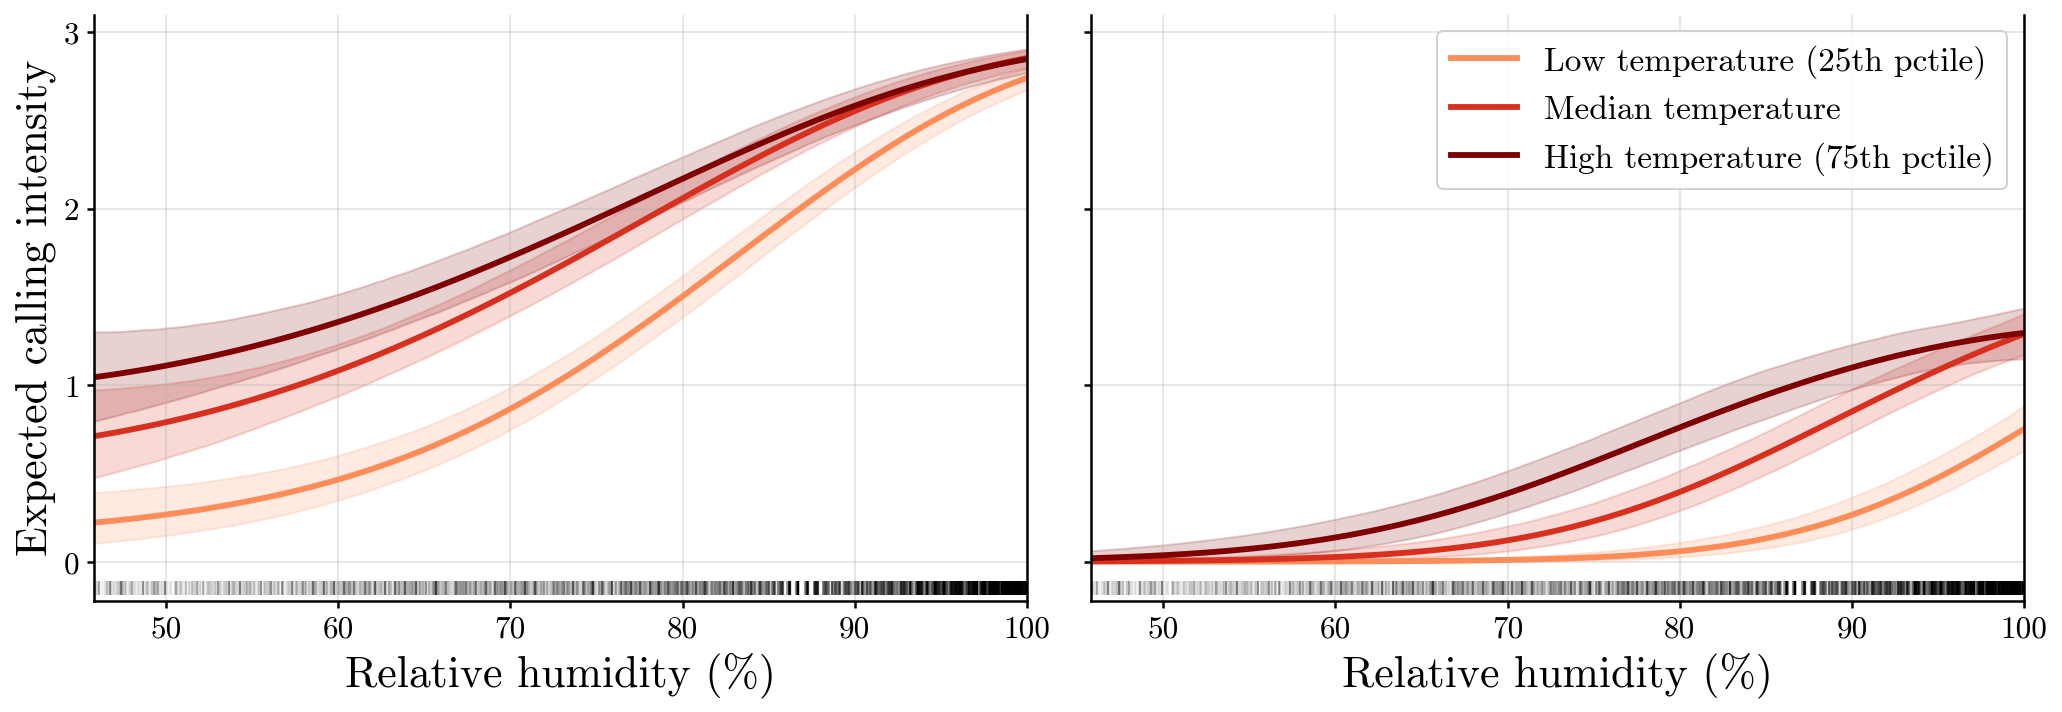

In [26]:
# ── Humidity response curves ──────────────────────────────────────────────────
# Three temperature levels (25th / 50th / 75th percentile of observed temp_z),
# held at midnight and species-specific day-of-year.

_TEMP_PALETTE = ["#fc8d59", "#d7301f", "#7f0000"]   # light → dark red/orange
_TEMP_LABELS  = ["Low temperature (25th pctile)", "Median temperature", "High temperature (75th pctile)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, sp in zip(axes, SPECIES):
    norm  = SP_NORM[sp]
    df_sp = species_data[sp]
    key   = (sp, "model_4_ord")

    if key not in bayes_idata or key not in bayes_bmb_models:
        ax.set_title(f"{mathit(SP_SHORT[sp])}: data not available")
        continue

    # x-range: 2.5th percentile of observed RH (lower) to observed maximum (upper)
    _rh_raw_sp = norm["rh_mean"] + df_sp["rh_z"] * norm["rh_std"]
    _rh_lo     = np.percentile(_rh_raw_sp, 2.5)
    rh_z_grid  = np.linspace((_rh_lo - norm["rh_mean"]) / norm["rh_std"],
                             df_sp["rh_z"].max(), _N_GRID)
    temp_pcts  = np.percentile(df_sp["temp_z"], [25, 50, 75])

    for temp_z_fixed, color, label in zip(temp_pcts, _TEMP_PALETTE, _TEMP_LABELS):
        grid_df = make_grid_df(sp, np.full(_N_GRID, temp_z_fixed), rh_z_grid)
        ey      = predict_ey_draws(bayes_bmb_models[key], bayes_idata[key], grid_df)
        rh_c    = norm["rh_mean"] + rh_z_grid * norm["rh_std"]
        ey_mean = ey.mean(axis=0)
        ey_lo, ey_hi = np.percentile(ey, [2.5, 97.5], axis=0)
        ax.plot(rh_c, ey_mean, color=color, lw=LW_MAIN, label=label)
        ax.fill_between(rh_c, ey_lo, ey_hi, color=color, alpha=0.18)

    if SHOW_ALE_DATA:
        raw_r = norm["rh_mean"] + df_sp["rh_z"] * norm["rh_std"]
        if DATA_OVERLAY_STYLE == "rug":
            ax.plot(raw_r, np.full(len(raw_r), -0.15), "|",
                    color="k", alpha=0.05, ms=MS_RUG, mew=MEW_RUG)
        else:  # density
            from scipy.stats import gaussian_kde
            _kde = gaussian_kde(raw_r)
            _xf  = np.linspace(raw_r.min(), raw_r.max(), 300)
            _ys  = -0.25 + (_kde(_xf) / _kde(_xf).max()) * 0.24
            ax.fill_between(_xf, -0.25, _ys, color="k", alpha=0.15, label="Marginal density")
            ax.plot(_xf, _ys, color="k", lw=LW_AUX, alpha=0.4)

    ax.set_xlabel("Relative humidity (%)", fontsize=FS_LABEL)
    ax.set_xlim(_rh_lo, df_sp["rh_z"].max() * norm["rh_std"] + norm["rh_mean"])
    ax.set_ylim(-0.22, 3.1)
    ax.set_yticks([0, 1, 2, 3])
    if ax is axes[1]:
        ax.legend(framealpha=0.9, fontsize=FS_LEGEND)
    ax.grid(alpha=0.3, lw=LW_GRID)
    ax.tick_params(labelsize=FS_TICK, width=LW_SPINE)

axes[0].set_ylabel("Expected calling intensity", fontsize=FS_LABEL)
fig.tight_layout()
savefig(fig, "response_curves_humidity")
plt.show()

Gastrotheca chrysosticta: plotting 10596,10596 observations within 2.5-97.5 percentile range.


Oreobates berdemenos: plotting 10596,10596 observations within 2.5-97.5 percentile range.


  saved figures/FigS3_response_surface_temp_rh.pdf


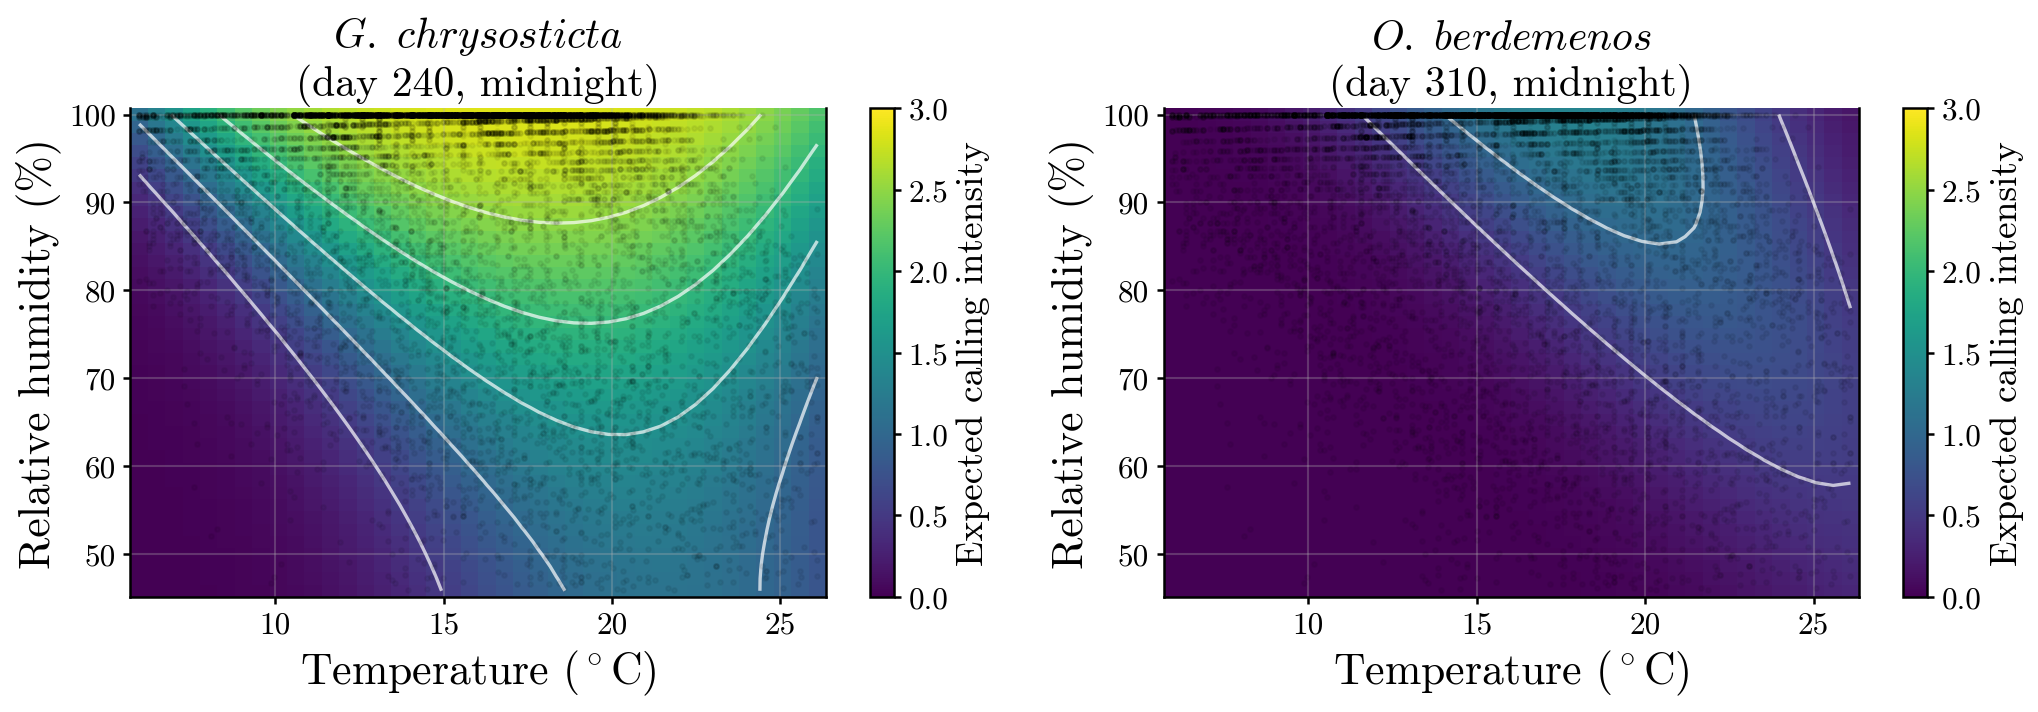

In [27]:
# ── 2-D posterior prediction surface ─────────────────────────────────────────
# Heatmap of posterior mean expected calling intensity over temperature x humidity.
# Held at midnight and species-specific day-of-year.
NINETY_5_ONLY = True   # True → only show 2.5/97.5 percentile of data; False → show full range of observed data

_N_SURF = 40   # grid resolution per axis

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, sp in zip(axes, SPECIES):
    norm  = SP_NORM[sp]
    df_sp = species_data[sp]
    key   = (sp, "model_4_ord")

    if key not in bayes_idata or key not in bayes_bmb_models:
        ax.set_title(f"{mathit(SP_SHORT[sp])}: data not available")
        continue

    if NINETY_5_ONLY:
        t_min, t_max = np.percentile(df_sp["temp_z"], [2.5, 97.5])
        r_min, r_max = np.percentile(df_sp["rh_z"],   [2.5, 97.5])
        t_z = np.linspace(t_min, t_max, _N_SURF)
        r_z = np.linspace(r_min, r_max, _N_SURF)
    else:
        t_z = np.linspace(df_sp["temp_z"].min(), df_sp["temp_z"].max(), _N_SURF)
        r_z = np.linspace(df_sp["rh_z"].min(),  df_sp["rh_z"].max(),  _N_SURF)
    TZ, RZ = np.meshgrid(t_z, r_z)                     # (N_SURF, N_SURF) each

    grid_df = make_grid_df(sp, TZ.ravel(), RZ.ravel())
    ey      = predict_ey_draws(bayes_bmb_models[key], bayes_idata[key], grid_df)
    ey_mean = ey.mean(axis=0).reshape(_N_SURF, _N_SURF)

    # Convert axes to original units
    TC = norm["temp_mean"] + TZ * norm["temp_std"]
    RC = norm["rh_mean"]   + RZ * norm["rh_std"]

    pm = ax.pcolormesh(TC, RC, ey_mean, cmap="viridis", vmin=0, vmax=3, shading="auto")
    ax.contour(TC, RC, ey_mean, levels=[0.5, 1.0, 1.5, 2.0, 2.5],
               colors="white", linewidths=LW_AUX, alpha=0.7)
    cb = fig.colorbar(pm, ax=ax)
    cb.set_label("Expected calling intensity", fontsize=FS_CBAR_LABEL)
    cb.ax.tick_params(labelsize=FS_CBAR_TICK, width=LW_SPINE)

    if SHOW_PERCENTILE_LINES and not NINETY_5_ONLY:
        _raw_r = norm["rh_mean"] + df_sp["rh_z"] * norm["rh_std"]
        _p025, _p975 = np.percentile(_raw_r, [2.5, 97.5])
        print(f"{sp}: humidity range (2.5 - 97.5%) = {_p025:.2f} - {_p975:.2f} %")
        ax.axhline(_p025, color="white", lw=LW_AUX, ls="--", alpha=0.7,
                   label="Data range (2.5 - 97.5%)")
        ax.axhline(_p975, color="white", lw=LW_AUX, ls="--", alpha=0.7)
        _raw_t = norm["temp_mean"] + df_sp["temp_z"] * norm["temp_std"]
        _p025, _p975 = np.percentile(_raw_t, [2.5, 97.5])
        print(f"{sp}: temperature range (2.5 - 97.5%) = {_p025:.2f} - {_p975:.2f} °C")
        ax.axvline(_p025, color="white", lw=LW_AUX, ls="--", alpha=0.7,
                   label="Data range (2.5 - 97.5%)")
        ax.axvline(_p975, color="white", lw=LW_AUX, ls="--", alpha=0.7)

    if SHOW_ALE_DATA and not NINETY_5_ONLY:
        raw_t = norm["temp_mean"] + df_sp["temp_z"] * norm["temp_std"]
        raw_r = norm["rh_mean"]   + df_sp["rh_z"]   * norm["rh_std"]
        ax.scatter(raw_t, raw_r, s=MS_SCATTER, color="k", alpha=0.06, zorder=3,
                   label="Observations")

    if SHOW_ALE_DATA and NINETY_5_ONLY: #remove points outside 2.5/97.5 percentile range
        raw_t = norm["temp_mean"] + df_sp["temp_z"] * norm["temp_std"]
        raw_r = norm["rh_mean"]   + df_sp["rh_z"]   * norm["rh_std"]
        _mask = (
            (raw_t >= np.percentile(raw_t, 2.5)) & (raw_t <= np.percentile(raw_t, 97.5)) &
            (raw_r >= np.percentile(raw_r, 2.5)) & (raw_r <= np.percentile(raw_r, 97.5))
        )
        raw_t, raw_r = raw_t[_mask], raw_r[_mask]
        print(f"{sp}: plotting {len(raw_t)},{len(raw_r)} observations within 2.5-97.5 percentile range.")
        ax.scatter(raw_t, raw_r, s=MS_SCATTER, color="k", alpha=0.06, zorder=3,
                   label="Observations")

    ax.set_title(
        f"{mathit(SP_SHORT[sp])}\n(day {SP_FIXED[sp]['doy']}, midnight)",
        fontsize=FS_TITLE)
    ax.set_xlabel(r"Temperature ($^\circ$C)", fontsize=FS_LABEL)
    ax.set_ylabel("Relative humidity (%)", fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK, width=LW_SPINE)

fig.tight_layout()
savefig(fig, "response_surface_temp_rh")
plt.show()

## 9. Seasonal overview: calling activity vs. temperature & humidity

  saved figures/Fig1_top_seasonal_calling_environment.pdf


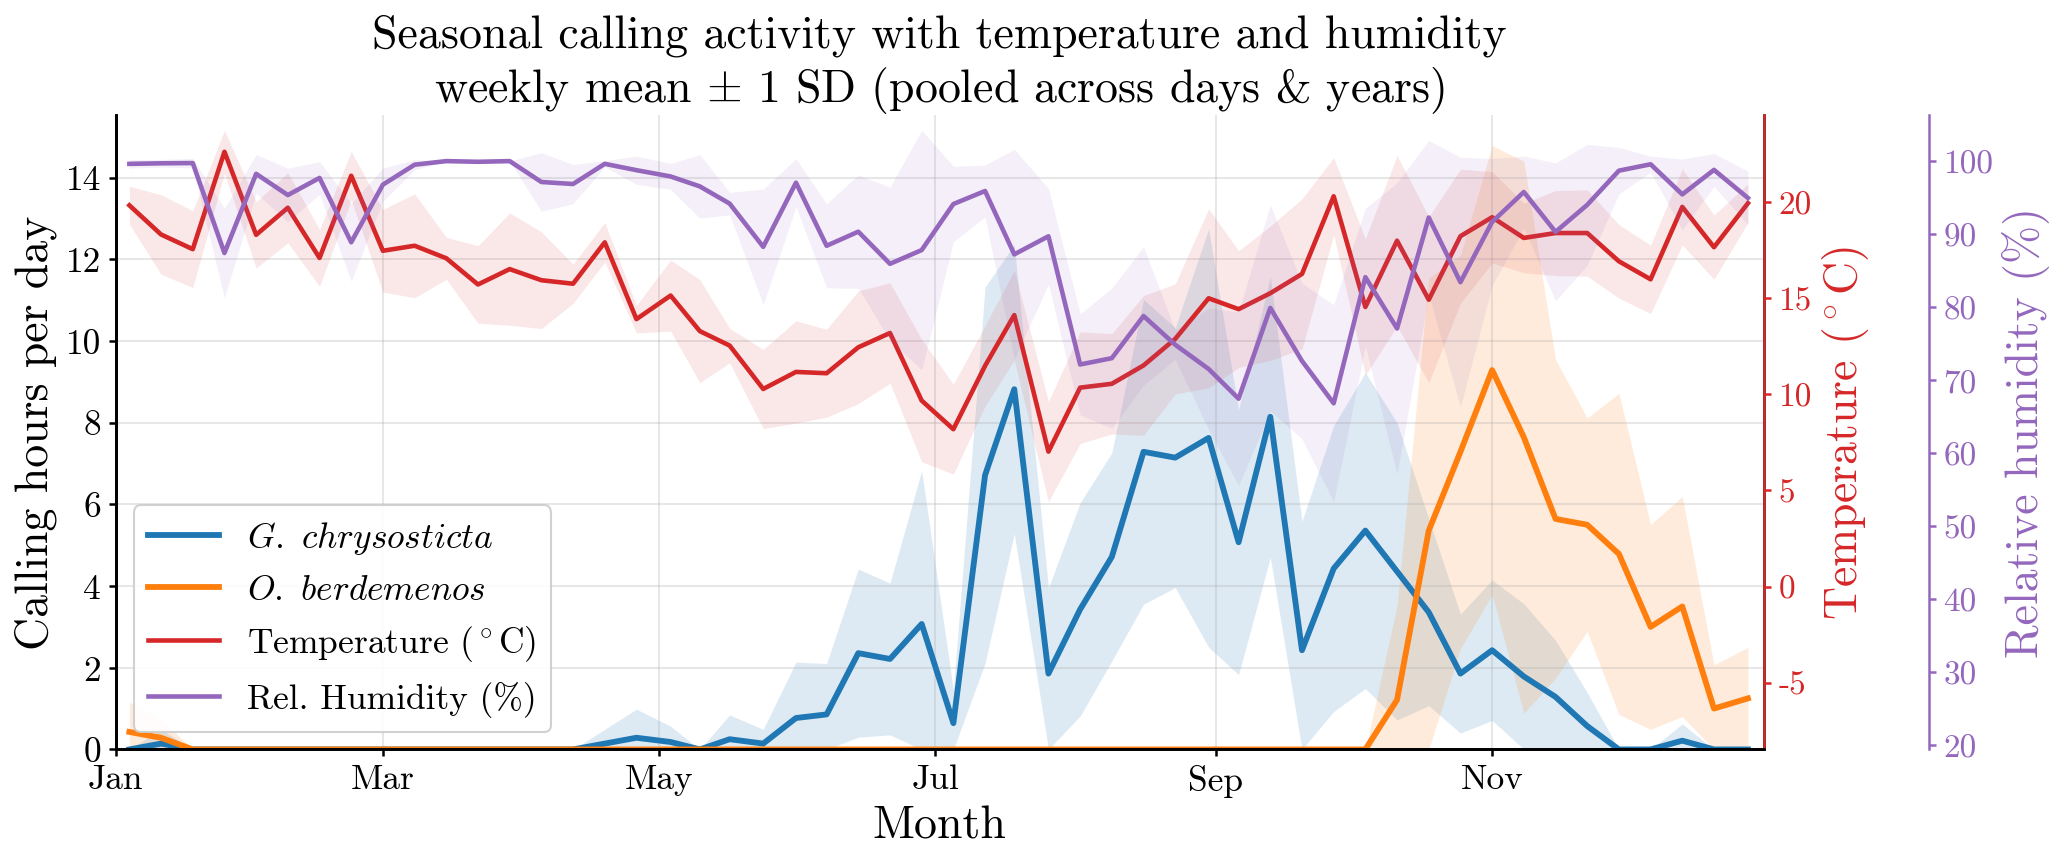

In [28]:
# ==================================================================
# SETTINGS
# ==================================================================
SMOOTH        = False   # True → light Gaussian smoothing of the weekly series
SMOOTH_SIGMA  = 1.0     # smoothing width in *weeks* (active only when SMOOTH=True)
ENV_TOP_FRAC  = 0.6     # fraction of plot height env. curves occupy (upper portion)
BAND_K        = 1.0     # envelope half-width in SD units (mean $\\pm$ BAND_K·SD)
# ==================================================================

import matplotlib as _mpl
from scipy.ndimage import gaussian_filter1d
_mpl.rcParams['axes.unicode_minus'] = False  # render − correctly on all axes

def mathit(s: str) -> str:
    return r"$\mathit{" + s.replace(" ", r"\ ") + "}$"

# ── Hourly → daily ────────────────────────────────────────────────
# Calling is scored ordinally (0 = silent, 1–3 = intensity). We binarise
# each hour to presence/absence, so the daily total is the NUMBER OF HOURS
# WITH CALLING (0–24) - a genuine count, not a sum of ordinal codes.
_d = df[[SPECIES[0], SPECIES[1], TEMP_COL, RH_COL]].copy()
_d['_doy'] = _d.index.dayofyear

_daily = (
    _d.groupby(_d.index.date)
    .agg(
        gastro=   (SPECIES[0], lambda s: (s > 0).sum()),
        oreo=     (SPECIES[1], lambda s: (s > 0).sum()),
        temp_mean=(TEMP_COL,   'mean'),
        rh_mean=  (RH_COL,     'mean'),
        doy=      ('_doy',     'first'),
    )
    .reset_index(drop=True)
)

# ── Assign week-of-year (1–52; trailing partial week folded into 52) ─
_daily['week'] = ((_daily['doy'] - 1) // 7 + 1).clip(upper=52)

# ── Weekly pooling across days AND years ─────────────────────────
# central line = mean daily value within the week;
# envelope     = mean $\\pm$ BAND_K·SD of the pooled daily values (≈7 days × years),
#                a real measure of day-to-day / inter-annual variability rather
#                than the range of the ≤2 observations available per day-of-year.
def _wk(col, clip0=False):
    g = _daily.groupby('week')[col]
    m, s = g.mean(), g.std(ddof=0).fillna(0.0)
    lo, hi = m - BAND_K * s, m + BAND_K * s
    if clip0:
        lo = lo.clip(lower=0)
    return m, lo, hi

_wx = _daily.groupby('week')['doy'].mean()          # week centre (day-of-year)

_gm, _glo, _ghi = _wk('gastro',    clip0=True)
_om, _olo, _ohi = _wk('oreo',      clip0=True)
_tm, _tlo, _thi = _wk('temp_mean')
_rm, _rlo, _rhi = _wk('rh_mean')

# ── Optional light smoothing of the weekly series ────────────────
def _sm(x):
    x = np.asarray(x, dtype=float)
    return gaussian_filter1d(x, sigma=SMOOTH_SIGMA, mode='wrap') if SMOOTH else x

_x = _wx.values
_gm, _glo, _ghi = _sm(_gm), _sm(_glo), _sm(_ghi)
_om, _olo, _ohi = _sm(_om), _sm(_olo), _sm(_ohi)
_tm, _tlo, _thi = _sm(_tm), _sm(_tlo), _sm(_thi)
_rm, _rlo, _rhi = _sm(_rm), _sm(_rlo), _sm(_rhi)

# ── Push env. curves to the upper portion of their axes ──────────
def _env_ylim(data_mn, data_mx, frac):
    rng = data_mx - data_mn
    return data_mn - rng * (1 - frac) / frac,  data_mx + rng * 0.04

_t_ylim = _env_ylim(np.min(_tlo), np.max(_thi), ENV_TOP_FRAC)
_r_ylim = _env_ylim(np.min(_rlo), np.max(_rhi), ENV_TOP_FRAC)

# ── Month ticks (every other month) ──────────────────────────────
_tick_pos    = [1, 60, 121, 182, 244, 305]
_tick_labels = ['Jan', 'Mar', 'May', 'Jul', 'Sep', 'Nov']

# ── Figure ───────────────────────────────────────────────────────
_fig, _ax1 = plt.subplots()
_ax2 = _ax1.twinx()
_ax3 = _ax1.twinx()
_ax3.spines['right'].set_position(('axes', 1.10))

# Gastrotheca chrysosticta
_ax1.fill_between(_x, _glo, _ghi, alpha=0.15, color=COLORS['gastro'], linewidth=0)
_l1, = _ax1.plot(_x, _gm, color=COLORS['gastro'], lw=LW_MAIN, label=mathit('G. chrysosticta'))

# Oreobates berdemenos
_ax1.fill_between(_x, _olo, _ohi, alpha=0.15, color=COLORS['oreo'], linewidth=0)
_l2, = _ax1.plot(_x, _om, color=COLORS['oreo'], lw=LW_MAIN, label=mathit('O. berdemenos'))
# Temperature
_ax2.fill_between(_x, _tlo, _thi, alpha=0.10, color=COLORS['temp'], linewidth=0)
_l3, = _ax2.plot(_x, _tm, color=COLORS['temp'], lw=LW_SECONDARY, label=r'Temperature ($^\circ$C)')
_ax2.set_ylim(*_t_ylim)

# Relative humidity
_ax3.fill_between(_x, _rlo, _rhi, alpha=0.10, color=COLORS['rh'], linewidth=0)
_l4, = _ax3.plot(_x, _rm, color=COLORS['rh'], lw=LW_SECONDARY, label='Rel. Humidity (%)')
_ax3.set_ylim(*_r_ylim)

# ── Axes formatting ───────────────────────────────────────────────
_ax1.set_xlim(1, 365)
_ax1.set_ylim(bottom=0)
_ax1.set_xticks(_tick_pos)
_ax1.set_xticklabels(_tick_labels, fontsize=FS_TICK+2)
_ax1.set_xlabel('Month', fontsize=FS_LABEL+1)
_ax1.set_ylabel('Calling hours per day', fontsize=FS_LABEL+1)
_ax1.tick_params(axis='both', labelsize=FS_TICK+2, width=LW_SPINE)
_ax1.spines['top'].set_visible(False)

_ax2.set_ylabel(r'Temperature ($^\circ$C)', color=COLORS['temp'], fontsize=FS_LABEL+1)
_ax2.tick_params(axis='y', colors=COLORS['temp'], labelsize=FS_TICK+1, width=LW_SPINE)
_ax2.spines['right'].set_color(COLORS['temp'])
_ax2.yaxis.label.set_color(COLORS['temp'])
_ax2.grid(False)

_ax3.set_ylabel('Relative humidity (%)', color=COLORS['rh'], fontsize=FS_LABEL+1)
_ax3.tick_params(axis='y', colors=COLORS['rh'], labelsize=FS_TICK+1, width=LW_SPINE)
_ax3.spines['right'].set_color(COLORS['rh'])
_ax3.yaxis.label.set_color(COLORS['rh'])
_ax3.grid(False)

# ── Legend ───────────────────────────────────────────────────────
_ax1.legend(
    [_l1, _l2, _l3, _l4], [_l.get_label() for _l in [_l1, _l2, _l3, _l4]],
    loc='lower left', framealpha=0.9, fontsize=FS_LEGEND+1,
)

# ── Title & save ─────────────────────────────────────────────────
_suffix = f' - smoothed ($\\sigma$ = {SMOOTH_SIGMA} weeks)' if SMOOTH else ''
_ax1.set_title(
    f'Seasonal calling activity with temperature and humidity{_suffix}\n'
    f'weekly mean $\\pm$ {BAND_K:g} SD (pooled across days & years)',
    fontsize=FS_TITLE+2,
)

_fig.tight_layout()
savefig(_fig, 'seasonal_calling_environment')
plt.show()

### 9.1 Diel structure of calling

Rose plot of the raw data: for each clock hour, the percentage of all recorded hours at that time with calling,
stacked by calling intensity (1–3). Midnight is at the top and time runs clockwise. This is the diel cycle that
the hour-of-day Fourier terms ($\sin/\cos$ of $2\pi h/24$ and $4\pi h/24$) absorb in every model, and the reason
calling hours cluster within nights, which is why leave-one-day-out is the more conservative test above.

G. chrysosticta  peak 20:00 (25.2% of hours);  18:00–05:59 holds 93% of the hourly calling rate
O. berdemenos    peak 20:00 (19.2% of hours);  18:00–05:59 holds 81% of the hourly calling rate


  saved figures/Fig1_bottom_diel_rose_calling.pdf


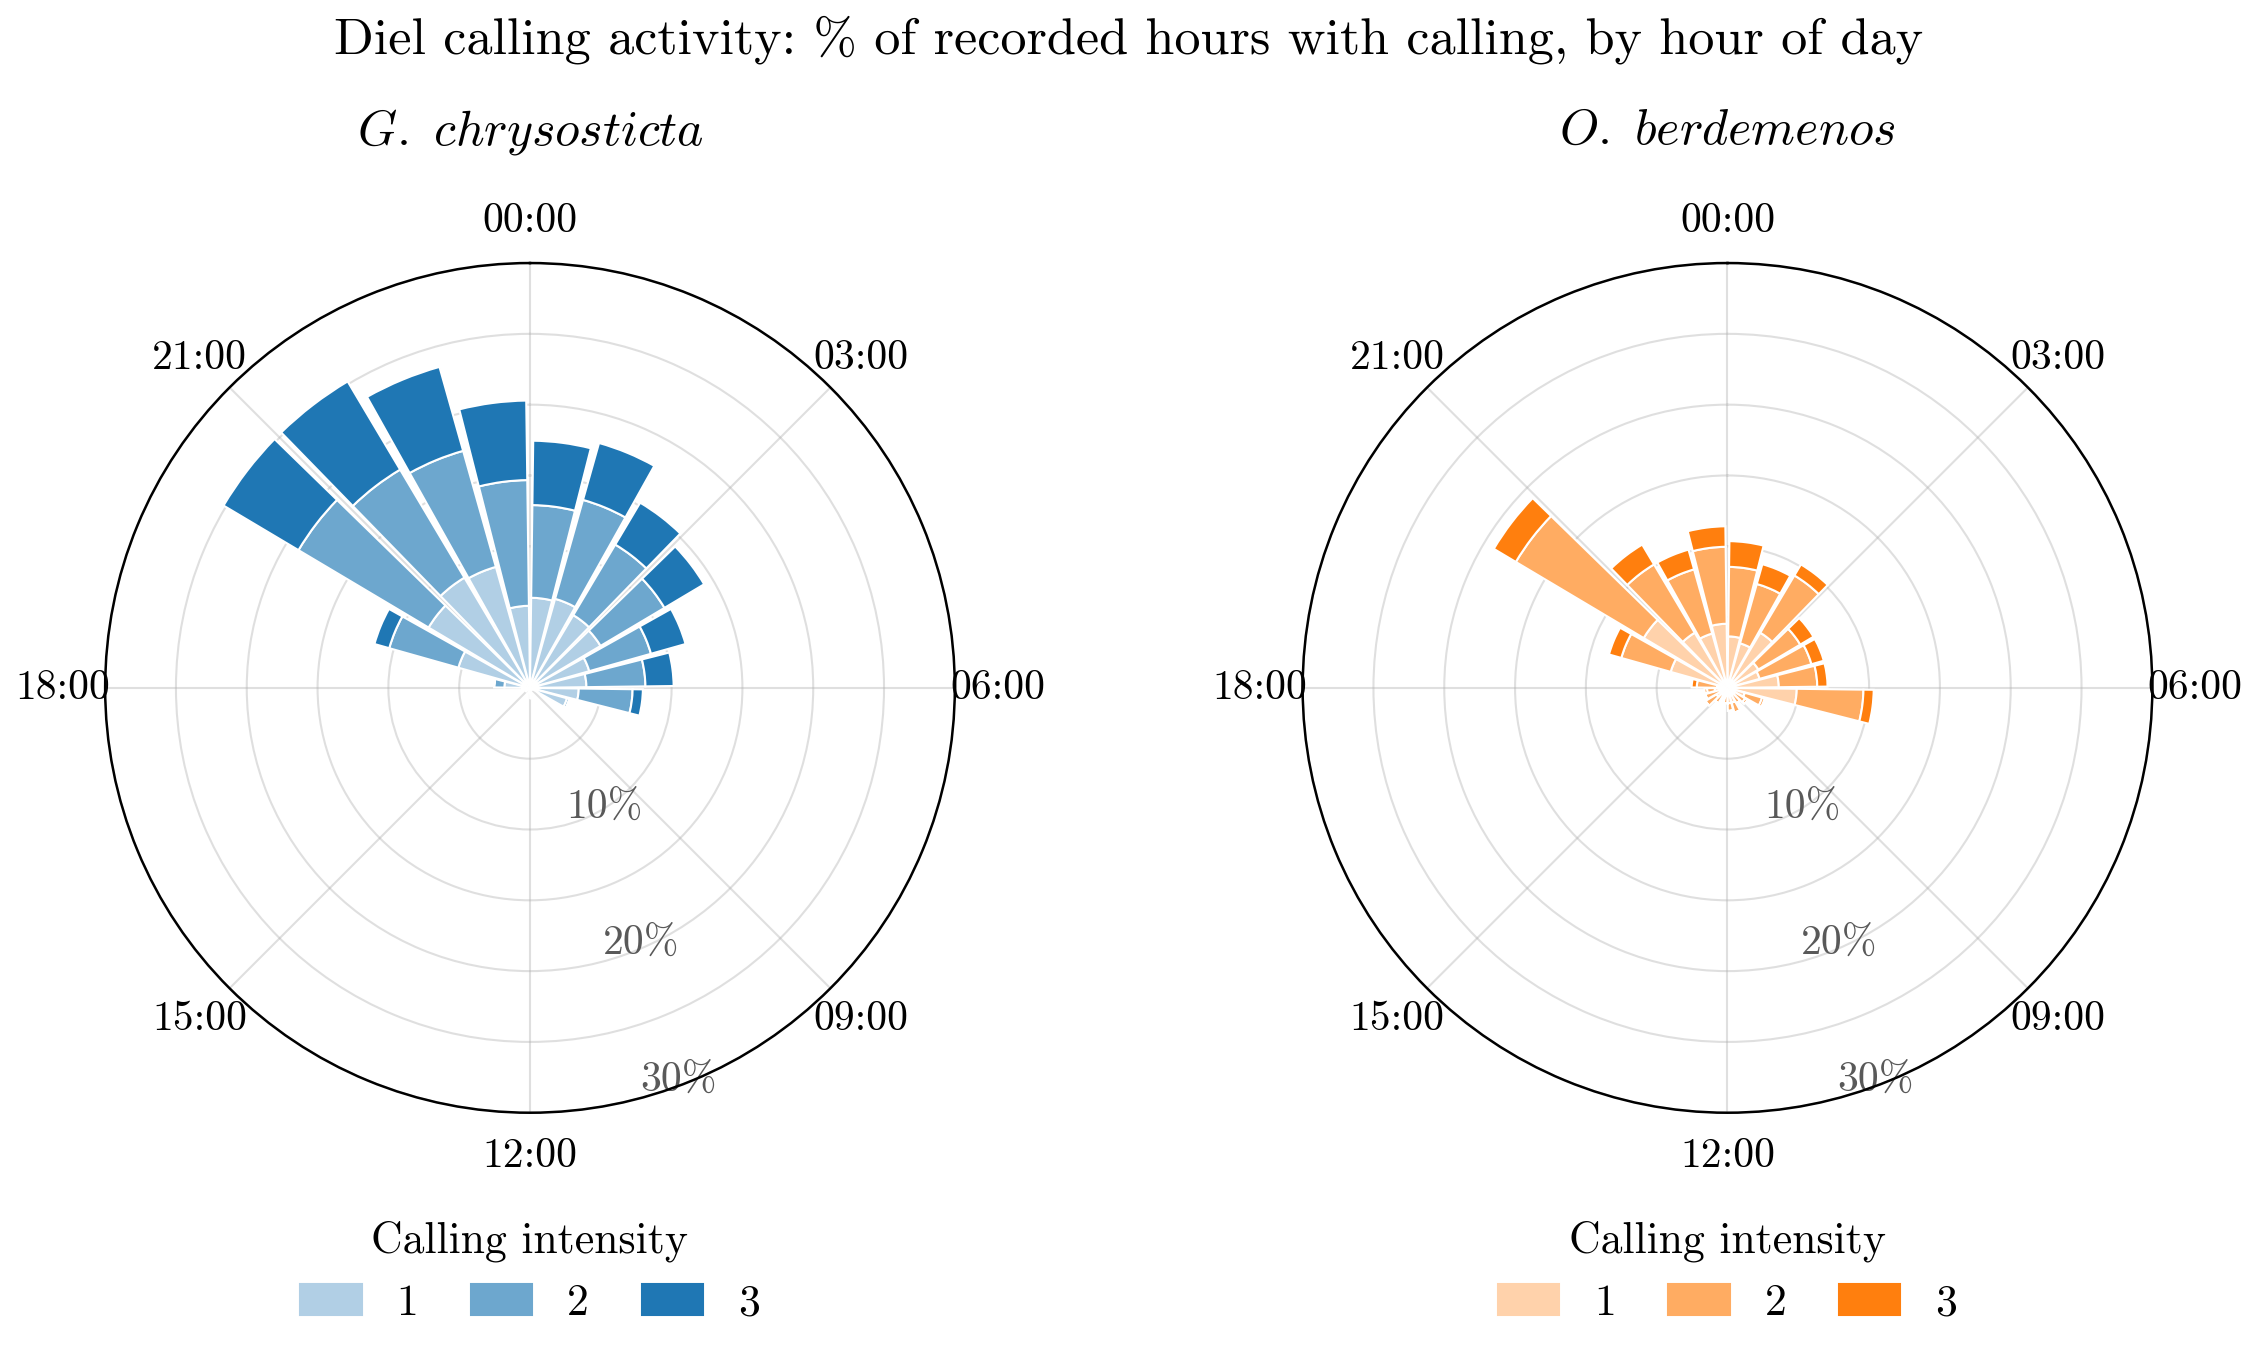

In [29]:
# ── Diel rose plot: share of recorded hours with calling, by hour of day ─────
# One bar per clock hour (hour h covers h:00–h:59, so bars sit between the hour
# ticks), midnight at the top, time running clockwise. Bar length = % of all
# recorded hours at that clock hour with calling, stacked by calling intensity.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROSE_SHADES = {1: 0.35, 2: 0.65, 3: 1.0}       # intensity → mix with white

def _shade(color, f):
    rgb = np.array(plt.matplotlib.colors.to_rgb(color))
    return tuple(1 - f * (1 - rgb))

_hr     = df.index.hour
_theta  = 2 * np.pi * (np.arange(24) + 0.5) / 24
_width  = 2 * np.pi / 24 * 0.9
FS_ROSE_TICK, FS_ROSE_LEGEND = FS_TICK + 5, FS_LEGEND + 5   # larger than the global defaults
FS_ROSE_TITLE, FS_ROSE_SUPTITLE = FS_TITLE + 4, FS_SUPTITLE + 4

rose_tbl = {}
for sp in SPECIES:
    s   = pd.to_numeric(df[sp], errors="coerce")
    n_h = s.groupby(_hr).count().reindex(range(24))
    rose_tbl[sp] = pd.DataFrame({lev: (s == lev).groupby(_hr).sum().reindex(range(24), fill_value=0) / n_h * 100
                                 for lev in ROSE_SHADES})
r_max = np.ceil(max(t.sum(axis=1).max() for t in rose_tbl.values()) / 5) * 5

fig, axes = plt.subplots(1, 2, figsize=(16, 8.4), subplot_kw={"projection": "polar"})
for ax, sp in zip(axes, SPECIES):
    tbl, base = rose_tbl[sp], np.zeros(24)
    for lev, f in ROSE_SHADES.items():
        ax.bar(_theta, tbl[lev].values, width=_width, bottom=base, color=_shade(SP_COLOR[sp], f),
               edgecolor="white", linewidth=LW_GRID, zorder=3)
        base += tbl[lev].values
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_xticks(2 * np.pi * np.arange(0, 24, 3) / 24)
    ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 3)], fontsize=FS_ROSE_TICK)
    ax.tick_params(axis="x", pad=10)
    ax.set_ylim(0, r_max)
    ax.set_yticks(np.arange(5, r_max + 1, 5))
    ax.set_yticklabels([f"{v:.0f}%" if v % 10 == 0 else "" for v in np.arange(5, r_max + 1, 5)],
                       fontsize=FS_ROSE_TICK, color="0.35")
    ax.set_rlabel_position(165)
    ax.grid(True, alpha=0.4, linewidth=LW_GRID)
    ax.spines["polar"].set_linewidth(LW_SPINE)
    ax.set_title(mathit(SP_SHORT[sp]), fontsize=FS_ROSE_TITLE, pad=28)
    ax.legend(handles=[Patch(color=_shade(SP_COLOR[sp], f), label=str(lev)) for lev, f in ROSE_SHADES.items()],
              title="Calling intensity", title_fontsize=FS_ROSE_LEGEND, fontsize=FS_ROSE_LEGEND, ncol=3,
              loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False, handlelength=1.4, columnspacing=1.2)
    peak = tbl.sum(axis=1)
    print(f"{SP_SHORT[sp]:16s} peak {peak.idxmax():02d}:00 ({peak.max():.1f}% of hours);  "
          f"18:00–05:59 holds {peak[list(range(18, 24)) + list(range(0, 6))].sum() / peak.sum() * 100:.0f}% of the hourly calling rate")

fig.suptitle("Diel calling activity: % of recorded hours with calling, by hour of day",
             fontsize=FS_ROSE_SUPTITLE, y=1.03)
fig.tight_layout(w_pad=2)
savefig(fig, "diel_rose_calling")
plt.show()

### 9.2 Temperature optima (Results 3.4)

In [30]:
# ── Temperature optima from the posterior ─────────────────────────────────
# Model: η = β₁·temp_z + β₂·temp_z² + β₃·(temp_z·rh_z) + ...
# dη/d(temp_z) = 0  →  temp_z* = -(β₁ + β₃·rh_z) / (2β₂)
# Evaluated at two reference humidities:
#   (a) median humidity: rh_z = 0 (z-scored, so median ≈ 0)
#   (b) marginalised: average optimum over observed rh_z distribution

_opt_rows = []

for sp in SPECIES:
    key = (sp, 'model_4_ord')
    if key not in bayes_idata:
        print(f'No idata for {sp} — run fitting cell first.')
        continue

    idata = bayes_idata[key]
    norm  = SP_NORM[sp]
    df_sp = species_data[sp]

    b1  = idata.posterior['temp_z'].values.ravel()          # β₁
    b2  = idata.posterior['I(temp_z ** 2)'].values.ravel()  # β₂
    b3  = idata.posterior['temp_z:rh_z'].values.ravel()     # β₃ (interaction)

    # (a) optimum at median humidity (rh_z = 0)
    _tz_med = -b1 / (2 * b2)
    _tc_med = norm['temp_mean'] + _tz_med * norm['temp_std']

    # (b) marginalised over observed rh_z values
    _rh_obs = df_sp['rh_z'].values
    # For each posterior draw, average the optimum over all observed rh_z
    _tz_marg = np.array([
        np.mean(-(b1[i] + b3[i] * _rh_obs) / (2 * b2[i]))
        for i in range(len(b1))
    ])
    _tc_marg = norm['temp_mean'] + _tz_marg * norm['temp_std']

    # Fraction of draws with β₂ < 0 (true maximum, not minimum)
    pct_concave = (b2 < 0).mean() * 100

    # HDI for each
    hdi_med  = az.hdi(_tc_med,  prob=0.95)
    hdi_marg = az.hdi(_tc_marg, prob=0.95)
    hdi_b1   = az.hdi(b1,  prob=0.95)
    hdi_b2   = az.hdi(b2,  prob=0.95)

    _opt_rows.append({
        'Species':                SP_SHORT[sp],
        'β₁ (temp) mean':        round(b1.mean(), 3),
        'β₁ 95% HDI':           f'[{hdi_b1[0]:.3f}, {hdi_b1[1]:.3f}]',
        'β₂ (temp²) mean':       round(b2.mean(), 3),
        'β₂ 95% HDI':           f'[{hdi_b2[0]:.3f}, {hdi_b2[1]:.3f}]',
        '% draws concave':        round(pct_concave, 1),
        'Optimum @ med. RH (°C)': round(_tc_med.mean(), 1),
        'Med. RH 95% HDI':       f'[{hdi_med[0]:.1f}, {hdi_med[1]:.1f}]',
        'Optimum marginal (°C)':  round(_tc_marg.mean(), 1),
        'Marginal 95% HDI':      f'[{hdi_marg[0]:.1f}, {hdi_marg[1]:.1f}]',
    })

_opt_df = pd.DataFrame(_opt_rows).set_index('Species').T
display(_opt_df)
_opt_df.to_csv(fc.TABLE_DIR / "Results3.4_temperature_optima.csv")

Species,G. chrysosticta,O. berdemenos
β₁ (temp) mean,0.865,1.84
β₁ 95% HDI,"[0.678, 1.043]","[1.505, 2.199]"
β₂ (temp²) mean,-0.781,-1.102
β₂ 95% HDI,"[-0.903, -0.637]","[-1.381, -0.827]"
% draws concave,100.0,100.0
Optimum @ med. RH (°C),18.3,19.8
Med. RH 95% HDI,"[17.5, 19.3]","[19.1, 20.5]"
Optimum marginal (°C),18.3,19.8
Marginal 95% HDI,"[17.5, 19.3]","[19.1, 20.5]"


## 10. Other statistics quoted in the text

* **Residual autocorrelation (Limitations).** Lag-1 autocorrelation of randomised-quantile (Dunn–Smyth)
  residuals of `model_4_ord`, computed from the posterior-mean category probabilities, on the complete
  hourly grid (pairs spanning a missing hour are excluded).
* **Diel and seasonal posterior predictive check (Results 3.5).** For each posterior draw the calling
  indicator (index ≥ 1) is simulated for every hour, then averaged by clock hour and by week of year;
  the correlation between observed and posterior-mean predicted proportions is reported.
* **In-season night hours above the temperature optimum (Discussion 4.4).** Share of analysed hours
  in the recommended survey windows (*G. chrysosticta* July–November, *O. berdemenos*
  October–December; 20:00–03:00) whose temperature exceeds the marginal optimum from Section 9.2.

In [31]:
from scipy.special import expit
from scipy.stats import norm as _norm_dist
from statsmodels.stats.diagnostic import acorr_ljungbox

TXT_SEED = 20261109
TXT_PREDICTORS = ["sin_h1", "cos_h1", "sin_h2", "cos_h2", "sin_d1", "cos_d1", "sin_d2", "cos_d2",
                  "temp_z", "rh_z", "I(temp_z ** 2)", "I(rh_z ** 2)", "temp_z:rh_z", "other_calling_ord"]


def _design(dm):
    X = pd.DataFrame(index=dm.index)
    for p in TXT_PREDICTORS:
        X[p] = {"I(temp_z ** 2)": lambda: dm.temp_z ** 2, "I(rh_z ** 2)": lambda: dm.rh_z ** 2,
                "temp_z:rh_z": lambda: dm.temp_z * dm.rh_z}.get(p, lambda: dm[p])()
    return X.values


def _category_probs(eta, tau):
    """Cumulative logit: P(Y <= k) = logistic(tau_k - eta)."""
    cum = expit(tau[:, None, :] - eta[:, :, None])
    S, N = eta.shape
    cdf = np.concatenate([np.zeros((S, N, 1)), cum, np.ones((S, N, 1))], axis=2)
    return np.diff(cdf, axis=2)


def _posterior_quantities(sp, chunk=250):
    dm, post = species_data[sp], bayes_idata[(sp, "model_4_ord")].posterior
    X = _design(dm)
    beta = np.stack([post[p].values.reshape(-1) for p in TXT_PREDICTORS], axis=1)
    tau = post["threshold"].values.reshape(-1, post["threshold"].shape[-1])
    S = beta.shape[0]
    pbar = np.zeros((len(dm), tau.shape[1] + 1))
    p_ge1 = np.empty((S, len(dm)), dtype=np.float32)
    for s0 in range(0, S, chunk):
        pr = _category_probs(beta[s0:s0 + chunk] @ X.T, tau[s0:s0 + chunk])
        pbar += pr.sum(0)
        p_ge1[s0:s0 + chunk] = 1 - pr[:, :, 0]
    return pbar / S, p_ge1


def _rq_residuals(y, pbar, seed):
    cdf = np.cumsum(pbar, axis=1)
    n = len(y)
    Fu = cdf[np.arange(n), y]
    Fl = np.where(y > 0, cdf[np.arange(n), np.maximum(y - 1, 0)], 0.0)
    u = Fl + np.random.default_rng(seed).uniform(size=n) * (Fu - Fl)
    return _norm_dist.ppf(np.clip(u, 1e-10, 1 - 1e-10))


def _gap_aware_acf(s, max_lag=48):
    full = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="h")).values
    v = full - np.nanmean(full)
    var = np.nanmean(v ** 2)
    out = []
    for h in range(1, max_lag + 1):
        a, b = v[h:], v[:-h]
        ok = ~np.isnan(a) & ~np.isnan(b)
        out.append(np.mean(a[ok] * b[ok]) / var)
    return np.array(out)


_txt_rows, _ppc_rows = [], []
for sp in SPECIES:
    dm = species_data[sp]
    pbar, p_ge1 = _posterior_quantities(sp)

    # Residual autocorrelation
    z = pd.Series(_rq_residuals(dm["response_code"].values, pbar, TXT_SEED), index=dm.index)
    acf = _gap_aware_acf(z, 48)
    lb = acorr_ljungbox(z.values, lags=[24], return_df=True)
    _txt_rows.append({"species": SP_SHORT[sp], "statistic": "residual lag-1 autocorrelation",
                      "value": round(float(acf[0]), 3)})
    _txt_rows.append({"species": SP_SHORT[sp], "statistic": "Ljung-Box p (24 lags)",
                      "value": float(lb["lb_pvalue"].iloc[0])})

    # Diel / seasonal PPC of P(calling index >= 1)
    rng = np.random.default_rng(TXT_SEED)
    obs = (dm["response_raw"].values > 0).astype(float)
    S, N = p_ge1.shape
    for gname, g in {"hour of day": dm["hour"].values,
                     "week of year": np.clip((dm["doy"].values - 1) // 7 + 1, None, 52)}.items():
        levels = np.unique(g)
        G = (g[:, None] == levels[None, :]).astype(np.float32)
        cnt = G.sum(0)
        rep = np.empty((S, len(levels)), dtype=np.float32)
        for s0 in range(0, S, 250):
            yrep = (rng.random((min(250, S - s0), N), dtype=np.float32) < p_ge1[s0:s0 + 250]).astype(np.float32)
            rep[s0:s0 + 250] = (yrep @ G) / cnt
        pred, o = (p_ge1.mean(0) @ G) / cnt, (obs @ G) / cnt
        lo, hi = np.percentile(rep, [2.5, 97.5], axis=0)
        _ppc_rows.append(pd.DataFrame({"species": SP_SHORT[sp], "grouping": gname, "level": levels,
                                       "observed": o, "pred_mean": pred, "pi_lo": lo, "pi_hi": hi}))
        _txt_rows.append({"species": SP_SHORT[sp], "statistic": f"PPC r(observed, predicted) by {gname}",
                          "value": round(float(np.corrcoef(o, pred)[0, 1]), 2)})

    # In-season night hours above the marginal temperature optimum
    _season = {"Gastrotheca chrysosticta": [7, 8, 9, 10, 11], "Oreobates berdemenos": [10, 11, 12]}[sp]
    _night = [20, 21, 22, 23, 0, 1, 2, 3]
    _opt = float(_opt_df.loc["Optimum marginal (°C)", SP_SHORT[sp]])
    _m = dm.index.month.isin(_season) & dm.index.hour.isin(_night)
    _T = pd.to_numeric(df.loc[dm.index[_m], TEMP_COL])
    _txt_rows.append({"species": SP_SHORT[sp],
                      "statistic": "% in-season night hours above the temperature optimum",
                      "value": round(100 * float((_T > _opt).mean()), 1)})

text_stats = pd.DataFrame(_txt_rows)
text_stats.to_csv(fc.TABLE_DIR / "Text_statistics.csv", index=False)
diel_seasonal_ppc = pd.concat(_ppc_rows, ignore_index=True)
diel_seasonal_ppc.to_csv(fc.TABLE_DIR / "supporting" / "diel_seasonal_ppc.csv", index=False)
text_stats.pivot(index="statistic", columns="species", values="value")

species,G. chrysosticta,O. berdemenos
statistic,,
% in-season night hours above the temperature optimum,2.140000e+01,1.950000e+01
Ljung-Box p (24 lags),5.837329e-25,1.845466e-75
"PPC r(observed, predicted) by hour of day",9.800000e-01,9.000000e-01
"PPC r(observed, predicted) by week of year",9.600000e-01,9.700000e-01
residual lag-1 autocorrelation,6.800000e-02,7.500000e-02


In [32]:
import sys, platform
import numpy, pandas, matplotlib, scipy, bambi, arviz, statsmodels, pymc, patsy

_pkgs = [
    ('Python',       platform.python_version()),
    ('NumPy',        numpy.__version__),
    ('pandas',       pandas.__version__),
    ('matplotlib',   matplotlib.__version__),
    ('SciPy',        scipy.__version__),
    ('statsmodels',  statsmodels.__version__),
    ('patsy',        patsy.__version__),
    ('PyMC',         pymc.__version__),
    ('Bambi',        bambi.__version__),
    ('ArviZ',        arviz.__version__),
]

print('Package versions')
print('=' * 30)
for _name, _ver in _pkgs:
    print(f'{_name:<16} {_ver}')

Package versions
Python           3.12.10
NumPy            2.3.2
pandas           2.3.2
matplotlib       3.10.6
SciPy            1.16.1
statsmodels      0.14.5
patsy            1.0.1
PyMC             6.0.1
Bambi            0.18.0
ArviZ            1.1.0
